# Proyecto #1 — Exploratory Data Analysis (EDA)
## Dataset: Predict Future Sales 

* Denisse Diaz - 25000924
* Cindy Raxjal - 14003771
* Bernard Zúñiga - 25005389

El dataset contiene las ventas diarias de una cadena de tiendas rusas (1C Company). El objetivo final de la competencia es
predecir las **ventas mensuales de cada par tienda-producto para noviembre de 2015**.

## 1. Estructura del proyecto y repositorio

- El proyecto se generó con la plantilla **Cookiecutter Data Science v2** (`ccds`): carpetas `data/` (raw, interim,
  processed, external), `notebooks/`, `models/`, `reports/figures/`, `references/`, `docs/` y el módulo `future_sales/`.
- El repositorio se versiona con **git** y se publica en **GitHub**. El `.gitignore` excluye los archivos de datos de
  Kaggle (~100 MB) en `data/`, conservando solo los `.gitkeep` para que la estructura de carpetas quede en el repositorio.
- Los archivos del dataset se descargan de Kaggle y se colocan en `data/raw/` (no se suben al repositorio).
- El entorno de ejecución es el entorno conda `future_sales` (Python 3.11); las librerías están en `requirements.txt`.
- **Idioma:** los nombres originales de productos, categorías y tiendas están en ruso. Se tradujeron al español y las
  traducciones se guardan en `references/` (`traduccion_tiendas.csv` y `traduccion_categorias.csv`: traducción manual;
  `traduccion_items.csv`: traducción automática de los 22,170 productos con correcciones manuales en los productos citados).
  Se generan con `python -m future_sales.traducciones`. Los títulos propios de películas, música o juegos pueden quedar
  traducidos de forma literal.

In [1]:
# ===== Configuración inicial: librerías, opciones y rutas =====
# Importamos las librerías del análisis, configuramos el formato de tablas/gráficas
# y definimos la ruta a los datos crudos (data/raw) de la estructura cookiecutter.
import warnings  # Para controlar mensajes de advertencia
from pathlib import Path  # Para manejar rutas de archivos de forma portable

import matplotlib.pyplot as plt  # Librería base de gráficas
import matplotlib.ticker as mtick  # Formateadores de ejes (miles, porcentajes)
import numpy as np  # Cálculo numérico
import pandas as pd  # Manipulación de datos tabulares
import seaborn as sns  # Gráficas estadísticas sobre matplotlib
from IPython.display import display  # Mostrar varias tablas dentro de una misma celda
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # Gráficos ACF y PACF
from statsmodels.tsa.seasonal import seasonal_decompose  # Descomposición tendencia/estacionalidad
from statsmodels.tsa.stattools import acf, pacf  # Valores numéricos de ACF y PACF

warnings.filterwarnings("ignore", category=FutureWarning)  # Ocultamos avisos de versiones futuras que no afectan resultados

pd.set_option("display.max_columns", 50)  # Mostrar hasta 50 columnas en las tablas
pd.set_option("display.width", 200)  # Ancho de impresión de tablas
pd.set_option("display.max_colwidth", 60)  # Truncar textos largos (nombres de productos)
pd.set_option("display.float_format", "{:,.2f}".format)  # Números con separador de miles y 2 decimales

sns.set_theme(style="whitegrid")  # Estilo limpio con cuadrícula para las gráficas
plt.rcParams["figure.figsize"] = (12, 5)  # Tamaño por defecto de las figuras
plt.rcParams["axes.titleweight"] = "bold"  # Títulos de gráficas en negrita

# Ruta a los datos: funciona si el notebook se ejecuta desde notebooks/ o desde la raíz del proyecto
DATA_RAW = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")
print("Carpeta de datos:", DATA_RAW.resolve())  # Confirmamos la ruta usada
print("Archivos disponibles:", sorted(p.name for p in DATA_RAW.glob("*.csv")))  # Listamos los CSV encontrados

Carpeta de datos: C:\Users\gabri\OneDrive\Documentos\0. Maestria Business Intelligence y Analytics - Galileo 2025-2026\4.1 Product Development\Proyecto_Future_Sales\data\raw
Archivos disponibles: ['item_categories.csv', 'items.csv', 'sales_train.csv', 'shops.csv', 'test.csv']


## 2. Comprensión inicial del dataset

### 2.a Carga de archivos y primeras filas

In [2]:
# ===== 2.a Carga de los archivos del dataset =====
# Leemos los 5 CSV de Kaggle desde data/raw. La columna date se lee tal cual (texto dd.mm.aaaa);
# su conversión a datetime se valida en la sección 3.
sales = pd.read_csv(DATA_RAW / "sales_train.csv")  # Ventas diarias históricas (train)
items = pd.read_csv(DATA_RAW / "items.csv")  # Catálogo de productos
item_categories = pd.read_csv(DATA_RAW / "item_categories.csv")  # Catálogo de categorías
shops = pd.read_csv(DATA_RAW / "shops.csv")  # Catálogo de tiendas
test = pd.read_csv(DATA_RAW / "test.csv")  # Pares tienda-producto a predecir (nov 2015)

# Diccionario con todas las tablas para recorrerlas de forma uniforme en las siguientes celdas
tablas = {
    "sales_train": sales,
    "items": items,
    "item_categories": item_categories,
    "shops": shops,
    "test": test,
}
print("Archivos cargados:", list(tablas))  # Confirmación de carga

Archivos cargados: ['sales_train', 'items', 'item_categories', 'shops', 'test']


In [3]:
# ===== 2.a Traducción de nombres del ruso al español =====
# Los nombres de productos, categorías y tiendas vienen en ruso. Los reemplazamos por su traducción al español,
# guardada en references/ (tiendas y categorías: traducción manual; productos: traducción automática con
# correcciones manuales, generada con future_sales/traducciones.py). Así todas las tablas y gráficas quedan en español.
REFERENCES = DATA_RAW.parent.parent / "references"  # Carpeta references/ de la estructura cookiecutter
tr_items = pd.read_csv(REFERENCES / "traduccion_items.csv")  # item_id -> nombre en español
tr_categorias = pd.read_csv(REFERENCES / "traduccion_categorias.csv")  # item_category_id -> nombre en español
tr_tiendas = pd.read_csv(REFERENCES / "traduccion_tiendas.csv")  # shop_id -> nombre en español

# Reemplazamos los nombres en ruso por los traducidos (modificación en las mismas tablas cargadas)
items["item_name"] = items["item_id"].map(tr_items.set_index("item_id")["item_name_es"])
item_categories["item_category_name"] = item_categories["item_category_id"].map(tr_categorias.set_index("item_category_id")["item_category_name_es"])
shops["shop_name"] = shops["shop_id"].map(tr_tiendas.set_index("shop_id")["shop_name_es"])

print("Nombres sin traducción -> productos:", items["item_name"].isna().sum(),  # Verificamos que no falte ninguno
      "| categorías:", item_categories["item_category_name"].isna().sum(),
      "| tiendas:", shops["shop_name"].isna().sum())
print("Abreviaturas en nombres de tiendas: CC = Centro Comercial; CCE = Centro Comercial y de Entretenimiento")

Nombres sin traducción -> productos: 0 | categorías: 0 | tiendas: 0
Abreviaturas en nombres de tiendas: CC = Centro Comercial; CCE = Centro Comercial y de Entretenimiento


In [4]:
# ===== 2.a Primeras filas de cada tabla =====
# Mostramos las primeras 5 filas de cada archivo para conocer su contenido y formato.
for nombre, tabla in tablas.items():  # Recorremos cada tabla
    print(f"\n=== {nombre} ===")  # Encabezado con el nombre del archivo
    display(tabla.head())  # Primeras 5 filas


=== sales_train ===


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00



=== items ===


,item_name,item_id,item_category_id
0,! BAJO EL PODER DE LA OBSESIÓN (PLÁSTICO) D,0,40
1,"!ABBYY FineReader 12 Professional Edition Full [PC, vers...",1,76
2,***EN LOS RAYOS DE GLORIA (VNU) D,2,40
3,***ONDA AZUL (Univ) D,3,40
4,***CAJA (VIDRIO) D,4,40



=== item_categories ===


,item_category_name,item_category_id
0,PC - Auriculares/Audífonos,0
1,Accesorios - PS2,1
2,Accesorios - PS3,2
3,Accesorios - PS4,3
4,Accesorios - PSP,4



=== shops ===


,shop_name,shop_id
0,"!Yakutsk Ordzhonikidze, 56 (franquicia)",0
1,"!Yakutsk CC ""Tsentralny"" (franquicia)",1
2,"Adygea CC ""Mega""",2
3,"Balashikha CCE ""Oktyabr-Kinomir""",3
4,"Volzhski CC ""Volga Mall""",4



=== test ===


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


### 2.b Tamaño de cada tabla

In [5]:
# ===== 2.b Tamaño de cada tabla (filas y columnas) =====
# Construimos una tabla resumen con el número de filas, columnas y la memoria usada por cada archivo.
tamanos = pd.DataFrame(
    {
        "filas": {n: t.shape[0] for n, t in tablas.items()},  # Número de filas
        "columnas": {n: t.shape[1] for n, t in tablas.items()},  # Número de columnas
        "memoria_MB": {n: t.memory_usage(deep=True).sum() / 1024**2 for n, t in tablas.items()},  # Memoria en MB
    }
)
tamanos["filas"] = tamanos["filas"].map("{:,}".format)  # Formato con separador de miles
tamanos

,filas,columnas,memoria_MB
sales_train,"2,935,849",6,299.58
items,"22,170",3,2.70
item_categories,84,2,0.01
shops,60,2,0.01
test,"214,200",3,4.90


**Interpretación 2.b:** `sales_train` es la tabla principal con **2,935,849 transacciones** y 6 columnas (~300 MB en memoria).
Los catálogos son pequeños: **22,170 productos**, **84 categorías** y **60 tiendas**. `test.csv` tiene **214,200 pares**
tienda-producto a predecir.

### 2.c Descripción de las columnas y variable objetivo

In [6]:
# ===== 2.c Valores únicos y ejemplos por columna =====
# Para respaldar la descripción de cada columna, mostramos su tipo, número de valores únicos y un ejemplo real.
resumen_columnas = []  # Lista donde acumulamos una fila por columna
for nombre, tabla in tablas.items():  # Recorremos cada tabla
    for col in tabla.columns:  # Recorremos cada columna
        resumen_columnas.append(
            {
                "tabla": nombre,  # Archivo de origen
                "columna": col,  # Nombre de la columna
                "valores_unicos": tabla[col].nunique(),  # Cantidad de valores distintos
                "ejemplo": tabla[col].iloc[0],  # Primer valor como ejemplo
            }
        )
pd.DataFrame(resumen_columnas)  # Mostramos el resumen

,tabla,columna,valores_unicos,ejemplo
0,sales_train,date,1034,02.01.2013
1,sales_train,date_block_num,34,0
2,sales_train,shop_id,60,59
3,sales_train,item_id,21807,22154
4,sales_train,item_price,19993,999.00
5,sales_train,item_cnt_day,198,1.00
6,items,item_name,22136,! BAJO EL PODER DE LA OBSESIÓN (PLÁSTICO) D
7,items,item_id,22170,0
8,items,item_category_id,84,40
9,item_categories,item_category_name,84,PC - Auriculares/Audífonos


| Columna | Archivo(s) | Descripción |
|---|---|---|
| `date` | sales_train | Fecha de la transacción (texto con formato `dd.mm.aaaa`). |
| `date_block_num` | sales_train | Número de mes consecutivo: 0 = enero 2013, …, 33 = octubre 2015. |
| `shop_id` | sales_train, shops, test | Identificador único de la tienda (sucursal). |
| `item_id` | sales_train, items, test | Identificador único del producto. |
| `item_price` | sales_train | Precio unitario del producto en esa transacción (rublos). |
| `item_cnt_day` | sales_train | Unidades vendidas del producto en la tienda ese día; los valores negativos son devoluciones. |
| `item_name` | items | Nombre del producto (original en ruso; aquí traducido al español). |
| `item_category_id` | items, item_categories | Identificador de la categoría del producto. |
| `item_category_name` | item_categories | Nombre de la categoría con formato `Familia - Subcategoría` (original en ruso; aquí traducido). |
| `shop_name` | shops | Nombre de la tienda: ciudad + centro comercial (original en ruso; aquí traducido). |
| `ID` | test | Identificador de la fila del archivo de prueba (par tienda-producto a predecir). |

**Variable objetivo:** la competencia pide predecir las **ventas mensuales en unidades** de cada par tienda-producto, es decir,
`item_cnt_day` **sumada por mes** para cada (`shop_id`, `item_id`) — conocida como `item_cnt_month` — para noviembre de 2015
(`date_block_num` = 34). Como el dataset no trae ventas en dinero, se construye la variable de **ingresos**
`revenue = item_price × item_cnt_day`, que se usa como métrica complementaria del análisis.

### 2.d Rango temporal de los datos

In [7]:
# ===== 2.d Rango temporal (fecha mínima, máxima y meses cubiertos) =====
# Convertimos temporalmente la fecha (formato dd.mm.aaaa) solo para calcular el rango;
# la conversión definitiva de la columna se valida en la sección 3.b.
fechas = pd.to_datetime(sales["date"], format="%d.%m.%Y")  # Texto -> datetime con el formato del archivo
print("Fecha mínima:", fechas.min().date())  # Primera fecha con ventas
print("Fecha máxima:", fechas.max().date())  # Última fecha con ventas
print("Días calendario en el rango:", (fechas.max() - fechas.min()).days + 1)  # Días entre ambas fechas (inclusive)
print("Meses distintos (date_block_num):", sales["date_block_num"].nunique())  # Número de meses cubiertos
print("Rango de date_block_num:", sales["date_block_num"].min(), "a", sales["date_block_num"].max())  # 0 a 33
print("Meses calendario distintos:", fechas.dt.to_period("M").nunique())  # Verificación con el calendario

Fecha mínima: 2013-01-01
Fecha máxima: 2015-10-31
Días calendario en el rango: 1034
Meses distintos (date_block_num): 34
Rango de date_block_num: 0 a 33


Meses calendario distintos: 34


**Interpretación 2.d:** los datos van del **1 de enero de 2013 al 31 de octubre de 2015**: 1,034 días y **34 meses**
(`date_block_num` de 0 a 33), lo que coincide con los 34 meses calendario. El mes a predecir (noviembre 2015) es
`date_block_num = 34`, el mes inmediatamente siguiente al último observado.

## 3. Validación de la estructura de los datos

### 3.a Tipos de datos de cada variable

In [8]:
# ===== 3.a Tipos de datos: tipo en pandas vs. tipo semántico =====
# Comparamos el tipo con el que pandas leyó cada columna con su naturaleza real (fecha, numérica o categórica).
# Los identificadores (*_id) son números pero representan categorías, no cantidades.
tipo_semantico = {  # Clasificación semántica de cada columna
    "date": "fecha", "date_block_num": "temporal (índice de mes)", "shop_id": "categórica (ID)",
    "item_id": "categórica (ID)", "item_price": "numérica continua", "item_cnt_day": "numérica discreta",
    "item_name": "categórica (texto)", "item_category_id": "categórica (ID)",
    "item_category_name": "categórica (texto)", "shop_name": "categórica (texto)", "ID": "identificador de fila",
}
tipos = []  # Acumulamos una fila por columna
for nombre, tabla in tablas.items():  # Recorremos cada tabla
    for col, dtype in tabla.dtypes.items():  # Recorremos columnas con su tipo pandas
        tipos.append({"tabla": nombre, "columna": col, "tipo_pandas": str(dtype), "tipo_semantico": tipo_semantico[col]})
pd.DataFrame(tipos)  # Mostramos la tabla de tipos

,tabla,columna,tipo_pandas,tipo_semantico
0,sales_train,date,str,fecha
1,sales_train,date_block_num,int64,temporal (índice de mes)
2,sales_train,shop_id,int64,categórica (ID)
3,sales_train,item_id,int64,categórica (ID)
4,sales_train,item_price,float64,numérica continua
5,sales_train,item_cnt_day,float64,numérica discreta
6,items,item_name,str,categórica (texto)
7,items,item_id,int64,categórica (ID)
8,items,item_category_id,int64,categórica (ID)
9,item_categories,item_category_name,str,categórica (texto)


**Interpretación 3.a:**
- `date` se leyó como **texto** (`str`), por lo que debe convertirse a datetime (3.b).
- Los identificadores (`shop_id`, `item_id`, `item_category_id`) se leyeron como enteros, pero son **variables categóricas**:
  no tiene sentido sumarlos ni promediarlos.
- `item_cnt_day` se leyó como `float64` aunque representa unidades enteras (en 4.b.4 se confirma que no hay decimales).
- `item_price` es la única variable numérica continua; los nombres (`item_name`, `item_category_name`, `shop_name`) son
  texto categórico (originalmente en ruso; en 2.a se reemplazaron por su traducción al español).

### 3.b Conversión de `date` a datetime

In [9]:
# ===== 3.b Conversión de la columna date a datetime =====
# La fecha viene como texto dd.mm.aaaa. La convertimos con el formato explícito y errors="coerce"
# para que cualquier valor mal formado quede como NaT (nulo) y podamos detectarlo.
print("Tipo original de date:", sales["date"].dtype)  # Tipo antes de la conversión
print("Ejemplos originales:", sales["date"].head(3).tolist())  # Valores de texto originales
sales["date"] = pd.to_datetime(sales["date"], format="%d.%m.%Y", errors="coerce")  # Conversión a datetime
print("Tipo después de convertir:", sales["date"].dtype)  # Debe ser datetime64
print("Fechas no convertibles (NaT):", sales["date"].isna().sum())  # 0 = todas las fechas tenían el formato correcto
print("Ejemplos convertidos:", sales["date"].head(3).dt.strftime("%Y-%m-%d").tolist())  # Verificación visual

Tipo original de date: str
Ejemplos originales: ['02.01.2013', '03.01.2013', '05.01.2013']


Tipo después de convertir: datetime64[us]
Fechas no convertibles (NaT): 0
Ejemplos convertidos: ['2013-01-02', '2013-01-03', '2013-01-05']


**Interpretación 3.b:** la columna `date` quedó convertida a `datetime64` usando el formato explícito `%d.%m.%Y`.
**Ninguna fecha** quedó como NaT, es decir, todas las filas tenían el formato `dd.mm.aaaa` correcto.

### 3.c Frecuencia temporal: días sin ventas y consistencia de `date_block_num`

In [10]:
# ===== 3.c.1 Días sin ventas a nivel de toda la cadena =====
# Generamos el calendario completo entre la fecha mínima y máxima y buscamos los días que no aparecen en los datos.
calendario = pd.date_range(sales["date"].min(), sales["date"].max(), freq="D")  # Todos los días del rango
dias_con_ventas = pd.DatetimeIndex(sales["date"].unique())  # Días que sí tienen transacciones
dias_sin_ventas = calendario.difference(dias_con_ventas)  # Días del calendario sin transacciones
print("Días en el calendario:", len(calendario))  # Total de días del rango
print("Días con ventas:", len(dias_con_ventas))  # Días con al menos una transacción
print("Días sin ventas en toda la cadena:", len(dias_sin_ventas), list(dias_sin_ventas.date))  # Lista de días faltantes

Días en el calendario: 1034
Días con ventas: 1034
Días sin ventas en toda la cadena: 0 []


In [11]:
# ===== 3.c.2 Días sin ventas por tienda =====
# Aunque la cadena vende todos los días, cada tienda puede tener días sin registro.
# Calculamos, para cada tienda, cuántos días dentro de su periodo activo (primera a última venta) no tienen ventas.
dias_tienda = sales.groupby("shop_id")["date"].agg(primera="min", ultima="max", dias_con_venta="nunique")  # Resumen por tienda
dias_tienda["dias_periodo"] = (dias_tienda["ultima"] - dias_tienda["primera"]).dt.days + 1  # Días entre primera y última venta
dias_tienda["dias_sin_venta"] = dias_tienda["dias_periodo"] - dias_tienda["dias_con_venta"]  # Huecos dentro del periodo activo
dias_tienda["pct_dias_sin_venta"] = dias_tienda["dias_sin_venta"] / dias_tienda["dias_periodo"] * 100  # Porcentaje de huecos
print("Tiendas con al menos un día sin ventas en su periodo activo:", (dias_tienda["dias_sin_venta"] > 0).sum(), "de", len(dias_tienda))
dias_tienda.sort_values("pct_dias_sin_venta", ascending=False).head(10)  # Tiendas con más huecos

Tiendas con al menos un día sin ventas en su periodo activo: 49 de 60


,primera,ultima,dias_con_venta,dias_periodo,dias_sin_venta,pct_dias_sin_venta
shop_id,,,,,,
9,2013-10-03,2015-10-14,14,742,728,98.11
20,2014-10-02,2015-10-04,9,368,359,97.55
12,2013-01-03,2015-10-30,826,1031,205,19.88
33,2014-08-29,2015-04-24,201,239,38,15.90
27,2013-01-01,2015-09-30,899,1003,104,10.37
8,2013-01-01,2013-04-01,84,91,7,7.69
10,2013-01-02,2015-10-31,1001,1033,32,3.10
4,2013-01-02,2015-10-31,1010,1033,23,2.23
24,2013-01-02,2015-10-31,1012,1033,21,2.03


In [12]:
# ===== 3.c.3 Consistencia de date_block_num con la fecha =====
# Calculamos el número de mes esperado a partir de la fecha: (año - 2013) * 12 + (mes - 1),
# y lo comparamos con date_block_num. También verificamos que cada bloque corresponda a un solo mes calendario.
bloque_esperado = (sales["date"].dt.year - 2013) * 12 + sales["date"].dt.month - 1  # Mes consecutivo calculado
print("Filas donde date_block_num NO coincide con la fecha:", (bloque_esperado != sales["date_block_num"]).sum())

bloques = sales.groupby("date_block_num")["date"].agg(inicio="min", fin="max", dias_con_venta="nunique")  # Rango de fechas por bloque
bloques["meses_calendario"] = sales.groupby("date_block_num")["date"].apply(lambda d: d.dt.to_period("M").nunique())  # Meses distintos por bloque
bloques["dias_del_mes"] = bloques["inicio"].dt.days_in_month  # Días que tiene ese mes
print("Bloques que abarcan más de un mes calendario:", (bloques["meses_calendario"] > 1).sum())
print("Bloques con días faltantes:", (bloques["dias_con_venta"] < bloques["dias_del_mes"]).sum())
bloques.head(12)  # Primeros 12 bloques como muestra

Filas donde date_block_num NO coincide con la fecha: 0


Bloques que abarcan más de un mes calendario: 0
Bloques con días faltantes: 0


,inicio,fin,dias_con_venta,meses_calendario,dias_del_mes
date_block_num,,,,,
0,2013-01-01,2013-01-31,31,1,31
1,2013-02-01,2013-02-28,28,1,28
2,2013-03-01,2013-03-31,31,1,31
3,2013-04-01,2013-04-30,30,1,30
4,2013-05-01,2013-05-31,31,1,31
5,2013-06-01,2013-06-30,30,1,30
6,2013-07-01,2013-07-31,31,1,31
7,2013-08-01,2013-08-31,31,1,31
8,2013-09-01,2013-09-30,30,1,30


In [13]:
# ===== 3.c.4 Densidad de los datos según el nivel de agregación =====
# Para decidir la frecuencia de agregación medimos qué tan "llena" está la serie de cada par tienda-producto:
# proporción de días (o meses) con venta sobre el total posible dentro del periodo.
pares_dia = sales.groupby(["shop_id", "item_id"])["date"].nunique()  # Días con venta por par tienda-producto
pares_mes = sales.groupby(["shop_id", "item_id"])["date_block_num"].nunique()  # Meses con venta por par
n_dias, n_meses = len(calendario), sales["date_block_num"].nunique()  # Total de días (1034) y meses (34)
print(f"Pares tienda-producto distintos: {len(pares_dia):,}")
print(f"Mediana de días con venta por par: {pares_dia.median():.0f} de {n_dias} ({pares_dia.median() / n_dias:.2%})")
print(f"Mediana de meses con venta por par: {pares_mes.median():.0f} de {n_meses} ({pares_mes.median() / n_meses:.2%})")
print(f"Promedio de días con venta por par: {pares_dia.mean() / n_dias:.2%} del total")
print(f"Promedio de meses con venta por par: {pares_mes.mean() / n_meses:.2%} del total")

Pares tienda-producto distintos: 424,124
Mediana de días con venta por par: 3 de 1034 (0.29%)
Mediana de meses con venta por par: 2 de 34 (5.88%)
Promedio de días con venta por par: 0.67% del total
Promedio de meses con venta por par: 11.16% del total


**Interpretación 3.c:**
- **A nivel de cadena no hay días sin ventas**: los 1,034 días del rango tienen transacciones.
- **A nivel de tienda sí hay huecos**: 49 de 60 tiendas tienen al menos un día sin ventas dentro de su periodo activo. Los
  casos extremos son la tienda 9 (*Venta itinerante*: solo 14 días con venta en 742 días) y la tienda 20
  (*Moscú "Liquidación"*: 9 días), que operan de forma esporádica.
- **`date_block_num` es totalmente consistente con la fecha**: 0 discrepancias. Cada bloque corresponde exactamente a un mes
  calendario y tiene todos sus días.
- **Densidad:** un par tienda-producto típico (mediana) vende solo **3 de 1,034 días (0.29%)** pero **2 de 34 meses (5.9%)**.
  En promedio, los pares tienen venta en el 0.67% de los días frente al 11.2% de los meses.

**Conclusión sobre la frecuencia:** conviene **agregar a nivel mensual** (`date_block_num`):
1. La variable objetivo de la competencia es mensual.
2. A nivel diario las series tienda-producto son casi todo ceros.
3. El mes es una unidad consistente y completa en los datos.

La serie diaria total se conserva para analizar los ciclos semanales (sección 6 y 9).

## 4. Análisis de valores faltantes y duplicados

### 4.a Valores nulos por columna

In [14]:
# ===== 4.a Valores nulos y porcentaje de datos faltantes =====
# Contamos los nulos de cada columna de cada tabla y calculamos el porcentaje sobre el total de filas.
# También revisamos textos vacíos (cadenas en blanco), que no cuentan como nulos pero equivalen a faltantes.
nulos = []  # Acumulamos una fila por columna
for nombre, tabla in tablas.items():  # Recorremos cada tabla
    for col in tabla.columns:  # Recorremos cada columna
        n_nulos = tabla[col].isna().sum()  # Cantidad de nulos
        n_vacios = (tabla[col].astype(str).str.strip() == "").sum() if tabla[col].dtype == object or str(tabla[col].dtype) == "str" else 0  # Textos vacíos
        nulos.append({"tabla": nombre, "columna": col, "nulos": n_nulos, "pct_nulos": n_nulos / len(tabla) * 100, "textos_vacios": n_vacios})
nulos = pd.DataFrame(nulos)  # Convertimos a tabla
print("Total de valores nulos en todo el dataset:", nulos["nulos"].sum())  # Resumen global
print("Total de textos vacíos:", nulos["textos_vacios"].sum())
nulos

Total de valores nulos en todo el dataset: 0
Total de textos vacíos: 0


,tabla,columna,nulos,pct_nulos,textos_vacios
0,sales_train,date,0,0.00,0
1,sales_train,date_block_num,0,0.00,0
2,sales_train,shop_id,0,0.00,0
3,sales_train,item_id,0,0.00,0
4,sales_train,item_price,0,0.00,0
5,sales_train,item_cnt_day,0,0.00,0
6,items,item_name,0,0.00,0
7,items,item_id,0,0.00,0
8,items,item_category_id,0,0.00,0
9,item_categories,item_category_name,0,0.00,0


### 4.b Estrategia de tratamiento y valores inválidos (no nulos)

In [15]:
# ===== 4.b.1 Precios menores o iguales a cero =====
# Un precio <= 0 no tiene sentido comercial. Identificamos esas filas y buscamos un precio de referencia
# del mismo producto, en la misma tienda y el mismo mes, para imputarlo.
precios_invalidos = sales[sales["item_price"] <= 0]  # Filas con precio inválido
print("Filas con item_price <= 0:", len(precios_invalidos))
display(precios_invalidos)  # Mostramos las filas encontradas

for idx, fila in precios_invalidos.iterrows():  # Recorremos cada fila inválida
    mismo_contexto = sales[  # Ventas válidas del mismo producto, tienda y mes
        (sales["item_id"] == fila["item_id"]) & (sales["shop_id"] == fila["shop_id"])
        & (sales["date_block_num"] == fila["date_block_num"]) & (sales["item_price"] > 0)
    ]
    print(f"Fila {idx}: precios válidos del mismo producto/tienda/mes -> {sorted(mismo_contexto['item_price'].unique())}")

Filas con item_price <= 0: 1


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.00,1.00


Fila 484683: precios válidos del mismo producto/tienda/mes -> [np.float64(1249.0), np.float64(2499.0)]


In [16]:
# ===== 4.b.2 Imputación del precio inválido =====
# Estrategia: reemplazar el precio <= 0 por la MEDIANA de los precios válidos del mismo producto en la misma
# tienda y mes; si no existiera, se usa la mediana del producto en toda la cadena. La mediana es robusta a extremos.
for idx, fila in precios_invalidos.iterrows():  # Recorremos las filas inválidas
    validos = sales[(sales["item_id"] == fila["item_id"]) & (sales["item_price"] > 0)]  # Precios válidos del producto
    contexto = validos[(validos["shop_id"] == fila["shop_id"]) & (validos["date_block_num"] == fila["date_block_num"])]  # Mismo contexto
    precio_imputado = contexto["item_price"].median() if len(contexto) else validos["item_price"].median()  # Mediana elegida
    sales.loc[idx, "item_price"] = precio_imputado  # Reemplazamos el valor inválido
    print(f"Fila {idx}: precio {fila['item_price']} -> {precio_imputado}")
print("Filas con item_price <= 0 después de imputar:", (sales["item_price"] <= 0).sum())  # Verificación

Fila 484683: precio -1.0 -> 1874.0
Filas con item_price <= 0 después de imputar: 0


In [17]:
# ===== 4.b.3 Cantidades negativas (devoluciones) y cantidades en cero =====
# item_cnt_day < 0 representa devoluciones. Medimos cuántas hay, cuánto pesan y en qué productos se concentran.
devoluciones = sales[sales["item_cnt_day"] < 0]  # Filas de devoluciones
print(f"Filas con devolución (item_cnt_day < 0): {len(devoluciones):,} ({len(devoluciones) / len(sales):.2%} de las filas)")
print(f"Unidades devueltas: {devoluciones['item_cnt_day'].sum():,.0f}")  # Total de unidades devueltas
print(f"Unidades vendidas (positivas): {sales.loc[sales['item_cnt_day'] > 0, 'item_cnt_day'].sum():,.0f}")
print(f"Devoluciones como % de unidades vendidas: {-devoluciones['item_cnt_day'].sum() / sales.loc[sales['item_cnt_day'] > 0, 'item_cnt_day'].sum():.2%}")
print("Filas con item_cnt_day == 0:", (sales["item_cnt_day"] == 0).sum())  # Cantidades en cero (no deberían existir)
print("Distribución de los valores de devolución:")
print(devoluciones["item_cnt_day"].value_counts().sort_index().to_string())  # Frecuencia de cada valor negativo

Filas con devolución (item_cnt_day < 0): 7,356 (0.25% de las filas)
Unidades devueltas: -7,541


Unidades vendidas (positivas): 3,655,747


Devoluciones como % de unidades vendidas: 0.21%
Filas con item_cnt_day == 0: 0
Distribución de los valores de devolución:
item_cnt_day
-22.00       1
-16.00       1
-9.00        1
-6.00        2
-5.00        4
-4.00        3
-3.00       14
-2.00       78
-1.00     7252


In [18]:
# ===== 4.b.4 Cantidades no enteras =====
# item_cnt_day debería ser un número entero de unidades. Verificamos si existen valores con decimales.
no_enteros = sales[sales["item_cnt_day"] % 1 != 0]  # Filas cuya cantidad tiene parte decimal
print("Filas con cantidad no entera:", len(no_enteros))

Filas con cantidad no entera: 0


**Interpretación y estrategia 4.a / 4.b:**
- **Valores nulos:** el dataset **no tiene valores nulos ni textos vacíos** en ninguna tabla, por lo que no se requiere
  eliminación ni imputación de nulos.
- **Precio inválido:** existe **1 transacción con `item_price = -1`** (tienda 32, producto 2973, mayo 2013). Para ese mismo
  producto, tienda y mes existen precios válidos de 1,249 y 2,499. Se imputó con su mediana (**1,874**). Se prefirió imputar en
  lugar de eliminar para no perder la unidad vendida.
- **Cantidades negativas (devoluciones):** hay **7,356 filas** (0.25%) que suman **7,541 unidades devueltas**, apenas el
  **0.21%** de las unidades vendidas; casi todas son de −1 unidad. **Se conservan**: son movimientos reales que reducen la venta
  neta del mes, y la variable objetivo (`item_cnt_month`) es la suma neta de `item_cnt_day`.
- No hay cantidades en cero ni cantidades con decimales.

### 4.c Registros duplicados y tiendas repetidas

In [19]:
# ===== 4.c.1 Duplicados exactos en cada tabla =====
# Un duplicado exacto es una fila idéntica en todas sus columnas a otra fila.
for nombre, tabla in tablas.items():  # Recorremos cada tabla
    print(f"{nombre:16s} duplicados exactos: {tabla.duplicated().sum()}")  # Conteo de filas repetidas

dup_exactos = sales[sales.duplicated(keep=False)].sort_values(["date", "shop_id", "item_id"])  # Todas las copias de cada duplicado
print("\nFilas involucradas en duplicados de sales_train (incluye original y copia):")
dup_exactos

sales_train      duplicados exactos: 6
items            duplicados exactos: 0
item_categories  duplicados exactos: 0
shops            duplicados exactos: 0
test             duplicados exactos: 0



Filas involucradas en duplicados de sales_train (incluye original y copia):


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.00,1.00
76962,2013-01-05,0,54,20130,149.00,1.00
1435365,2014-02-23,13,50,3423,999.00,1.00
1435367,2014-02-23,13,50,3423,999.00,1.00
1496765,2014-03-23,14,21,3423,999.00,1.00
1496766,2014-03-23,14,21,3423,999.00,1.00
1671872,2014-05-01,16,50,3423,999.00,1.00
1671873,2014-05-01,16,50,3423,999.00,1.00
1866322,2014-07-12,18,25,3423,999.00,1.00
1866340,2014-07-12,18,25,3423,999.00,1.00


In [20]:
# ===== 4.c.2 Duplicados por llave (misma fecha, tienda y producto) =====
# Además de los duplicados exactos, revisamos filas con la misma fecha-tienda-producto pero con precio o cantidad distintos.
sin_dup_exactos = sales.drop_duplicates()  # Primero quitamos los duplicados exactos para no contarlos dos veces
llave = ["date", "shop_id", "item_id"]  # Llave natural de una transacción diaria
dup_llave = sin_dup_exactos[sin_dup_exactos.duplicated(llave, keep=False)].sort_values(llave)  # Filas que comparten la llave
print("Filas que comparten fecha-tienda-producto con otra fila (no idénticas):", len(dup_llave))
dup_llave.head(10)  # Muestra de casos

Filas que comparten fecha-tienda-producto con otra fila (no idénticas): 44


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
70686,2013-01-25,0,31,14050,349.00,1.00
70718,2013-01-25,0,31,14050,248.00,1.00
103461,2013-01-27,0,38,15702,549.00,1.00
103463,2013-01-27,0,38,15702,149.00,-1.00
6959,2013-01-29,0,25,12133,889.00,1.00
6960,2013-01-29,0,25,12133,"1,389.00",1.00
210156,2013-02-16,1,25,12133,"1,389.00",1.00
210173,2013-02-16,1,25,12133,889.00,1.00
142696,2013-02-18,1,16,15702,149.00,1.00
142697,2013-02-18,1,16,15702,549.00,1.00


In [21]:
# ===== 4.c.3 Tratamiento de duplicados =====
# Decisión: eliminamos los duplicados EXACTOS (misma fecha, tienda, producto, precio y cantidad), ya que con datos
# diarios agregados no aportan información nueva y probablemente son registros cargados dos veces.
# Los duplicados por llave con precio distinto se CONSERVAN: son ventas del mismo día a precios diferentes
# (p. ej. cambio de precio) y al agregar al mes se suman correctamente.
filas_antes = len(sales)  # Filas antes de eliminar
sales = sales.drop_duplicates().reset_index(drop=True)  # Eliminamos duplicados exactos
print(f"Filas antes: {filas_antes:,} | después: {len(sales):,} | eliminadas: {filas_antes - len(sales)}")

Filas antes: 2,935,849 | después: 2,935,843 | eliminadas: 6


In [22]:
# ===== 4.c.4 Tiendas repetidas en shops.csv (mismo nombre con distinto ID) =====
# Normalizamos los nombres (minúsculas, sin signos ni la marca "(franquicia)") para detectar
# tiendas que son la misma pero aparecen con IDs distintos.
import re  # Expresiones regulares para limpiar texto

def normalizar_nombre(nombre):
    """Limpia el nombre de la tienda para comparar: minúsculas, sin '(franquicia)' y solo letras/números."""
    nombre = nombre.lower().replace("(franquicia)", "")  # Minúsculas y quitamos la marca de franquicia
    return re.sub(r"[^0-9a-záéíóúñü]", "", nombre)  # Dejamos solo letras y números

shops["nombre_normalizado"] = shops["shop_name"].apply(normalizar_nombre)  # Nombre normalizado por tienda
repetidas = shops[shops.duplicated("nombre_normalizado", keep=False)].sort_values("nombre_normalizado")  # Tiendas con el mismo nombre
repetidas

,shop_name,shop_id,nombre_normalizado
1,"!Yakutsk CC ""Tsentralny"" (franquicia)",1,yakutskcctsentralny
58,"Yakutsk CC ""Tsentralny""",58,yakutskcctsentralny
0,"!Yakutsk Ordzhonikidze, 56 (franquicia)",0,yakutskordzhonikidze56
57,"Yakutsk Ordzhonikidze, 56",57,yakutskordzhonikidze56
10,Zhukovski calle Chkalova 39m?,10,zhukovskicallechkalova39m
11,Zhukovski calle Chkalova 39m²,11,zhukovskicallechkalova39m


In [23]:
# ===== 4.c.5 Evidencia: periodos de actividad de las tiendas repetidas y presencia en test =====
# Si dos IDs son la misma tienda, esperamos que uno deje de vender cuando el otro empieza (cambio de ID).
actividad = sales.groupby("shop_id")["date_block_num"].agg(primer_mes="min", ultimo_mes="max", meses_activos="nunique")  # Meses de actividad por tienda
actividad["en_test"] = actividad.index.isin(test["shop_id"].unique())  # ¿La tienda aparece en test.csv?
actividad.loc[repetidas["shop_id"]]  # Mostramos solo las tiendas repetidas

,primer_mes,ultimo_mes,meses_activos,en_test
shop_id,,,,
1,0,1,2,False
58,2,33,32,True
0,0,1,2,False
57,2,33,32,True
10,0,33,33,True
11,25,25,1,False


In [24]:
# ===== 4.c.6 Unificación de tiendas repetidas =====
# Decisión: unificamos cada par en el ID que aparece en test.csv (el que se debe predecir),
# para que el historial completo de la tienda quede bajo un solo ID.
mapa_tiendas = {}  # Diccionario ID_viejo -> ID_definitivo
for _, grupo in repetidas.groupby("nombre_normalizado"):  # Cada grupo de nombres iguales
    ids = grupo["shop_id"].tolist()  # IDs del grupo
    destino = [i for i in ids if i in set(test["shop_id"])][0]  # ID que existe en test
    for i in ids:  # Los demás IDs se reasignan al destino
        if i != destino:
            mapa_tiendas[i] = destino
print("Mapa de unificación (ID original -> ID final):", mapa_tiendas)

sales["shop_id"] = sales["shop_id"].replace(mapa_tiendas)  # Reemplazamos en las ventas
test["shop_id"] = test["shop_id"].replace(mapa_tiendas)  # Reemplazo en test (por consistencia)
shops = shops[~shops["shop_id"].isin(mapa_tiendas)].drop(columns="nombre_normalizado")  # Quitamos los IDs absorbidos del catálogo
print("Tiendas distintas en ventas después de unificar:", sales["shop_id"].nunique())

Mapa de unificación (ID original -> ID final): {1: 58, 0: 57, 11: 10}
Tiendas distintas en ventas después de unificar: 57


In [25]:
# ===== 4.c.7 Duplicados en los catálogos de productos y categorías =====
# Revisamos si hay IDs repetidos o nombres repetidos en items e item_categories.
print("item_id repetidos en items:", items["item_id"].duplicated().sum())
print("Nombres de producto repetidos en items (nombre original):", tr_items["item_name_ru"].duplicated().sum())
print("Nombres repetidos tras la traducción automática:", items["item_name"].duplicated().sum())  # Pueden coincidir al traducir
print("item_category_id repetidos:", item_categories["item_category_id"].duplicated().sum())
print("Nombres de categoría repetidos:", item_categories["item_category_name"].duplicated().sum())
print("Productos de sales_train sin registro en items:", (~sales["item_id"].isin(items["item_id"])).sum())  # Integridad referencial
print("Tiendas de sales_train sin registro en shops:", (~sales["shop_id"].isin(shops["shop_id"])).sum())

item_id repetidos en items: 0
Nombres de producto repetidos en items (nombre original): 0
Nombres repetidos tras la traducción automática: 34
item_category_id repetidos: 0
Nombres de categoría repetidos: 0
Productos de sales_train sin registro en items: 0


Tiendas de sales_train sin registro en shops: 0


**Interpretación y decisiones 4.c:**
- **Duplicados exactos:** 6 filas de `sales_train` son copias idénticas de otra fila (misma fecha, tienda, producto, precio y
  cantidad). **Se eliminaron** porque son muy probablemente cargas dobles; su impacto es mínimo (0.0002% de las filas).
- **Duplicados por llave:** 44 filas comparten fecha-tienda-producto pero con **precio distinto** (p. ej. 349 y 248 el mismo
  día), o son una venta y una devolución. **Se conservaron** porque representan transacciones distintas; al agregar al mes se
  suman correctamente.
- **Tiendas repetidas:** se detectaron 3 pares de tiendas con el mismo nombre y distinto ID:
  - **0 → 57** y **1 → 58**: las tiendas de Yakutsk marcadas con "!" y "(franquicia)".
  - **11 → 10**: Zhukovsky; los nombres solo difieren en el carácter "?" vs "²".

  Los periodos de actividad lo confirman: la tienda 0 vende en los meses 0–1 y la 57 desde el mes 2; la 11 solo vende en el
  mes 25, justo el único mes en que la 10 no aparece. Se unificaron en el ID presente en `test.csv`, quedando **57 tiendas**.
- Las tiendas 39 y 40 (*Megatsentr Gorizont* y *... Isla*) tienen nombres distintos y venden **en paralelo** en
  los meses 14–24, por lo que **no** se consideran la misma tienda.
- Los catálogos `items` e `item_categories` no tienen IDs ni nombres originales repetidos, y todos los productos y tiendas de
  las ventas existen en sus catálogos (integridad referencial completa). Tras la traducción automática, 34 productos distintos
  quedaron con el mismo nombre en español. No afecta el análisis porque los productos se identifican por `item_id`.

### Construcción del dataset de trabajo

Con los datos ya validados, unimos las ventas con los catálogos y creamos las variables derivadas que se usan en el resto del
análisis (ingresos, familia de categoría y componentes de la fecha).

In [26]:
# ===== Construcción del dataset de trabajo (df) =====
# Unimos ventas + productos + categorías + tiendas y creamos variables de ingresos y de calendario.
# La "familia" de la categoría es el texto antes de " - " en item_category_name (p. ej. "Juegos - PS3" -> "Juegos").
item_categories["familia"] = item_categories["item_category_name"].str.split(" - ").str[0].str.strip()  # Familia
item_categories["familia"] = item_categories["familia"].replace({"Juegos": "Juegos (consola)", "PC": "PC (audífonos)"})  # Nombres más claros
print("Familias de categorías:", item_categories["familia"].nunique())  # Debe haber 20 familias

df = (
    sales.merge(items, on="item_id", how="left")  # Agregamos nombre y categoría del producto
    .merge(item_categories, on="item_category_id", how="left")  # Agregamos nombre y familia de la categoría
    .merge(shops, on="shop_id", how="left")  # Agregamos nombre de la tienda
)
df["revenue"] = df["item_price"] * df["item_cnt_day"]  # Ingresos = precio x cantidad (negativos en devoluciones)
df["year"] = df["date"].dt.year  # Año
df["month"] = df["date"].dt.month  # Mes del año (1-12)
df["day_of_week"] = df["date"].dt.day_of_week  # Día de la semana (0 = lunes, 6 = domingo)
df["week"] = df["date"].dt.to_period("W").dt.start_time  # Semana (fecha del lunes de inicio)
df["year_month"] = df["date"].dt.to_period("M").dt.to_timestamp()  # Primer día del mes, útil para gráficas
print("Dimensiones del dataset de trabajo:", df.shape)
print("Nulos tras las uniones:", df.isna().sum().sum())  # Debe ser 0 si todos los IDs existen en los catálogos
df.head()

Familias de categorías: 20


Dimensiones del dataset de trabajo: (2935843, 17)


Nulos tras las uniones: 0


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_name,item_category_id,item_category_name,familia,shop_name,revenue,year,month,day_of_week,week,year_month
0,2013-01-02,0,59,22154,999.00,1.00,FENÓMENO 2012 (BD),37,Cine - Blu-Ray,Cine,"Yaroslavl CC ""Altair""",999.00,2013,1,2,2012-12-31,2013-01-01
1,2013-01-03,0,25,2552,899.00,1.00,DEEP PURPLE The House Of Blue Light LP,58,Música - Vinilo,Música,"Moscú CCE ""Atrium""",899.00,2013,1,3,2012-12-31,2013-01-01
2,2013-01-05,0,25,2552,899.00,-1.00,DEEP PURPLE The House Of Blue Light LP,58,Música - Vinilo,Música,"Moscú CCE ""Atrium""",-899.00,2013,1,5,2012-12-31,2013-01-01
3,2013-01-06,0,25,2554,"1,709.05",1.00,DEEP PURPLE Who Do You Think We Are LP,58,Música - Vinilo,Música,"Moscú CCE ""Atrium""","1,709.05",2013,1,6,2012-12-31,2013-01-01
4,2013-01-15,0,25,2555,"1,099.00",1.00,DEEP PURPLE 30 Lo mejor de 2CD (Empresa),56,Música - CD de producción original (de marca),Música,"Moscú CCE ""Atrium""","1,099.00",2013,1,1,2013-01-14,2013-01-01


## 5. Análisis descriptivo general

### 5.a Métricas estadísticas básicas

In [27]:
# ===== 5.a Estadísticas de item_price, item_cnt_day e ingresos (revenue) =====
# Calculamos media, mediana, mínimo, máximo y desviación estándar a nivel de transacción diaria.
metricas = df[["item_price", "item_cnt_day", "revenue"]].agg(["mean", "median", "min", "max", "std"]).T  # Tabla de métricas
metricas.columns = ["media", "mediana", "mínimo", "máximo", "desv_estándar"]  # Nombres en español
metricas["coef_variación"] = metricas["desv_estándar"] / metricas["media"]  # Dispersión relativa
metricas

,media,mediana,mínimo,máximo,desv_estándar,coef_variación
item_price,890.85,399.00,0.07,"307,980.00","1,729.80",1.94
item_cnt_day,1.24,1.00,-22.00,"2,169.00",2.62,2.11
revenue,"1,157.73",449.00,"-68,970.00","1,829,990.00","5,683.61",4.91


In [28]:
# ===== 5.a Percentiles complementarios =====
# Los percentiles muestran cómo se distribuyen los valores y qué tan lejos están los máximos del resto.
percentiles = df[["item_price", "item_cnt_day", "revenue"]].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).T  # Percentiles por variable
percentiles.columns = ["p1", "p5", "p25", "p50", "p75", "p95", "p99", "p99.9"]  # Nombres claros de cada percentil
percentiles

,p1,p5,p25,p50,p75,p95,p99,p99.9
item_price,5.00,99.00,249.00,399.00,999.00,"2,690.00","5,999.00","23,990.00"
item_cnt_day,1.00,1.00,1.00,1.00,1.00,2.00,5.00,22.00
revenue,18.00,99.00,249.00,449.00,"1,078.20","3,196.00","11,375.00","45,487.16"


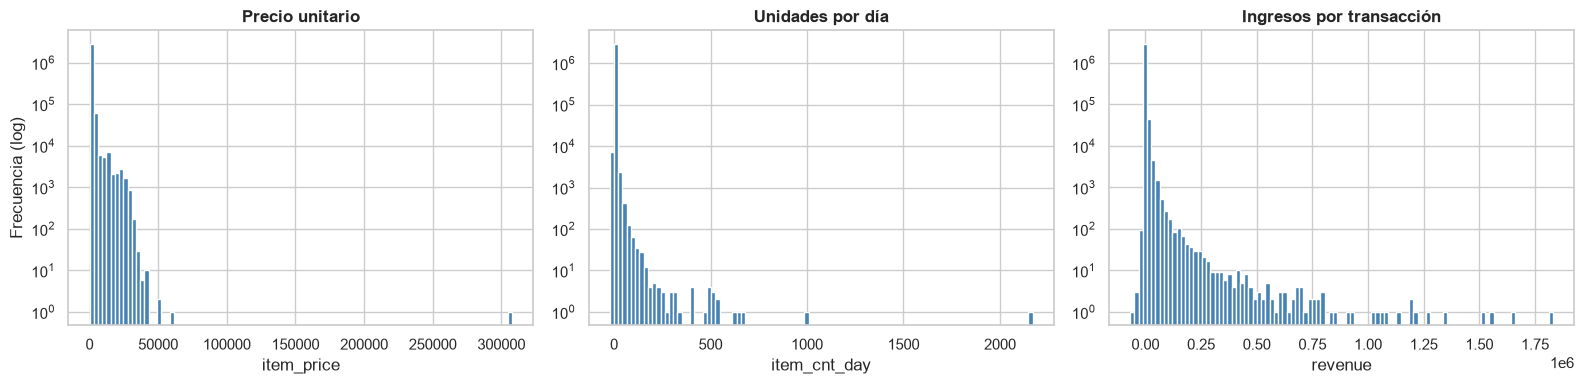

In [29]:
# ===== 5.a Distribuciones (escala logarítmica) =====
# Histogramas de precio, cantidad e ingresos. Usamos escala log en el eje Y porque las colas son muy largas.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))  # Tres gráficas en una fila
for ax, col, titulo in zip(axes, ["item_price", "item_cnt_day", "revenue"], ["Precio unitario", "Unidades por día", "Ingresos por transacción"]):
    ax.hist(df[col], bins=100, color="steelblue")  # Histograma con 100 intervalos
    ax.set_yscale("log")  # Escala logarítmica para ver las colas
    ax.set_title(titulo)  # Título de cada gráfica
    ax.set_xlabel(col)  # Etiqueta del eje X
axes[0].set_ylabel("Frecuencia (log)")  # Etiqueta del eje Y
plt.tight_layout()  # Ajuste de espacios
plt.show()

**Interpretación 5.a:**

| Variable | Media | Mediana | Mín. | Máx. | Desv. est. |
|---|---|---|---|---|---|
| `item_price` | 890.85 | 399.00 | 0.07 | 307,980.00 | 1,729.80 |
| `item_cnt_day` | 1.24 | 1.00 | −22.00 | 2,169.00 | 2.62 |
| ingresos (`revenue`) | 1,157.73 | 449.00 | −68,970.00 | 1,829,990.00 | 5,683.61 |

- Las tres variables tienen una **fuerte asimetría a la derecha**: la media supera ampliamente a la mediana, y los máximos están
  muy lejos del percentil 99.9 (precio 23,990; cantidad 22 unidades).
- La transacción típica es **1 unidad** (incluso el percentil 95 es de solo 2 unidades) de un producto de unos **400 rublos**.
- Los mínimos negativos de cantidad e ingresos corresponden a devoluciones.
- Hay precios muy bajos (mínimo 0.07) que se analizan en 7.c.
- Los máximos aislados (precio 307,980 y cantidad 2,169) se analizan como outliers en la sección 7.c.

### 5.b Distribución de las ventas

#### 5.b.i Por producto y categoría de producto

Productos con al menos una transacción: 21,807 de 22,170 del catálogo


,unidades,ingresos
count,"21,807.00","21,807.00"
mean,167.29,"155,863.88"
std,"1,366.22","1,696,692.66"
min,-11.00,"-28,589.00"
25%,7.00,"2,394.50"
50%,33.00,"12,763.00"
75%,124.00,"54,898.22"
max,"187,642.00","219,391,488.92"


El 80% de las unidades lo venden 3,877 productos (17.8% de los productos vendidos)
Productos con 10 unidades o menos en todo el periodo: 30.8%


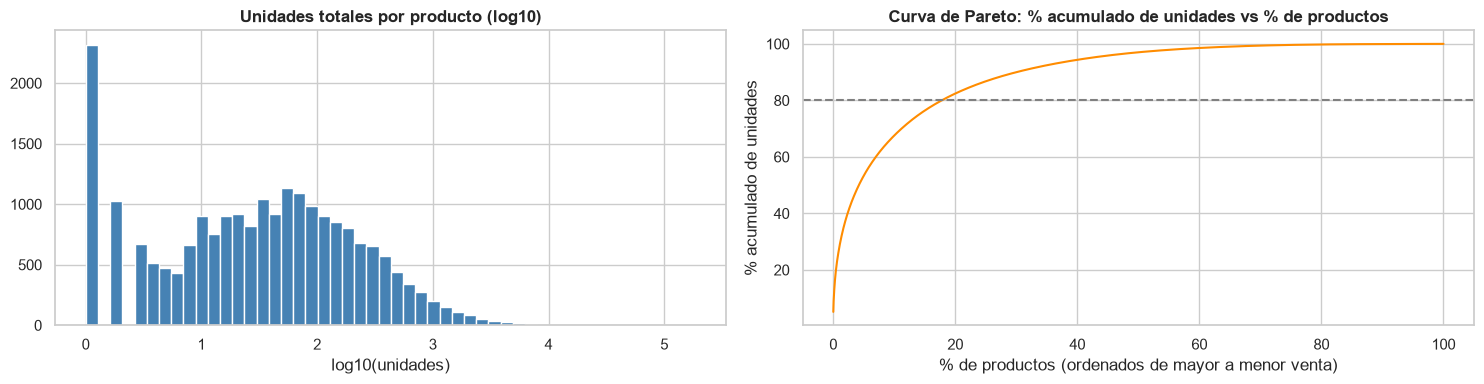

In [30]:
# ===== 5.b.i Distribución de ventas por producto =====
# Sumamos las unidades e ingresos totales de cada producto y describimos la distribución resultante.
ventas_producto = df.groupby(["item_id", "item_name"]).agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum")).reset_index()  # Totales por producto
print(f"Productos con al menos una transacción: {len(ventas_producto):,} de {items['item_id'].nunique():,} del catálogo")
display(ventas_producto[["unidades", "ingresos"]].describe())  # Estadísticas de la distribución por producto

orden = ventas_producto.sort_values("unidades", ascending=False)  # Productos ordenados por unidades
participacion_acum = orden["unidades"].cumsum() / orden["unidades"].sum()  # Participación acumulada (curva de Pareto)
n80 = (participacion_acum <= 0.80).sum() + 1  # Número de productos que acumulan el 80% de las unidades
print(f"El 80% de las unidades lo venden {n80:,} productos ({n80 / len(orden):.1%} de los productos vendidos)")
print(f"Productos con 10 unidades o menos en todo el periodo: {(ventas_producto['unidades'] <= 10).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))  # Dos gráficas
axes[0].hist(np.log10(ventas_producto.loc[ventas_producto["unidades"] > 0, "unidades"]), bins=50, color="steelblue")  # Histograma en log10
axes[0].set_title("Unidades totales por producto (log10)")
axes[0].set_xlabel("log10(unidades)")
axes[1].plot(np.arange(1, len(orden) + 1) / len(orden) * 100, participacion_acum.values * 100, color="darkorange")  # Curva de Pareto
axes[1].axhline(80, ls="--", color="gray")  # Línea de referencia del 80%
axes[1].set_title("Curva de Pareto: % acumulado de unidades vs % de productos")
axes[1].set_xlabel("% de productos (ordenados de mayor a menor venta)")
axes[1].set_ylabel("% acumulado de unidades")
plt.tight_layout()
plt.show()

In [31]:
# ===== 5.b.i Distribución de ventas por familia de categoría =====
# Agrupamos por familia (nivel superior de la categoría) para ver unidades, ingresos y precio promedio.
ventas_familia = (
    df.groupby("familia")
    .agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), productos=("item_id", "nunique"))  # Totales por familia
    .sort_values("unidades", ascending=False)
)
ventas_familia["pct_unidades"] = ventas_familia["unidades"] / ventas_familia["unidades"].sum() * 100  # Participación en unidades
ventas_familia["pct_ingresos"] = ventas_familia["ingresos"] / ventas_familia["ingresos"].sum() * 100  # Participación en ingresos
ventas_familia["ingreso_por_unidad"] = ventas_familia["ingresos"] / ventas_familia["unidades"]  # Precio promedio efectivo
ventas_familia

,unidades,ingresos,productos,pct_unidades,pct_ingresos,ingreso_por_unidad
familia,,,,,,
Cine,"916,941.00","334,987,320.19",7390,25.13,9.86,365.33
Juegos PC,"689,098.00","477,981,687.75",2129,18.89,14.06,693.63
Juegos (consola),"646,770.00","1,153,844,546.55",1732,17.73,33.95,"1,784.01"
Regalos,"584,366.00","309,146,571.48",3461,16.02,9.10,529.03
Música,"411,294.00","149,719,998.79",4259,11.27,4.40,364.02
Accesorios,"85,056.00","166,386,781.45",217,2.33,4.90,"1,956.20"
Libros,"76,341.00","30,348,897.24",1229,2.09,0.89,397.54
Programas,"74,954.00","122,390,895.13",1134,2.05,3.60,"1,632.88"
Tarjetas de pago,"46,455.00","66,246,995.72",35,1.27,1.95,"1,426.05"


In [32]:
# ===== 5.b.i Distribución de ventas por categoría detallada =====
# Estadísticas de las unidades vendidas por categoría (84 categorías) y las 10 de mayor participación.
ventas_categoria = df.groupby(["item_category_id", "item_category_name"]).agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum")).reset_index()  # Totales por categoría
print(f"Categorías con ventas: {len(ventas_categoria)} de {len(item_categories)}")
display(ventas_categoria[["unidades", "ingresos"]].describe())  # Distribución entre categorías
ventas_categoria["pct_unidades"] = ventas_categoria["unidades"] / ventas_categoria["unidades"].sum() * 100  # Participación
ventas_categoria.sort_values("unidades", ascending=False).head(10)  # Top 10 categorías

Categorías con ventas: 84 de 84


,unidades,ingresos
count,84.00,84.00
mean,"43,430.95","40,463,375.90"
std,"99,845.88","78,721,813.36"
min,1.00,58.00
25%,"2,179.50","695,717.38"
50%,"9,515.50","10,147,013.13"
75%,"32,092.00","38,692,225.48"
max,"634,170.00","412,052,155.90"


,item_category_id,item_category_name,unidades,ingresos,pct_unidades
40,40,Cine - DVD,"634,170.00","169,944,072.69",17.38
30,30,Juegos PC - Ediciones estándar,"456,540.00","257,519,291.08",12.51
55,55,Música - CD de producción local,"348,591.00","100,022,563.57",9.56
19,19,Juegos - PS3,"254,887.00","412,052,155.90",6.99
37,37,Cine - Blu-Ray,"203,283.00","90,478,232.84",5.57
71,71,"Regalos - Bolsas, álbumes, alfombrillas de ratón","187,998.00","934,206.61",5.15
28,28,Juegos PC - Ediciones adicionales,"174,954.00","136,419,148.64",4.80
23,23,Juegos - XBOX 360,"169,940.00","259,615,132.35",4.66
20,20,Juegos - PS4,"127,319.00","373,010,312.01",3.49
65,65,Regalos - Juegos de mesa (compactos),"73,077.00","24,727,890.56",2.00


#### 5.b.ii Por sucursal (tienda)

,unidades,ingresos
count,57.00,57.00
mean,"64,003.51","59,630,238.17"
std,"58,418.85","49,672,250.08"
min,330.00,"377,714.00"
25%,"25,838.00","27,714,110.02"
50%,"53,886.00","49,792,061.50"
75%,"71,201.00","70,204,774.88"
max,"310,777.00","235,217,019.05"


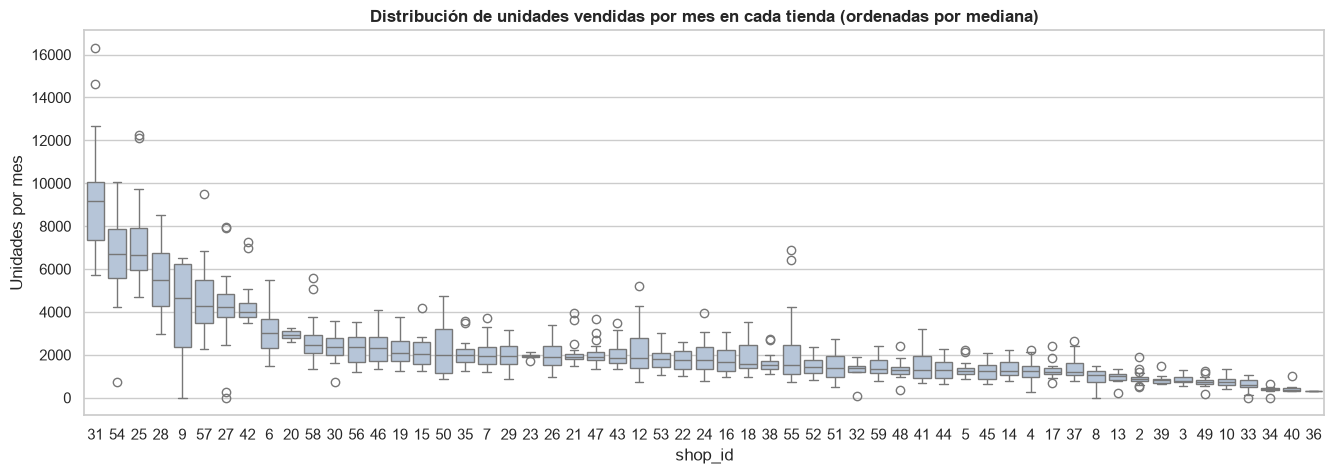

In [33]:
# ===== 5.b.ii Distribución de ventas por tienda =====
# Totales por tienda y distribución de las ventas MENSUALES de cada tienda (boxplot), que permite ver
# el nivel típico y la variabilidad de cada sucursal.
ventas_tienda = df.groupby(["shop_id", "shop_name"]).agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum")).reset_index()  # Totales por tienda
display(ventas_tienda[["unidades", "ingresos"]].describe())  # Distribución entre tiendas

mensual_tienda = df.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().reset_index()  # Unidades por tienda y mes
orden_tiendas = mensual_tienda.groupby("shop_id")["item_cnt_day"].median().sort_values(ascending=False).index  # Orden por mediana mensual
fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(data=mensual_tienda, x="shop_id", y="item_cnt_day", order=orden_tiendas, color="lightsteelblue", ax=ax)  # Un boxplot por tienda
ax.set_title("Distribución de unidades vendidas por mes en cada tienda (ordenadas por mediana)")
ax.set_xlabel("shop_id")
ax.set_ylabel("Unidades por mes")
plt.show()

#### 5.b.iii Por periodo de tiempo (día, semana, mes, año)

In [34]:
# ===== 5.b.iii Ventas agregadas por día, semana, mes y año =====
# Construimos las series agregadas a cada frecuencia y describimos su distribución.
diario = df.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))  # Serie diaria
semanal = df.groupby("week").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))  # Serie semanal
semanal = semanal.iloc[1:-1]  # Quitamos la primera y la última semana porque están incompletas
mensual = df.groupby("year_month").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))  # Serie mensual (34 meses)
anual = df.groupby("year").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), meses=("date_block_num", "nunique"))  # Totales anuales

resumen_periodos = pd.DataFrame({  # Estadísticas de unidades a cada frecuencia
    "diario": diario["unidades"].describe(),
    "semanal": semanal["unidades"].describe(),
    "mensual": mensual["unidades"].describe(),
})
display(resumen_periodos)

,diario,semanal,mensual
count,"1,034.00",146.00,34.00
mean,"3,528.24","24,645.97","107,300.00"
std,"1,584.68","7,801.24","28,455.95"
min,"1,274.00","12,389.00","63,187.00"
25%,"2,472.25","19,959.25","85,968.25"
50%,"3,145.00","24,500.50","107,306.00"
75%,"4,257.00","27,672.50","125,358.50"
max,"13,343.00","57,680.00","183,342.00"


In [35]:
# ===== 5.b.iii Comparación anual (mismo periodo enero-octubre) =====
# 2015 solo tiene datos hasta octubre, así que comparamos los tres años con los meses enero-octubre para ser justos.
ene_oct = df[df["month"] <= 10].groupby("year").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))  # Totales ene-oct
ene_oct["var_unidades_%"] = ene_oct["unidades"].pct_change() * 100  # Variación anual de unidades
ene_oct["var_ingresos_%"] = ene_oct["ingresos"].pct_change() * 100  # Variación anual de ingresos
print("Totales por año completo (2015 solo tiene 10 meses):")
display(anual)
print("Comparación enero-octubre de cada año:")
display(ene_oct)

Totales por año completo (2015 solo tiene 10 meses):


,unidades,ingresos,meses
year,,,
2013,"1,562,732.00","1,217,526,459.98",12
2014,"1,320,884.00","1,346,773,983.81",12
2015,"764,584.00","834,623,131.78",10


Comparación enero-octubre de cada año:


,unidades,ingresos,var_unidades_%,var_ingresos_%
year,,,,
2013,"1,249,381.00","871,289,289.22",NaN,NaN
2014,"1,034,285.00","962,711,712.66",-17.22,10.49
2015,"764,584.00","834,623,131.78",-26.08,-13.30


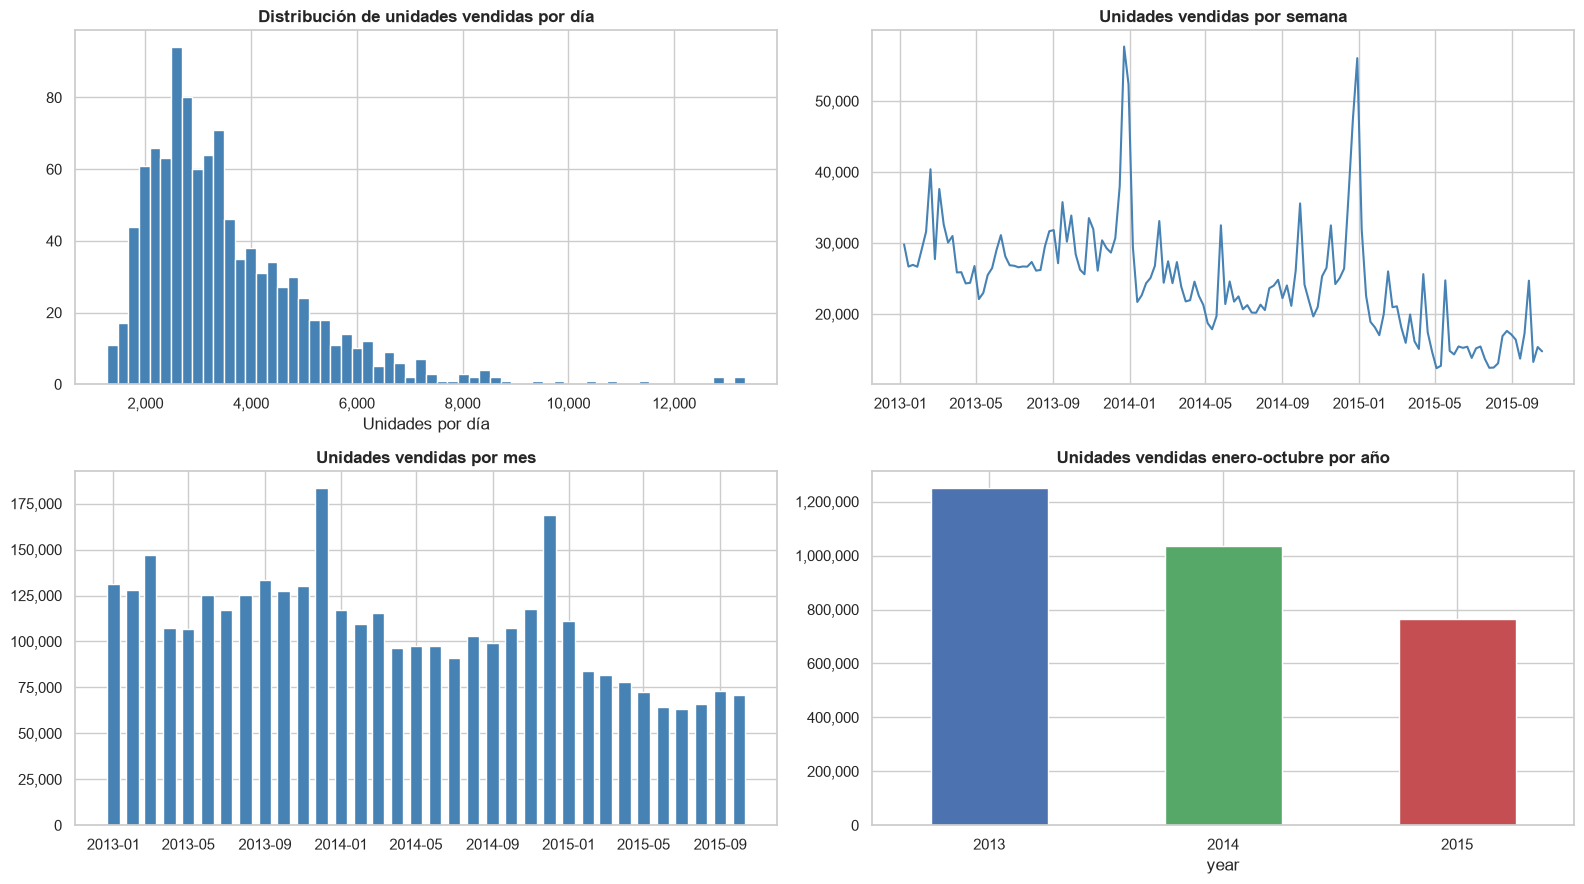

In [36]:
# ===== 5.b.iii Gráficas de distribución por periodo =====
# Histograma de unidades diarias, serie semanal, barras mensuales y comparación anual ene-oct.
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes[0, 0].hist(diario["unidades"], bins=60, color="steelblue")  # Distribución de unidades por día
axes[0, 0].set_title("Distribución de unidades vendidas por día")
axes[0, 0].set_xlabel("Unidades por día")
axes[0, 1].plot(semanal.index, semanal["unidades"], color="steelblue")  # Serie semanal
axes[0, 1].set_title("Unidades vendidas por semana")
axes[1, 0].bar(mensual.index, mensual["unidades"], width=20, color="steelblue")  # Barras por mes
axes[1, 0].set_title("Unidades vendidas por mes")
ene_oct["unidades"].plot(kind="bar", ax=axes[1, 1], color=["#4c72b0", "#55a868", "#c44e52"])  # Barras por año
axes[1, 1].set_title("Unidades vendidas enero-octubre por año")
axes[1, 1].tick_params(axis="x", rotation=0)
for ax in axes.flat:
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))  # Separador de miles en el eje Y
axes[0, 0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

**Interpretación 5.b:**

**Productos**
- De 22,170 productos del catálogo, **21,807** tienen ventas. La distribución está muy concentrada: la mediana es de 33
  unidades en todo el periodo, pero **el 17.8% de los productos (3,877) genera el 80% de las unidades** (patrón de Pareto).
- El **30.8%** de los productos vendió 10 unidades o menos en casi tres años.

**Categorías**
- Por unidades lideran **Cine (25.1%)**, **Juegos PC (18.9%)**, **Juegos de consola (17.7%)**, **Regalos (16.0%)** y
  **Música (11.3%)**. La categoría detallada más vendida es *Cine - DVD* (17.4% de las unidades).
- **En ingresos el orden cambia:** los Juegos de consola aportan el **34.0%** de los ingresos y las **Consolas**, con solo el
  0.9% de las unidades, aportan el **15.5%** por su alto precio (~16,400 rublos por unidad). Cine aporta el 25% de las
  unidades pero solo el 9.9% de los ingresos.

**Tiendas**
- Las 57 tiendas tienen una mediana de 53,886 unidades, con gran dispersión: desde 330 unidades (tienda 36, que solo opera el
  último mes) hasta 310,777 (tienda 31).
- El boxplot muestra que unas pocas tiendas grandes, en su mayoría de Moscú y su región, tienen niveles mensuales muy superiores al resto.

**Periodos**
- **Días:** 3,528 unidades en promedio (rango 1,274–13,343).
- **Semanas:** ~24,600 unidades en promedio.
- **Meses:** 107,300 unidades en promedio (rango 63,187–183,342).
- **Años:** comparando el mismo periodo enero–octubre, las unidades **cayeron 17.2% en 2014 y 26.1% en 2015**. Los ingresos
  subieron 10.5% en 2014 y cayeron 13.3% en 2015, es decir, se venden menos unidades pero más caras.

## 6. Exploración temporal

### 6.a Evolución de las ventas a lo largo del tiempo

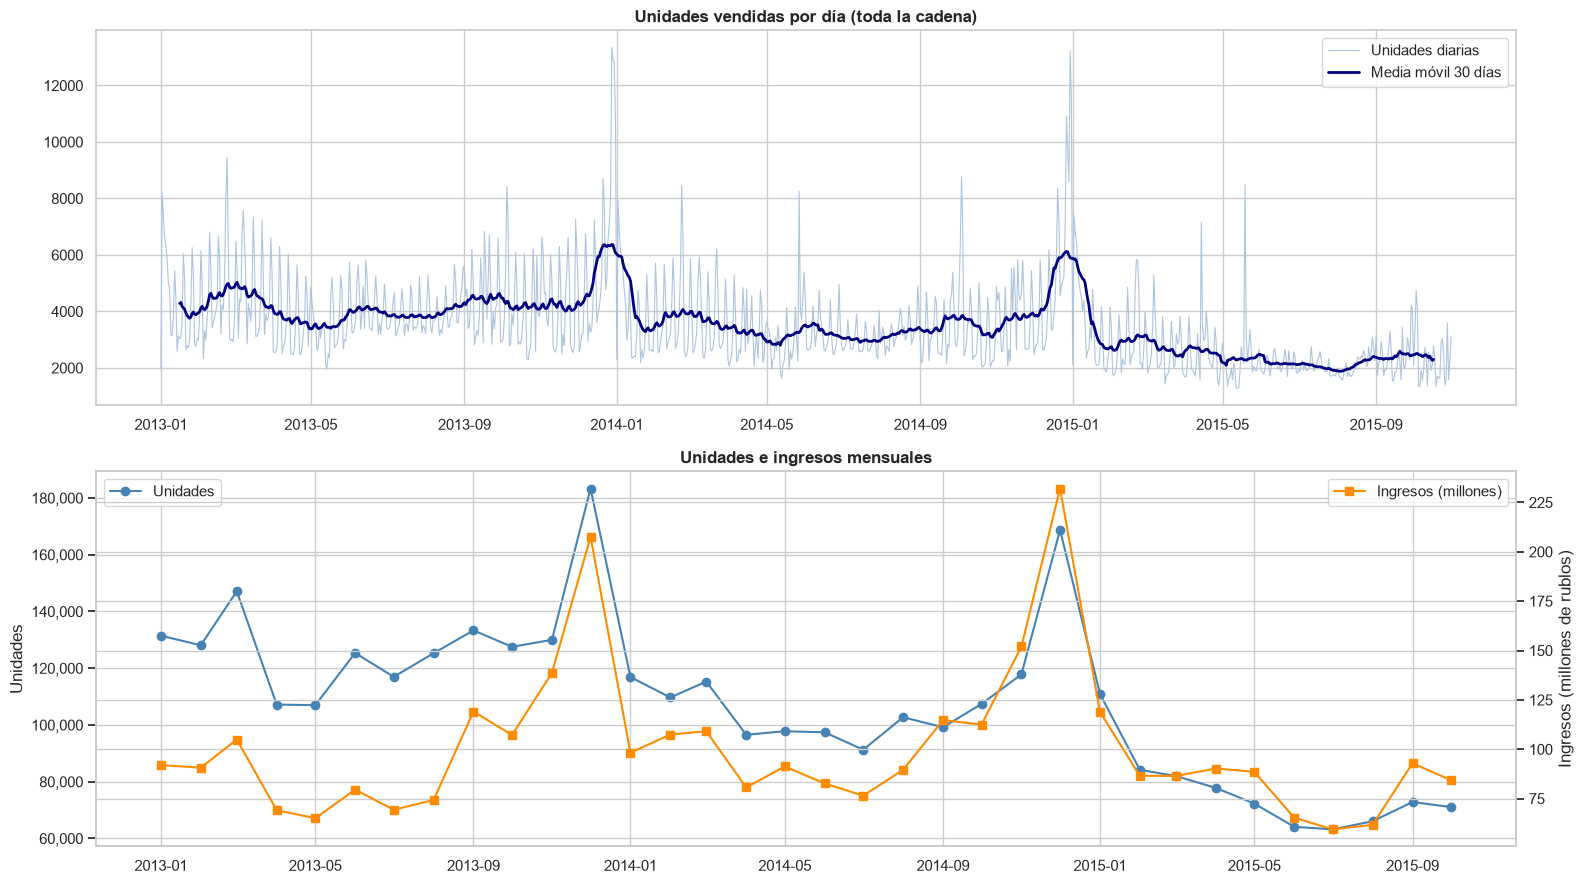

In [37]:
# ===== 6.a Evolución diaria y mensual de unidades e ingresos =====
# Graficamos la serie diaria con su media móvil de 30 días y la serie mensual de unidades e ingresos (dos ejes).
fig, axes = plt.subplots(2, 1, figsize=(16, 9))
axes[0].plot(diario.index, diario["unidades"], color="lightsteelblue", lw=0.8, label="Unidades diarias")  # Serie diaria
axes[0].plot(diario.index, diario["unidades"].rolling(30, center=True).mean(), color="navy", lw=2, label="Media móvil 30 días")  # Suavizado
axes[0].set_title("Unidades vendidas por día (toda la cadena)")
axes[0].legend()

ax2 = axes[1].twinx()  # Segundo eje Y para los ingresos
axes[1].plot(mensual.index, mensual["unidades"], marker="o", color="steelblue", label="Unidades")  # Unidades mensuales
ax2.plot(mensual.index, mensual["ingresos"] / 1e6, marker="s", color="darkorange", label="Ingresos (millones)")  # Ingresos en millones
axes[1].set_title("Unidades e ingresos mensuales")
axes[1].set_ylabel("Unidades")
ax2.set_ylabel("Ingresos (millones de rublos)")
axes[1].legend(loc="upper left")
ax2.legend(loc="upper right")
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

### 6.b Patrones temporales

#### 6.b.i Tendencia

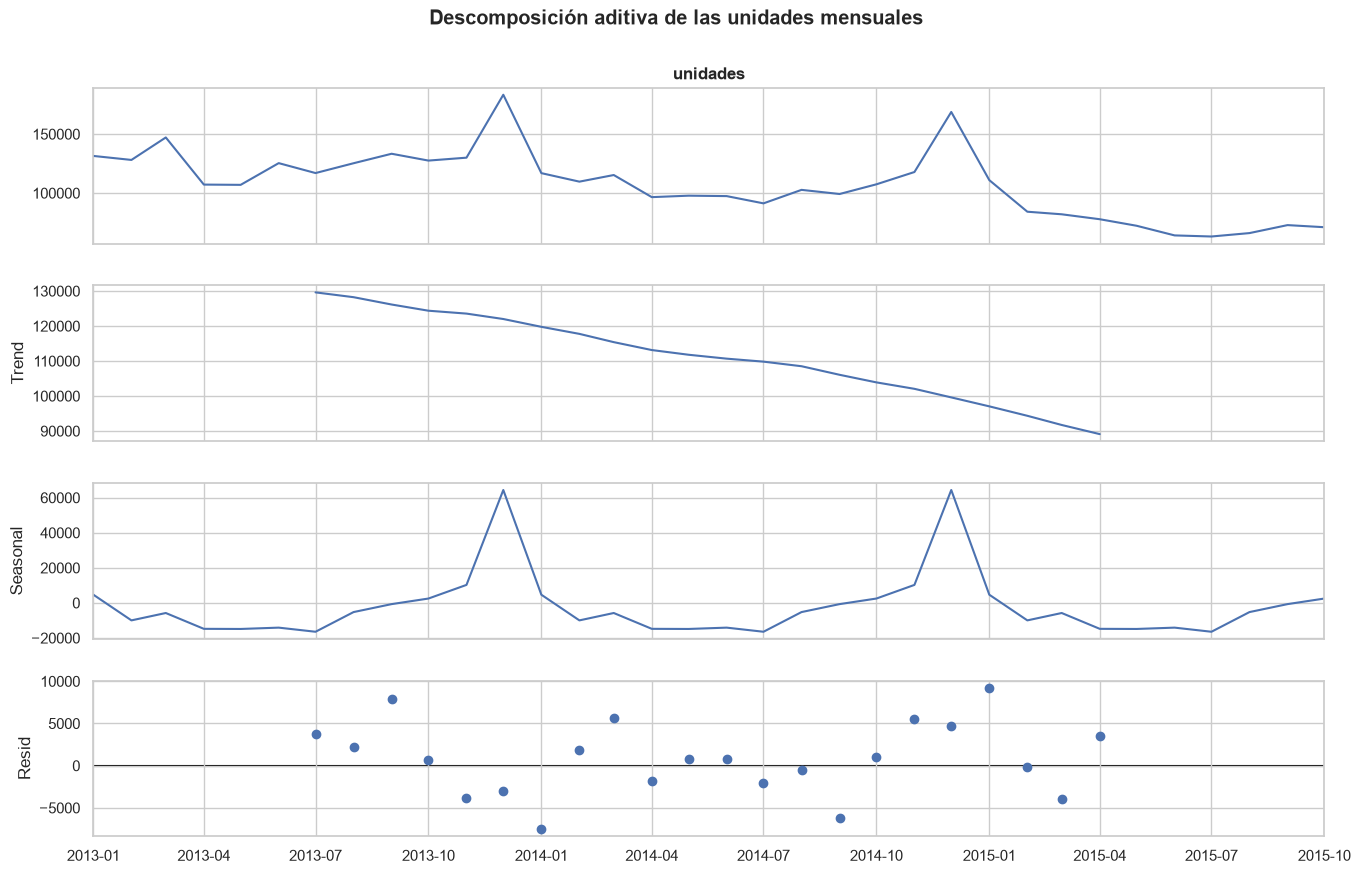

Pendiente lineal de unidades mensuales: -1,944 unidades por mes
Tendencia al inicio (2013-07): 129,620 | al final (2015-04): 89,114 | cambio: -31.3%


In [38]:
# ===== 6.b.i Tendencia: descomposición de la serie mensual =====
# Descomponemos la serie mensual de unidades en tendencia + estacionalidad (periodo 12 meses) + residuo.
# Con 34 meses hay casi tres ciclos anuales, suficiente para una descomposición aditiva.
serie_mensual = mensual["unidades"].copy()  # Serie mensual de unidades
serie_mensual.index.freq = "MS"  # Frecuencia mensual (inicio de mes)
descomp = seasonal_decompose(serie_mensual, model="additive", period=12)  # Descomposición clásica
fig = descomp.plot()  # Gráfica con las cuatro componentes
fig.set_size_inches(14, 9)
fig.suptitle("Descomposición aditiva de las unidades mensuales", y=1.01, fontweight="bold")
plt.show()

# Pendiente lineal de la tendencia (regresión de unidades contra el número de mes)
pendiente, intercepto = np.polyfit(np.arange(len(serie_mensual)), serie_mensual.values, 1)  # Ajuste lineal
print(f"Pendiente lineal de unidades mensuales: {pendiente:,.0f} unidades por mes")
tendencia = descomp.trend.dropna()  # La tendencia (media móvil centrada) no existe en los extremos
print(f"Tendencia al inicio ({tendencia.index[0]:%Y-%m}): {tendencia.iloc[0]:,.0f} | al final ({tendencia.index[-1]:%Y-%m}): {tendencia.iloc[-1]:,.0f} "
      f"| cambio: {tendencia.iloc[-1] / tendencia.iloc[0] - 1:.1%}")

In [39]:
# ===== 6.b.i Tendencia en ingresos y precio promedio =====
# Comparamos la tendencia de ingresos con la de unidades; si los ingresos caen menos, el precio promedio sube.
mensual["precio_promedio"] = mensual["ingresos"] / mensual["unidades"]  # Ingreso por unidad vendida
pend_ing, _ = np.polyfit(np.arange(len(mensual)), mensual["ingresos"].values, 1)  # Pendiente de ingresos
print(f"Pendiente lineal de ingresos mensuales: {pend_ing:,.0f} rublos por mes")
print("Precio promedio por unidad, primeros y últimos 3 meses:")
display(mensual["precio_promedio"].iloc[[0, 1, 2, -3, -2, -1]])

Pendiente lineal de ingresos mensuales: -80,081 rublos por mes
Precio promedio por unidad, primeros y últimos 3 meses:


year_month
2013-01-01     699.33
2013-02-01     707.83
2013-03-01     713.14
2015-08-01     934.47
2015-09-01   1,275.42
2015-10-01   1,186.91
Name: precio_promedio, dtype: float64

#### 6.b.ii Estacionalidad

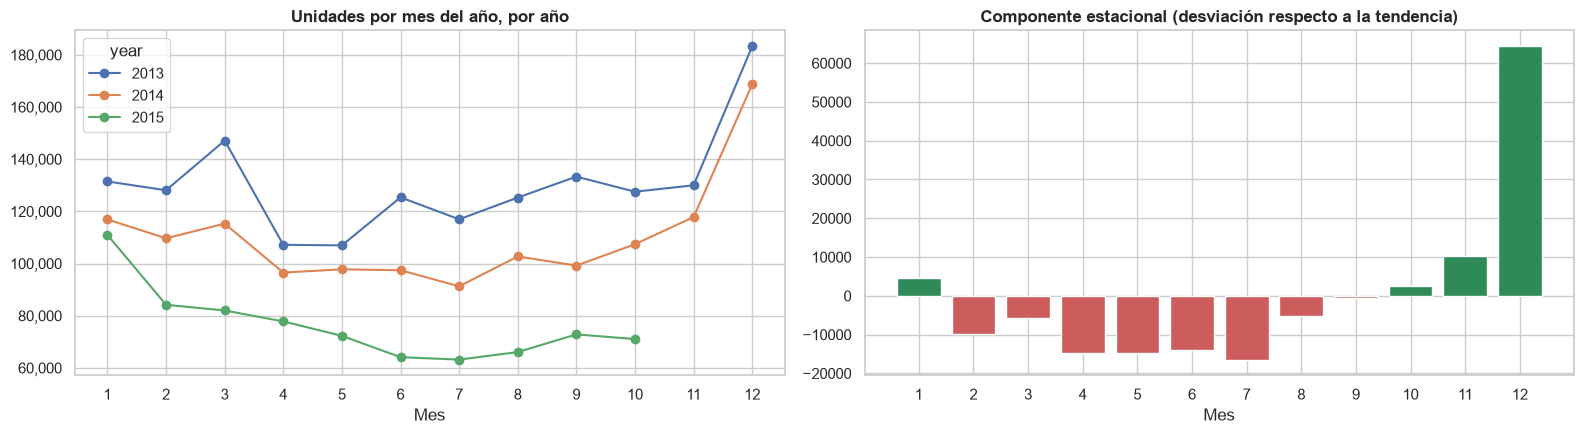

Componente estacional por mes (unidades):
year_month
1      4,674.00
2     -9,965.00
3     -5,758.00
4    -14,785.00
5    -14,856.00
6    -14,101.00
7    -16,449.00
8     -5,224.00
9       -689.00
10     2,491.00
11    10,271.00
12    64,390.00


In [40]:
# ===== 6.b.ii Estacionalidad: comparación de cada mes del año entre años =====
# Superponemos las unidades mensuales de 2013, 2014 y 2015 por mes del año y mostramos el componente estacional.
por_anio = df.groupby(["year", "month"])["item_cnt_day"].sum().unstack(0)  # Filas = mes (1-12), columnas = año
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
por_anio.plot(marker="o", ax=axes[0])  # Una línea por año
axes[0].set_title("Unidades por mes del año, por año")
axes[0].set_xticks(range(1, 13))
axes[0].set_xlabel("Mes")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
estacional = descomp.seasonal.groupby(descomp.seasonal.index.month).first()  # Componente estacional por mes del año
axes[1].bar(estacional.index, estacional.values, color=np.where(estacional.values > 0, "seagreen", "indianred"))  # Barras del efecto estacional
axes[1].set_title("Componente estacional (desviación respecto a la tendencia)")
axes[1].set_xticks(range(1, 13))
axes[1].set_xlabel("Mes")
plt.tight_layout()
plt.show()
print("Componente estacional por mes (unidades):")
print(estacional.round(0).to_string())

#### 6.b.iii Picos o caídas abruptas

In [41]:
# ===== 6.b.iii Picos y caídas: variación mensual y días extremos =====
# Calculamos la variación porcentual mes a mes y listamos los mayores aumentos y caídas,
# además de los días con más y menos unidades vendidas.
DIAS_ES = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]  # Días en español (0 = lunes)
var_mensual = mensual["unidades"].pct_change() * 100  # Variación % respecto al mes anterior
print("Mayores aumentos mensuales (%):")
print(var_mensual.nlargest(4).round(1).to_string())
print("\nMayores caídas mensuales (%):")
print(var_mensual.nsmallest(4).round(1).to_string())

print("\nTop 10 días con más unidades vendidas:")
top_dias = diario.nlargest(10, "unidades").copy()  # Días pico
top_dias["dia_semana"] = [DIAS_ES[d] for d in top_dias.index.day_of_week]  # Día de la semana del pico (en español)
display(top_dias)
print("Top 5 días con menos unidades vendidas:")
bottom_dias = diario.nsmallest(5, "unidades").copy()  # Días valle
bottom_dias["dia_semana"] = [DIAS_ES[d] for d in bottom_dias.index.day_of_week]  # Día de la semana (en español)
display(bottom_dias)

Mayores aumentos mensuales (%):
year_month
2014-12-01   43.20
2013-12-01   41.00
2013-06-01   17.20
2013-03-01   14.90

Mayores caídas mensuales (%):
year_month
2014-01-01   -36.20
2015-01-01   -34.20
2013-04-01   -27.20
2015-02-01   -24.10

Top 10 días con más unidades vendidas:


,unidades,ingresos,dia_semana
date,,,
2013-12-28,"13,343.00","14,626,701.00",Sábado
2014-12-30,"13,236.00","17,002,645.00",Martes
2013-12-29,"12,863.00","14,273,758.50",Domingo
2013-12-30,"12,823.00","14,671,056.20",Lunes
2014-12-31,"11,393.00","15,021,005.13",Miércoles
2014-12-27,"10,919.00","15,649,897.60",Sábado
2013-12-31,"10,514.00","12,115,056.15",Martes
2014-12-28,"9,727.00","12,455,894.00",Domingo
2013-02-23,"9,456.00","6,817,895.34",Sábado


Top 5 días con menos unidades vendidas:


,unidades,ingresos,dia_semana
date,,,
2015-05-12,"1,274.00","1,350,036.00",Martes
2015-05-13,"1,294.00","1,244,734.00",Miércoles
2015-05-14,"1,302.00","1,239,649.20",Jueves
2015-10-05,"1,340.00","1,639,808.55",Lunes
2015-10-19,"1,341.00","1,266,478.00",Lunes


In [42]:
# ===== 6.b.iii Detección de días atípicos respecto a la tendencia local =====
# Un día es atípico si se aleja más de 3 desviaciones estándar de su media móvil de 30 días.
media_movil = diario["unidades"].rolling(30, center=True, min_periods=15).mean()  # Nivel local
desv_movil = diario["unidades"].rolling(30, center=True, min_periods=15).std()  # Variabilidad local
z = (diario["unidades"] - media_movil) / desv_movil  # Puntaje z respecto al nivel local
atipicos = diario.loc[z.abs() > 3, ["unidades"]].assign(z=z[z.abs() > 3])  # Días atípicos
print(f"Días atípicos (|z| > 3): {len(atipicos)}")
atipicos.assign(dia_semana=[DIAS_ES[d] for d in atipicos.index.day_of_week])  # Agregamos el día de la semana

Días atípicos (|z| > 3): 5


,unidades,z,dia_semana
date,,,
2014-05-27,"8,256.00",3.84,Martes
2014-06-28,"4,953.00",3.11,Sábado
2014-10-04,"8,767.00",3.20,Sábado
2015-04-14,"7,158.00",4.04,Martes
2015-05-19,"8,483.00",4.84,Martes


#### 6.b.iv Ciclos por día de la semana y mes del año

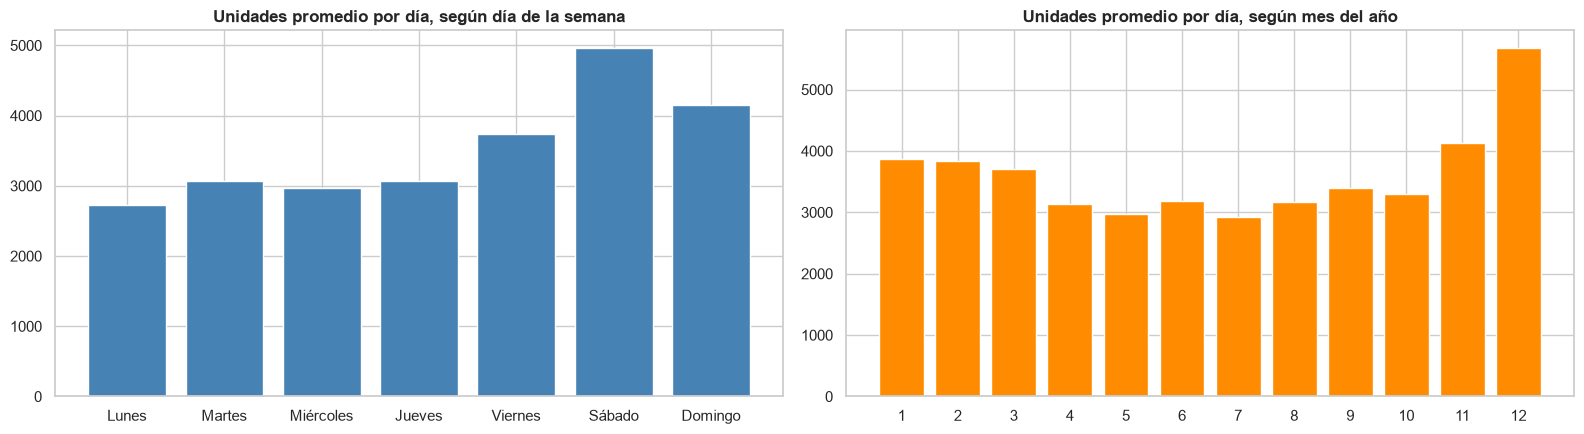

Índice semanal (promedio del día / promedio general):
Lunes       0.77
Martes      0.87
Miércoles   0.84
Jueves      0.87
Viernes     1.06
Sábado      1.41
Domingo     1.17

Índice mensual (promedio del mes / promedio general):
date
1    1.10
2    1.09
3    1.05
4    0.89
5    0.84
6    0.90
7    0.83
8    0.90
9    0.96
10   0.93
11   1.17
12   1.61


In [43]:
# ===== 6.b.iv Ciclo semanal y ciclo anual =====
# Promedio de unidades por día según el día de la semana, y promedio diario según el mes del año.
# Usamos promedios (no sumas) porque no todos los días de la semana/meses aparecen el mismo número de veces.
dias_es = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]  # Nombres en español
prom_dia_semana = diario.groupby(diario.index.day_of_week)["unidades"].mean()  # Promedio por día de la semana
prom_dia_semana.index = dias_es  # Etiquetas en español
prom_mes = diario.groupby(diario.index.month)["unidades"].mean()  # Promedio diario por mes del año

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].bar(prom_dia_semana.index, prom_dia_semana.values, color="steelblue")  # Ciclo semanal
axes[0].set_title("Unidades promedio por día, según día de la semana")
axes[1].bar(prom_mes.index, prom_mes.values, color="darkorange")  # Ciclo anual
axes[1].set_title("Unidades promedio por día, según mes del año")
axes[1].set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

print("Índice semanal (promedio del día / promedio general):")
print((prom_dia_semana / diario["unidades"].mean()).round(2).to_string())
print("\nÍndice mensual (promedio del mes / promedio general):")
print((prom_mes / diario["unidades"].mean()).round(2).to_string())

**Interpretación de la sección 6:**

**i. Tendencia**
- Hay una **tendencia decreciente clara en unidades**: la pendiente lineal es de **−1,944 unidades por mes**, y la componente
  de tendencia baja de 129,620 (jul-2013) a 89,114 (abr-2015), un **−31.3%**.
- Los **ingresos caen mucho menos** (−80,081 rublos/mes, frente a niveles de ~100 millones mensuales) porque el **precio
  promedio por unidad subió** de ~700 rublos (inicio de 2013) a ~1,190 (octubre 2015).
- El negocio vende menos unidades pero de mayor valor (más consolas y juegos, menos DVD y CD; ver heatmap 8.d).

**ii. Estacionalidad**
- Es **anual y muy marcada en diciembre**: su componente estacional es **+64,390 unidades** sobre la tendencia. Noviembre
  (+10,271) y enero (+4,674) también están por encima.
- De abril a julio las ventas están ~14,000–16,000 unidades por debajo de la tendencia.
- El patrón se repite en 2013 y 2014 (gráfica por año).

**iii. Picos y caídas abruptas**
- Los mayores aumentos son **diciembre 2014 (+43.2%)** y **diciembre 2013 (+41.0%)**; las mayores caídas son los eneros
  siguientes (**−36.2%** en 2014 y **−34.2%** en 2015), es decir, la "resaca" post-navideña.
- Los 8 días de mayor venta son del **27 al 31 de diciembre**.
- El 23-feb-2013 aparece entre los 10 días con más ventas; coincide con el feriado ruso del 23 de febrero (Día del Defensor de
  la Patria).
- Los días con menos ventas son del 12 al 14 de mayo de 2015.
- Se detectaron **5 días atípicos** respecto a su nivel local (|z| > 3). Uno es el 14-abr-2015, cuando la tienda online (12)
  registró 624 unidades de *Grand Theft Auto V [PC]* en un solo día (ver 7.c.2). Estos picos están asociados a lanzamientos o
  eventos puntuales.

**iv. Ciclos**
- **Semanal:** fuerte ciclo de fin de semana. El **sábado** vende un **41% más** que el día promedio, el domingo un 17% más y el
  viernes un 6% más; el **lunes** es el día más bajo (−23%).
- **Anual:** diciembre (+61%) y noviembre (+17%) son los meses más fuertes; mayo y julio son los más débiles (−16% y −17%).

## 7. Análisis comparativo entre sucursales y productos

### 7.a Productos y categorías más y menos vendidos

In [44]:
# ===== 7.a Productos más vendidos (unidades e ingresos) =====
# Top 10 productos por unidades y por ingresos, con su categoría.
prod = (
    df.groupby(["item_id", "item_name", "item_category_name"])
    .agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), tiendas=("shop_id", "nunique"), meses=("date_block_num", "nunique"))  # Métricas por producto
    .reset_index()
)
print("Top 10 productos por UNIDADES:")
display(prod.nlargest(10, "unidades"))
print("Top 10 productos por INGRESOS:")
display(prod.nlargest(10, "ingresos"))

Top 10 productos por UNIDADES:


,item_id,item_name,item_category_name,unidades,ingresos,tiendas,meses
20602,20949,Bolsa de marca tipo camiseta 1C Interes blanca (34*42) 4...,"Regalos - Bolsas, álbumes, alfombrillas de ratón","187,642.00","928,863.70",52,31
2749,2808,"Diablo III [PC, Jewel, versión rusa]",Juegos PC - Ediciones estándar,"17,245.00","16,852,778.42",55,34
3654,3732,"Grand Theft Auto V [PS3, subtítulos en ruso]",Juegos - PS3,"16,642.00","43,617,975.48",52,26
17418,17717,Recepción de pagos para 1C-Online,Servicio,"15,830.00","17,200,825.93",51,34
5717,5822,Playstation Store recarga de monedero: tarjeta de pago 1...,Tarjetas de pago - PSN,"14,515.00","15,408,983.12",55,34
3656,3734,"Grand Theft Auto V [Xbox 360, subtítulos en ruso]",Juegos - XBOX 360,"11,688.00","31,065,160.27",51,26
6543,6675,Sony PlayStation 4 (500 GB) Negra (CUH-1008A/1108A/B01),Consolas - PS4,"10,289.00","219,391,488.92",51,24
3653,3731,"Grand Theft Auto V [PC, subtítulos en ruso]",Juegos PC - Ediciones estándar,"10,099.00","19,983,482.89",43,7
1814,1855,"Battlefield 4 [PC, versión rusa]",Juegos PC - Ediciones estándar,"10,032.00","9,357,024.78",51,24
16493,16787,"The Last of Us [PS3, versión rusa]",Juegos - PS3,"9,227.00","21,907,839.08",52,29


Top 10 productos por INGRESOS:


,item_id,item_name,item_category_name,unidades,ingresos,tiendas,meses
6543,6675,Sony PlayStation 4 (500 GB) Negra (CUH-1008A/1108A/B01),Consolas - PS4,"10,289.00","219,391,488.92",51,24
3654,3732,"Grand Theft Auto V [PS3, subtítulos en ruso]",Juegos - PS3,"16,642.00","43,617,975.48",52,26
13195,13443,Set Sony PS4 (500 Gb) Negro (CUH-1108A/B01) + juego Gran...,Consolas - PS4,"1,366.00","34,331,245.28",48,9
3656,3734,"Grand Theft Auto V [Xbox 360, subtítulos en ruso]",Juegos - XBOX 360,"11,688.00","31,065,160.27",51,26
3655,3733,"Grand Theft Auto V [PS4, subtítulos en ruso]",Juegos - PS4,"6,506.00","22,298,864.36",50,12
16493,16787,"The Last of Us [PS3, versión rusa]",Juegos - PS3,"9,227.00","21,907,839.08",52,29
3653,3731,"Grand Theft Auto V [PC, subtítulos en ruso]",Juegos PC - Ediciones estándar,"10,099.00","19,983,482.89",43,7
13157,13405,"Set ""Microsoft Xbox One 500GB (Edición Día Uno Caja Verd...",Consolas - XBOX ONE,991.00,"18,125,479.52",49,14
17418,17717,Recepción de pagos para 1C-Online,Servicio,"15,830.00","17,200,825.93",51,34
5718,5823,Reposición de billetera de Playstation Store: Tarjeta de...,Tarjetas de pago - PSN,"6,523.00","17,151,846.09",52,34


In [45]:
# ===== 7.a Productos menos vendidos =====
# Los productos con menor venta neta (incluye productos cuyas devoluciones superan sus ventas).
print("Productos con venta neta <= 0 (más devoluciones que ventas):", (prod["unidades"] <= 0).sum())
print("Productos con exactamente 1 unidad neta en todo el periodo:", (prod["unidades"] == 1).sum())
print("Productos del catálogo SIN ninguna transacción en train:", items["item_id"].nunique() - prod["item_id"].nunique())
print("\n10 productos menos vendidos (venta neta):")
prod.nsmallest(10, "unidades")

Productos con venta neta <= 0 (más devoluciones que ventas): 8
Productos con exactamente 1 unidad neta en todo el periodo: 2319
Productos del catálogo SIN ninguna transacción en train: 363

10 productos menos vendidos (venta neta):


,item_id,item_name,item_category_name,unidades,ingresos,tiendas,meses
1552,1590,"Assassin's Creed 3. Freedom Edition [PC, versión rusa]",Juegos PC - Ediciones de colección,-11.00,"-28,589.00",2,4
11664,11871,Serpiente,"Regalos - Gadgets, robots, deporte",-1.00,"-5,999.00",1,1
13223,13474,Set “Sony PS3 (320 Gb) (CECH-2508B) + juego “FIFA 12”,Consolas - PS3,-1.00,"-10,398.00",1,1
17760,18062,Perro Robopet,"Regalos - Gadgets, robots, deporte",-1.00,"-4,999.00",1,1
4504,4591,"MCCARTNEY, PAUL En la Plaza Roja (Compañía)",Música - Video musical,0.00,0.00,1,1
7401,7547,VideoStudio Pro X6 IE Windows Mini-Box,Programas - Hogar y oficina,0.00,0.00,1,1
8350,8515,Idioma en Inglés. 2 - 5 grado (Joya),Programas - Educativos,0.00,14.90,2,1
13226,13477,Set “Sony PS3 (320 Gb) (CECH-3008B)” + juego “Sorcerer” ...,Consolas - PS3,0.00,"-7,592.00",2,2
0,0,! BAJO EL PODER DE LA OBSESIÓN (PLÁSTICO) D,Cine - DVD,1.00,58.00,1,1
4,4,***CAJA (VIDRIO) D,Cine - DVD,1.00,58.00,1,1


In [46]:
# ===== 7.a Categorías más y menos vendidas =====
# Top 10 y bottom 10 de las 84 categorías detalladas según unidades vendidas.
cat = df.groupby(["item_category_id", "item_category_name", "familia"]).agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), productos=("item_id", "nunique")).reset_index()  # Métricas por categoría
print("Top 10 categorías por unidades:")
display(cat.nlargest(10, "unidades"))
print("10 categorías menos vendidas:")
display(cat.nsmallest(10, "unidades"))
print("Categorías del catálogo sin ventas en train:", sorted(set(item_categories["item_category_id"]) - set(cat["item_category_id"])))

Top 10 categorías por unidades:


,item_category_id,item_category_name,familia,unidades,ingresos,productos
40,40,Cine - DVD,Cine,"634,170.00","169,944,072.69",4964
30,30,Juegos PC - Ediciones estándar,Juegos PC,"456,540.00","257,519,291.08",751
55,55,Música - CD de producción local,Música,"348,591.00","100,022,563.57",2327
19,19,Juegos - PS3,Juegos (consola),"254,887.00","412,052,155.90",625
37,37,Cine - Blu-Ray,Cine,"203,283.00","90,478,232.84",1777
71,71,"Regalos - Bolsas, álbumes, alfombrillas de ratón",Regalos,"187,998.00","934,206.61",6
28,28,Juegos PC - Ediciones adicionales,Juegos PC,"174,954.00","136,419,148.64",235
23,23,Juegos - XBOX 360,Juegos (consola),"169,940.00","259,615,132.35",496
20,20,Juegos - PS4,Juegos (consola),"127,319.00","373,010,312.01",157
65,65,Regalos - Juegos de mesa (compactos),Regalos,"73,077.00","24,727,890.56",151


10 categorías menos vendidas:


,item_category_id,item_category_name,familia,unidades,ingresos,productos
10,10,Consolas - PS2,Consolas,1.00,"1,998.00",1
51,51,Libros - Divulgación,Libros,1.00,129.00,1
1,1,Accesorios - PS2,Accesorios,2.00,431.00,2
0,0,PC - Auriculares/Audífonos,PC (audífonos),3.00,263.40,3
50,50,Libros - Postales,Libros,3.00,58.00,2
52,52,Libros - Guías de viaje,Libros,3.00,300.00,3
53,53,Libros - Ficción,Libros,3.00,847.00,3
48,48,Libros - Literatura de computación,Libros,6.00,"1,654.00",5
27,27,Juegos MAC - Digital,Juegos MAC,8.00,"5,422.00",7
18,18,Juegos - PS2,Juegos (consola),11.00,"3,828.20",6


Categorías del catálogo sin ventas en train: []


### 7.b Desempeño entre sucursales

In [47]:
# ===== 7.b Comparación de desempeño entre tiendas =====
# Para comparar de forma justa, además de los totales calculamos el promedio MENSUAL (dividido entre los meses activos),
# porque hay tiendas que abrieron o cerraron durante el periodo.
tienda = (
    df.groupby(["shop_id", "shop_name"])
    .agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), meses_activos=("date_block_num", "nunique"),
         primer_mes=("date_block_num", "min"), ultimo_mes=("date_block_num", "max"), productos=("item_id", "nunique"))  # Métricas por tienda
    .reset_index()
)
tienda["unidades_mes"] = tienda["unidades"] / tienda["meses_activos"]  # Unidades promedio por mes activo
tienda["ingresos_mes"] = tienda["ingresos"] / tienda["meses_activos"]  # Ingresos promedio por mes activo
tienda["precio_promedio"] = tienda["ingresos"] / tienda["unidades"]  # Ingreso por unidad
tienda["pct_ingresos"] = tienda["ingresos"] / tienda["ingresos"].sum() * 100  # Participación en ingresos
tienda["en_test"] = tienda["shop_id"].isin(test["shop_id"])  # ¿Hay que predecir esta tienda?
tienda = tienda.sort_values("unidades_mes", ascending=False)  # Orden por desempeño mensual
print("Top 10 tiendas por unidades promedio mensuales:")
display(tienda.head(10))
print("10 tiendas con menor desempeño mensual:")
display(tienda.tail(10))

Top 10 tiendas por unidades promedio mensuales:


,shop_id,shop_name,unidades,ingresos,meses_activos,primer_mes,ultimo_mes,productos,unidades_mes,ingresos_mes,precio_promedio,pct_ingresos,en_test
28,31,"Moscú CC ""Semyonovsky""","310,777.00","235,217,019.05",34,0,33,14416,"9,140.50","6,918,147.62",756.87,6.92,True
22,25,"Moscú CCE ""Atrium""","241,919.00","216,479,572.44",34,0,33,15367,"7,115.26","6,367,046.25",894.84,6.37,True
51,54,"Jimki CC ""Mega""","185,789.00","141,939,524.00",28,0,27,13863,"6,635.32","5,069,268.71",763.98,4.18,False
25,28,"Moscú CC ""MEGA Tyoply Stan"" II","184,557.00","159,746,337.38",34,0,33,12572,"5,428.15","4,698,421.69",865.57,4.70,True
54,57,"Yakutsk Ordzhonikidze, 56","152,812.00","119,637,153.53",34,0,33,12815,"4,494.47","3,518,739.81",782.90,3.52,True
24,27,"Moscú CC ""MEGA Belaya Dacha II""","136,657.00","140,632,474.12",32,0,32,10842,"4,270.53","4,394,764.82","1,029.09",4.14,False
39,42,"San Petersburgo CC ""Nevsky Tsentr""","144,933.00","151,916,533.55",34,0,33,12034,"4,262.74","4,468,133.34","1,048.18",4.47,True
7,9,Venta itinerante,"15,866.00","16,372,837.00",4,9,33,1404,"3,966.50","4,093,209.25","1,031.94",0.48,False
4,6,"Vorónezh (Plekhanovskaya, 13)","100,489.00","98,067,453.80",34,0,33,11856,"2,955.56","2,884,336.88",975.90,2.89,True
17,20,"Moscú ""Liquidación""","5,872.00","6,599,924.00",2,21,33,746,"2,936.00","3,299,962.00","1,123.97",0.19,False


10 tiendas con menor desempeño mensual:


,shop_id,shop_name,unidades,ingresos,meses_activos,primer_mes,ultimo_mes,productos,unidades_mes,ingresos_mes,precio_promedio,pct_ingresos,en_test
0,2,"Adygea CC ""Mega""","30,620.00","44,049,638.80",34,0,33,4849,900.59,"1,295,577.61","1,438.59",1.30,True
6,8,"Vorónezh CCE City-Park ""Grad""","3,595.00","2,349,358.00",4,0,3,1909,898.75,"587,339.50",653.51,0.07,False
1,3,"Balashikha CCE ""Oktyabr-Kinomir""","28,355.00","30,140,853.87",34,0,33,5261,833.97,"886,495.70","1,062.98",0.89,True
36,39,"Rostov del Don CCE ""Megatsentr Gorizont""","16,617.00","18,092,891.00",20,14,33,4096,830.85,"904,644.55","1,088.82",0.53,True
46,49,"Tiumén CCE ""Kristall""","17,090.00","20,140,923.50",23,11,33,3786,743.04,"875,692.33","1,178.52",0.59,True
8,10,Zhukovski calle Chkalova 39m?,"25,095.00","19,931,938.52",34,0,33,6054,738.09,"586,233.49",794.26,0.59,True
30,33,"Mytishchi CCE ""XL-3""","5,482.00","5,949,101.57",9,19,27,1900,609.11,"661,011.29","1,085.21",0.18,False
37,40,"Rostov del Don CCE ""Megatsentr Gorizont"" Isla","4,943.00","4,293,586.85",11,14,24,817,449.36,"390,326.08",868.62,0.13,False
31,34,"Nizhni Nóvgorod CCE ""RIO""","6,451.00","8,582,822.01",16,18,33,1860,403.19,"536,426.38","1,330.46",0.25,True
33,36,"Novosibirsk CCE ""Galereya Novosibirsk""",330.00,"377,714.00",1,33,33,258,330.00,"377,714.00","1,144.59",0.01,True


Las 5 tiendas con más ingresos concentran el 26.6% de los ingresos
Las 10 tiendas con más ingresos concentran el 42.9% de los ingresos
Tiendas activas en octubre 2015 (mes 33): 44 | tiendas en test: 42


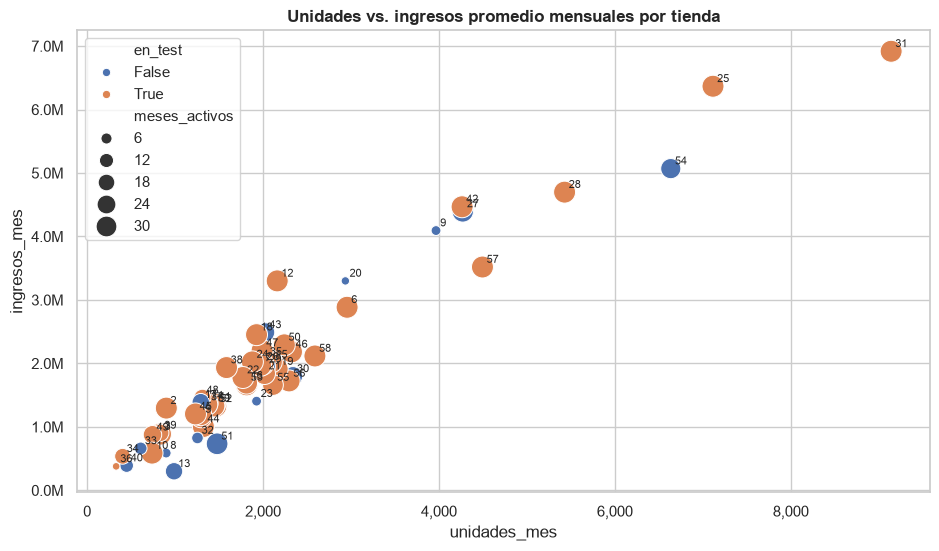

In [48]:
# ===== 7.b Concentración y relación unidades-ingresos por tienda =====
# Medimos qué parte de los ingresos concentran las 5 y 10 mejores tiendas y graficamos unidades vs. ingresos mensuales.
top_ing = tienda.sort_values("ingresos", ascending=False)  # Tiendas ordenadas por ingresos
print(f"Las 5 tiendas con más ingresos concentran el {top_ing['pct_ingresos'].head(5).sum():.1f}% de los ingresos")
print(f"Las 10 tiendas con más ingresos concentran el {top_ing['pct_ingresos'].head(10).sum():.1f}% de los ingresos")
print(f"Tiendas activas en octubre 2015 (mes 33): {(tienda['ultimo_mes'] == 33).sum()} | tiendas en test: {test['shop_id'].nunique()}")

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=tienda, x="unidades_mes", y="ingresos_mes", hue="en_test", size="meses_activos", sizes=(30, 250), ax=ax)  # Una burbuja por tienda
for _, r in tienda.iterrows():
    ax.annotate(int(r["shop_id"]), (r["unidades_mes"], r["ingresos_mes"]), fontsize=8, xytext=(3, 3), textcoords="offset points")  # Etiqueta con el ID
ax.set_title("Unidades vs. ingresos promedio mensuales por tienda")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x / 1e6:,.1f}M"))
plt.show()

### 7.c Outliers y comportamientos anómalos

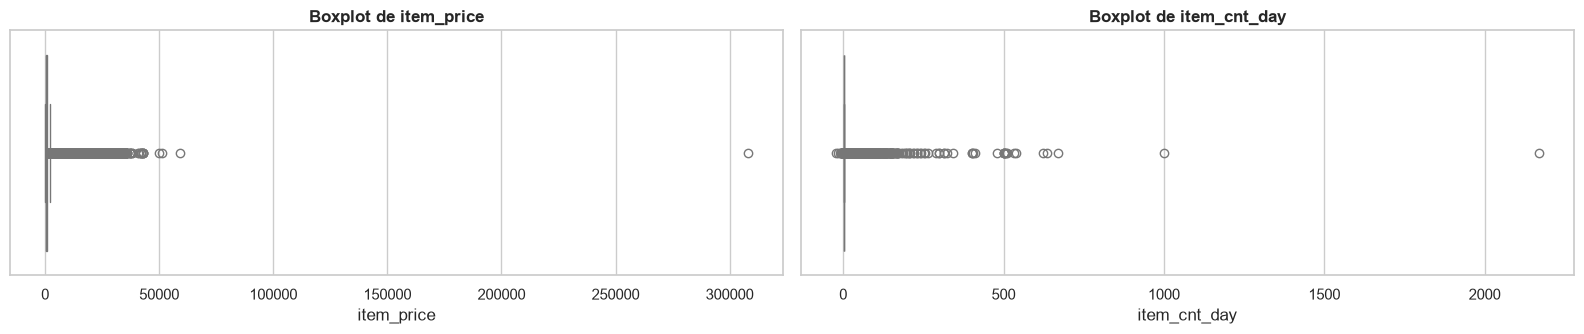

item_price: Q1=249.00, Q3=999.00, límite IQR=2,124.00, filas sobre el límite=258,942 (8.82%)
item_cnt_day: Q1=1.00, Q3=1.00, límite IQR=1.00, filas sobre el límite=299,121 (10.19%)


In [49]:
# ===== 7.c.1 Outliers en precio y cantidad: boxplots y regla IQR =====
# Visualizamos la dispersión de precio y cantidad y contamos cuántos valores caen fuera de la regla
# del rango intercuartílico (Q3 + 1.5*IQR). Con distribuciones tan sesgadas esta regla marca muchos valores,
# por eso también revisamos los extremos absolutos.
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5))
sns.boxplot(x=df["item_price"], ax=axes[0], color="lightsteelblue")  # Boxplot del precio
axes[0].set_title("Boxplot de item_price")
sns.boxplot(x=df["item_cnt_day"], ax=axes[1], color="lightsteelblue")  # Boxplot de la cantidad
axes[1].set_title("Boxplot de item_cnt_day")
plt.tight_layout()
plt.show()

for col in ["item_price", "item_cnt_day"]:  # Regla IQR para cada variable
    q1, q3 = df[col].quantile([0.25, 0.75])  # Cuartiles
    limite = q3 + 1.5 * (q3 - q1)  # Límite superior IQR
    print(f"{col}: Q1={q1:,.2f}, Q3={q3:,.2f}, límite IQR={limite:,.2f}, filas sobre el límite={(df[col] > limite).sum():,} ({(df[col] > limite).mean():.2%})")

In [50]:
# ===== 7.c.2 Transacciones extremas =====
# Las 5 transacciones con mayor precio y con mayor cantidad, comparadas con el precio habitual del mismo producto.
cols = ["date", "shop_id", "shop_name", "item_id", "item_name", "item_category_name", "item_price", "item_cnt_day", "revenue"]  # Columnas a mostrar
mediana_precio_item = df.groupby("item_id")["item_price"].median()  # Precio mediano de cada producto
extremos_precio = df.nlargest(5, "item_price")[cols].copy()  # Top 5 por precio
extremos_precio["precio_mediano_item"] = extremos_precio["item_id"].map(mediana_precio_item)  # Precio típico del mismo producto
print("Top 5 transacciones por PRECIO:")
display(extremos_precio)
extremos_cnt = df.nlargest(5, "item_cnt_day")[cols].copy()  # Top 5 por cantidad
extremos_cnt["precio_mediano_item"] = extremos_cnt["item_id"].map(mediana_precio_item)
print("Top 5 transacciones por CANTIDAD:")
display(extremos_cnt)
print("Brecha entre el precio máximo y el segundo:", f"{df['item_price'].nlargest(2).iloc[0]:,.0f} vs {df['item_price'].nlargest(2).iloc[1]:,.0f}")
print("Brecha entre la cantidad máxima y la segunda:", f"{df['item_cnt_day'].nlargest(2).iloc[0]:,.0f} vs {df['item_cnt_day'].nlargest(2).iloc[1]:,.0f}")

Top 5 transacciones por PRECIO:


,date,shop_id,shop_name,item_id,item_name,item_category_name,item_price,item_cnt_day,revenue,precio_mediano_item
1163157,2013-12-13,12,Tienda en línea ChS,6066,Radmin 3 - 522 licencias,Programas - Hogar y oficina,"307,980.00",1.00,"307,980.00","307,980.00"
885137,2013-09-17,12,Tienda en línea ChS,11365,Entrega (EMS),Envío de productos,"59,200.00",1.00,"59,200.00","1,203.75"
1488133,2014-03-20,25,"Moscú CCE ""Atrium""",13199,Ajedrez coleccionable (El Señor de los Anillos),Regalos - Souvenirs,"50,999.00",1.00,"50,999.00","50,999.00"
2327153,2015-01-29,12,Tienda en línea ChS,7241,UserGate Proxy & Firewall 6.X con módulo de filtrado de ...,Programas - Hogar y oficina,"49,782.00",1.00,"49,782.00","49,782.00"
2885686,2015-10-23,42,"San Petersburgo CC ""Nevsky Tsentr""",13403,"Paquete ""Microsoft Xbox One 1TB Edición limitada Halo 5 ...",Consolas - XBOX ONE,"42,990.00",1.00,"42,990.00","41,990.00"


Top 5 transacciones por CANTIDAD:


,date,shop_id,shop_name,item_id,item_name,item_category_name,item_price,item_cnt_day,revenue,precio_mediano_item
2909812,2015-10-28,12,Tienda en línea ChS,11373,Entrega a punto de recogida (Boxberry),Envío de productos,0.91,"2,169.00","1,971.00",281.62
2326924,2015-01-15,12,Tienda en línea ChS,20949,Bolsa de marca tipo camiseta 1C Interes blanca (34*42) 4...,"Regalos - Bolsas, álbumes, alfombrillas de ratón",4.00,"1,000.00","4,000.00",5.00
2864229,2015-09-30,12,Tienda en línea ChS,9248,"Entrada ""IgroMir 2015"" - 3 de octubre de 2015 (sitio web...",Servicio - Boletos,"1,692.53",669.00,"1,132,300.00","1,500.00"
2851085,2015-09-30,55,Almacén digital 1C-Online,9249,"Entrada ""IgroMir 2015"" - 3 de octubre de 2015 (sitio web...",Boletos (digital),"1,702.83",637.00,"1,084,700.00","1,500.00"
2608034,2015-04-14,12,Tienda en línea ChS,3731,"Grand Theft Auto V [PC, subtítulos en ruso]",Juegos PC - Ediciones estándar,"1,904.55",624.00,"1,188,438.00","1,999.00"


Brecha entre el precio máximo y el segundo: 307,980 vs 59,200


Brecha entre la cantidad máxima y la segunda: 2,169 vs 1,000


In [51]:
# ===== 7.c.3 Comportamientos anómalos por tienda =====
# Revisamos tiendas con patrones distintos: periodos de actividad incompletos y cantidades por transacción inusuales.
tienda_anom = tienda.set_index("shop_id")[["shop_name", "meses_activos", "primer_mes", "ultimo_mes", "unidades_mes", "en_test"]]  # Datos base
tienda_anom["max_cnt_dia"] = df.groupby("shop_id")["item_cnt_day"].max()  # Mayor cantidad en una transacción
tienda_anom["prom_cnt_transaccion"] = df.groupby("shop_id")["item_cnt_day"].mean()  # Unidades promedio por transacción
print("Tiendas con historial incompleto (menos de 34 meses activos):")
display(tienda_anom[tienda_anom["meses_activos"] < 34].sort_values("meses_activos"))
print("Tiendas con mayor cantidad promedio por transacción:")
display(tienda_anom.sort_values("prom_cnt_transaccion", ascending=False).head(5))

Tiendas con historial incompleto (menos de 34 meses activos):


,shop_name,meses_activos,primer_mes,ultimo_mes,unidades_mes,en_test,max_cnt_dia,prom_cnt_transaccion
shop_id,,,,,,,,
36,"Novosibirsk CCE ""Galereya Novosibirsk""",1,33,33,330.00,True,4.00,1.08
20,"Moscú ""Liquidación""",2,21,33,"2,936.00",False,61.00,3.28
8,"Vorónezh CCE City-Park ""Grad""",4,0,3,898.75,False,6.00,1.05
9,Venta itinerante,4,9,33,"3,966.50",False,168.00,4.23
23,"Moscú CC ""Budenovsky"" (pabellón A2)",4,0,3,"1,926.25",False,23.00,1.11
32,"Moscú CC ""Serebryany Dom""",7,0,6,"1,254.43",False,30.00,1.10
33,"Mytishchi CCE ""XL-3""",9,19,27,609.11,False,10.00,1.09
40,"Rostov del Don CCE ""Megatsentr Gorizont"" Isla",11,14,24,449.36,False,13.00,1.16
34,"Nizhni Nóvgorod CCE ""RIO""",16,18,33,403.19,True,35.00,1.12


Tiendas con mayor cantidad promedio por transacción:


,shop_name,meses_activos,primer_mes,ultimo_mes,unidades_mes,en_test,max_cnt_dia,prom_cnt_transaccion
shop_id,,,,,,,,
9,Venta itinerante,4,9,33,"3,966.50",False,168.00,4.23
20,"Moscú ""Liquidación""",2,21,33,"2,936.00",False,61.00,3.28
12,Tienda en línea ChS,34,0,33,"2,161.12",True,"2,169.00",2.12
55,Almacén digital 1C-Online,30,4,33,"2,112.93",True,637.00,1.82
42,"San Petersburgo CC ""Nevsky Tsentr""",34,0,33,"4,262.74",True,299.00,1.33


In [52]:
# ===== 7.c.4 Comportamientos anómalos por producto: variación de precio =====
# Un mismo producto con precios muy diferentes puede indicar errores de captura o paquetes/promociones.
# Medimos la razón precio máximo / precio mediano por producto (con al menos 10 transacciones).
var_precio = df.groupby("item_id")["item_price"].agg(["median", "max", "count"])  # Precio mediano, máximo y nº de transacciones
var_precio = var_precio[var_precio["count"] >= 10]  # Productos con suficiente historial
var_precio["razon_max_mediana"] = var_precio["max"] / var_precio["median"]  # Qué tanto supera el máximo al precio típico
print("Productos con precio máximo > 10 veces su mediana:", (var_precio["razon_max_mediana"] > 10).sum())
var_precio.sort_values("razon_max_mediana", ascending=False).head(10).join(items.set_index("item_id")["item_name"])

Productos con precio máximo > 10 veces su mediana: 36


,median,max,count,razon_max_mediana,item_name
item_id,,,,,
11865,0.10,729.00,197,"7,290.00",Serpiente MAX antiestrés 33 cm.
11857,0.10,729.00,154,"7,290.00",Serpiente VASYA antiestrés 36 cm.
11869,0.10,510.30,113,"5,103.00",Serpiente YASHKA antiestrés 33 cm.
11864,0.10,469.00,129,"4,690.00",Cometa JACKIE con corazón 36 cm
11859,0.10,379.00,104,"3,790.00",Serpiente VASYA con flor 33 cm
11860,0.10,369.00,77,"3,690.00",Serpiente VASYA con flor 40 cm
11856,0.10,359.00,107,"3,590.00",Serpiente VASYA 40 cm
11866,0.10,335.30,137,"3,353.00",Serpiente FANTIK 23 cm
11863,0.10,319.00,132,"3,190.00",Cometa JACKIE con corazón 24 cm


In [53]:
# ===== 7.c.5 Tratamiento de outliers extremos =====
# Decisión: eliminamos solo las transacciones que están aisladas muy por encima del resto
# (precio > 100,000 y cantidad > 1,000 unidades en un día). Las demás colas se conservan porque son ventas reales.
# El dataset resultante (df) es el que se usa en las secciones 8 a 10.
mascara_outlier = (df["item_price"] > 100_000) | (df["item_cnt_day"] > 1_000)  # Criterio de outlier extremo
display(df.loc[mascara_outlier, cols])  # Filas que se eliminan
filas_antes = len(df)
df = df[~mascara_outlier].reset_index(drop=True)  # Eliminamos los outliers extremos
print(f"Filas eliminadas por outlier extremo: {filas_antes - len(df)} | filas restantes: {len(df):,}")

,date,shop_id,shop_name,item_id,item_name,item_category_name,item_price,item_cnt_day,revenue
1163157,2013-12-13,12,Tienda en línea ChS,6066,Radmin 3 - 522 licencias,Programas - Hogar y oficina,"307,980.00",1.00,"307,980.00"
2909812,2015-10-28,12,Tienda en línea ChS,11373,Entrega a punto de recogida (Boxberry),Envío de productos,0.91,"2,169.00","1,971.00"


Filas eliminadas por outlier extremo: 2 | filas restantes: 2,935,841


**Interpretación de la sección 7:**

**a. Productos y categorías**
- El producto con más unidades es el **20949, una bolsa de marca** (*Bolsa de marca tipo camiseta 1C Interes*, 187,642 unidades).
  Tiene precio casi simbólico (≈5 rublos) y solo 0.9 millones de ingresos, por lo que se comporta como un **artículo
  complementario** de otras compras, más que como un producto en sí.
- Le siguen videojuegos: *Diablo III [PC]* (17,245), *Grand Theft Auto V [PS3]* (16,642), *GTA V [Xbox 360]*.
- También aparecen el ítem de servicio 17717 (*Recepción de pagos para 1C-Online*) y las
  tarjetas de PlayStation Store.
- **En ingresos domina la consola PS4 (500 GB)**, con 219.4 millones, seguida de GTA V para PS3.
- **Menos vendidos:** 8 productos tienen venta neta ≤ 0 (más devoluciones que ventas), 2,319 productos vendieron una sola unidad
  neta, y 363 productos del catálogo nunca se vendieron.
- Por categoría lideran *Cine - DVD*, *Juegos PC - Ediciones estándar* y *Música - CD de producción local*. Las menos
  vendidas son categorías marginales (consolas PS2, algunos libros y accesorios de PS2) con 1 a 11 unidades.

**b. Sucursales**
- Las tiendas con mejor desempeño mensual son la **31** (*Moscú CC "Semyonovsky"*, 9,141 unidades/mes), la **25**
  (*Moscú CCE "Atrium"*, 7,115) y la **54** (*Jimki CC "Mega"*, 6,635). Esta última **dejó de vender en el mes 27 y no está en
  test**.
- Las 5 tiendas con más ingresos concentran el **26.6%** de los ingresos y las 10 primeras, el **42.9%**.
- El precio promedio por unidad varía mucho entre tiendas: desde ~300 rublos (tienda 13) hasta ~1,590 (tienda online 12).
  Esto refleja una mezcla de productos distinta en cada tienda.
- **Solo 44 tiendas vendieron en octubre 2015** y 42 de ellas están en test. El resto son tiendas cerradas o esporádicas.

**c. Outliers y anomalías**
- La regla IQR **no es útil** aquí: marca el 8.8% de los precios y el 10.2% de las cantidades, porque casi todas las
  transacciones son de 1 unidad y cualquier valor mayor queda "fuera".
- Por eso se revisaron los extremos absolutos:
  - **Precio 307,980:** licencia corporativa *Radmin 3 - 522 licencias*, vendida una sola vez en la tienda online.
    Está 5 veces por encima del segundo precio más alto (59,200).
  - **Cantidad 2,169:** servicio de entrega *Boxberry* a 0.91 rublos en la tienda online. Duplica a la segunda cantidad más
    alta (1,000).
- **Estos 2 registros se eliminaron**. Las demás colas (p. ej. 624–669 unidades de GTA V o boletos de *IgroMir 2015*) son
  ventas reales de eventos o lanzamientos y se conservan.
- **Tiendas anómalas:**
  - **12** (*Tienda en línea ChS*) concentra las transacciones de mayor volumen.
  - **55** (*Almacén digital 1C-Online*) vende productos digitales.
  - **9** (venta itinerante) y **20** (liquidación) operan pocos días, con muchas unidades por transacción (4.2 y 3.3, frente a
    ~1.1 en una tienda normal).
  - Varias tiendas cerraron (8, 23, 32, 13, 54, entre otras) o abrieron tarde (36, 34, 48, 49).
- **Productos anómalos:** 36 productos tienen un precio máximo más de 10 veces su mediana. El caso extremo son los peluches
  *Serpiente ... antiestrés* (peluches), con **precio mediano de 0.10 rublos** y máximo de hasta 729. Esto sugiere
  ventas promocionales/regalo a precio simbólico o errores de captura. Conviene tenerlo en cuenta si el precio se usa como
  variable del modelo.

## 8. Visualizaciones clave (obligatorias)

Las siguientes gráficas se construyen con el dataset limpio (sin duplicados, con tiendas unificadas, precio imputado y sin los
outliers extremos).

### 8.a Serie de tiempo de ventas totales

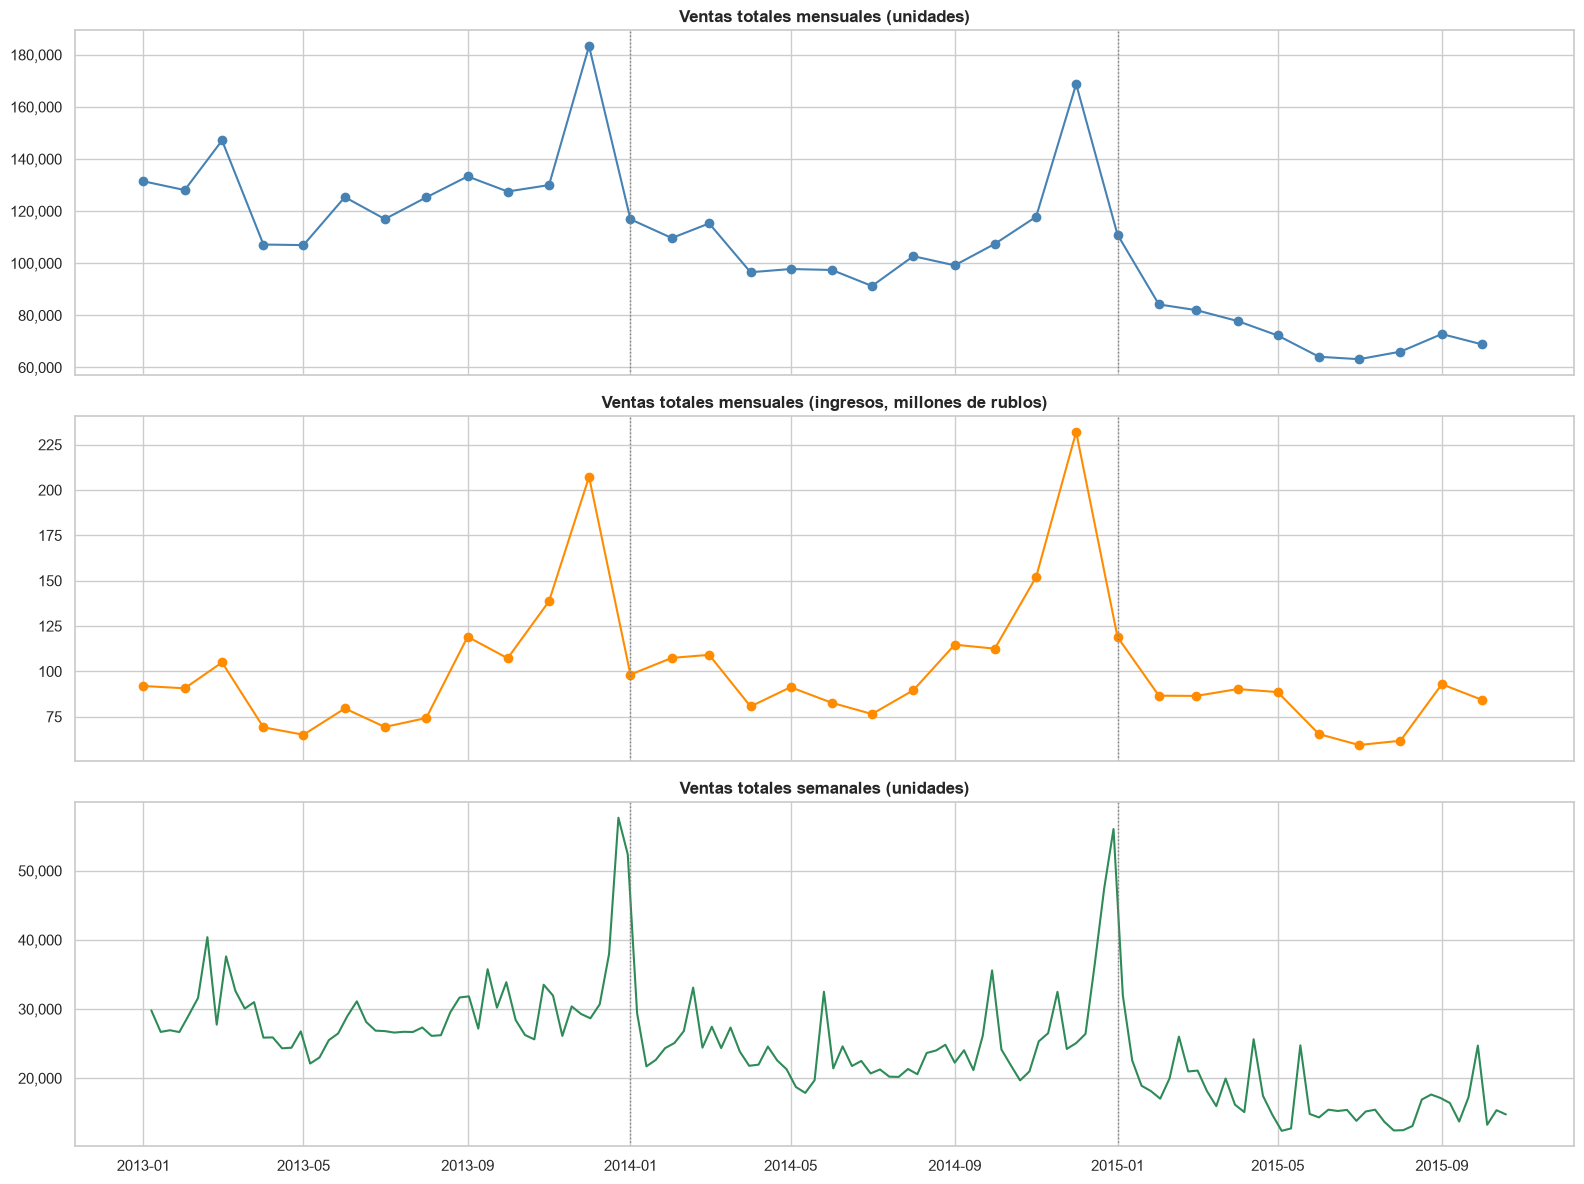

In [54]:
# ===== 8.a Serie de tiempo de ventas totales =====
# Recalculamos las series con el dataset limpio: unidades e ingresos mensuales y unidades semanales.
mensual = df.groupby("year_month").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))  # Serie mensual limpia
semanal = df.groupby("week")["item_cnt_day"].sum().iloc[1:-1]  # Serie semanal limpia (sin semanas incompletas)

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)
axes[0].plot(mensual.index, mensual["unidades"], marker="o", color="steelblue")  # Unidades mensuales
axes[0].set_title("Ventas totales mensuales (unidades)")
axes[1].plot(mensual.index, mensual["ingresos"] / 1e6, marker="o", color="darkorange")  # Ingresos mensuales
axes[1].set_title("Ventas totales mensuales (ingresos, millones de rublos)")
axes[2].plot(semanal.index, semanal.values, color="seagreen")  # Unidades semanales
axes[2].set_title("Ventas totales semanales (unidades)")
for ax in axes:
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))  # Miles con separador
    for anio in [2014, 2015]:
        ax.axvline(pd.Timestamp(f"{anio}-01-01"), color="gray", ls=":", lw=1)  # Separador de años
plt.tight_layout()
plt.show()

### 8.b Ventas por sucursal

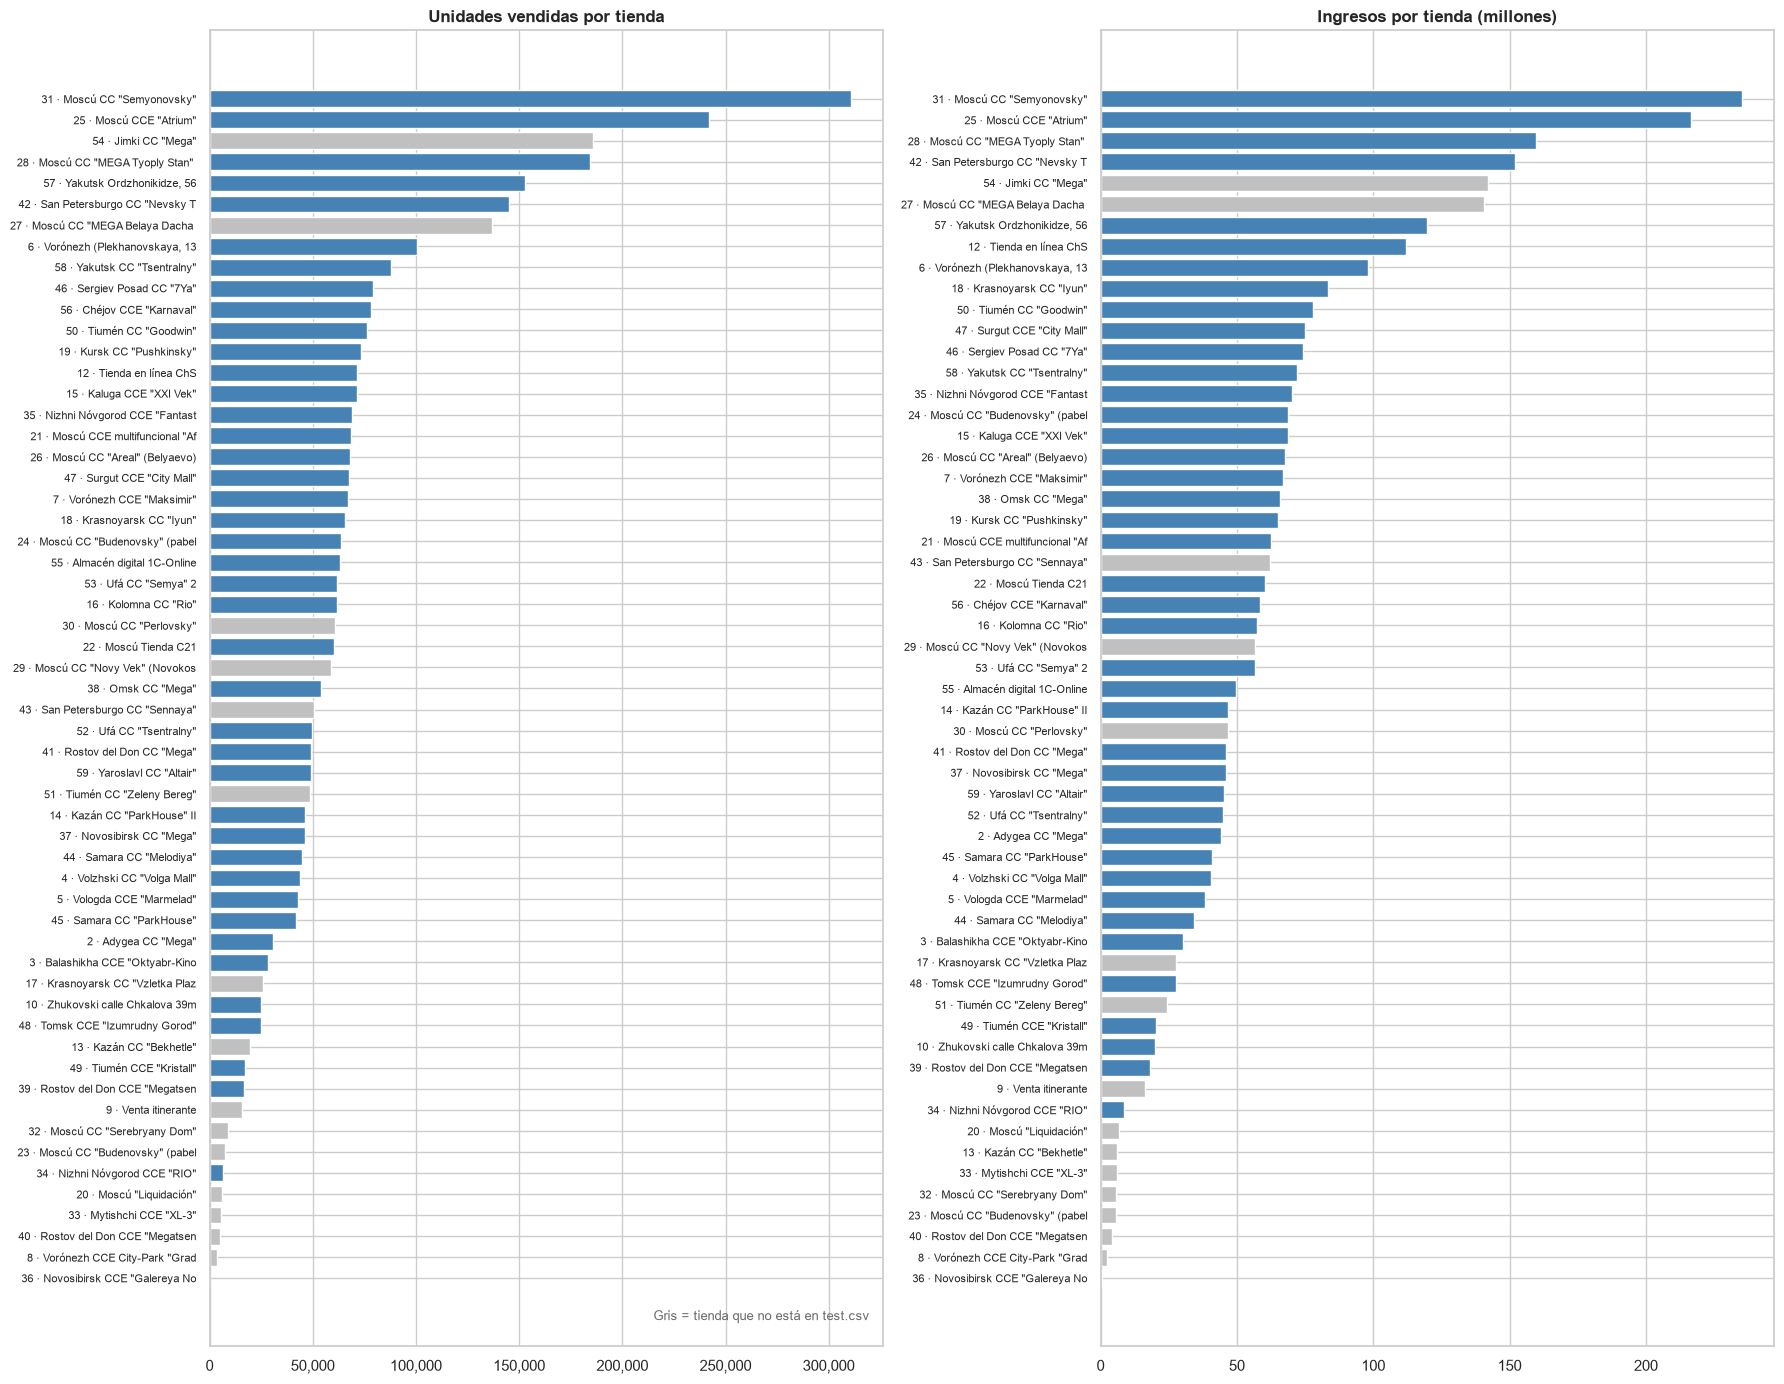

In [55]:
# ===== 8.b Gráfico de barras: ventas por sucursal =====
# Unidades totales e ingresos totales por tienda, ordenadas de mayor a menor. Las tiendas que no están en test se marcan en gris.
por_tienda = df.groupby(["shop_id", "shop_name"]).agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum")).reset_index()  # Totales por tienda
por_tienda["etiqueta"] = por_tienda["shop_id"].astype(str) + " · " + por_tienda["shop_name"].str.slice(0, 28)  # Etiqueta legible
por_tienda["color"] = np.where(por_tienda["shop_id"].isin(test["shop_id"]), "steelblue", "silver")  # Color según presencia en test

fig, axes = plt.subplots(1, 2, figsize=(18, 14))
for ax, metrica, titulo in zip(axes, ["unidades", "ingresos"], ["Unidades vendidas por tienda", "Ingresos por tienda (millones)"]):
    datos = por_tienda.sort_values(metrica)  # Orden ascendente para que la mayor quede arriba
    valores = datos[metrica] / (1e6 if metrica == "ingresos" else 1)  # Ingresos en millones
    ax.barh(datos["etiqueta"], valores, color=datos["color"])  # Barras horizontales
    ax.set_title(titulo)
    ax.tick_params(axis="y", labelsize=8)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[0].text(0.98, 0.02, "Gris = tienda que no está en test.csv", transform=axes[0].transAxes, ha="right", fontsize=9, color="dimgray")
plt.tight_layout()
plt.show()

### 8.c Ventas por producto (top N) y por categoría

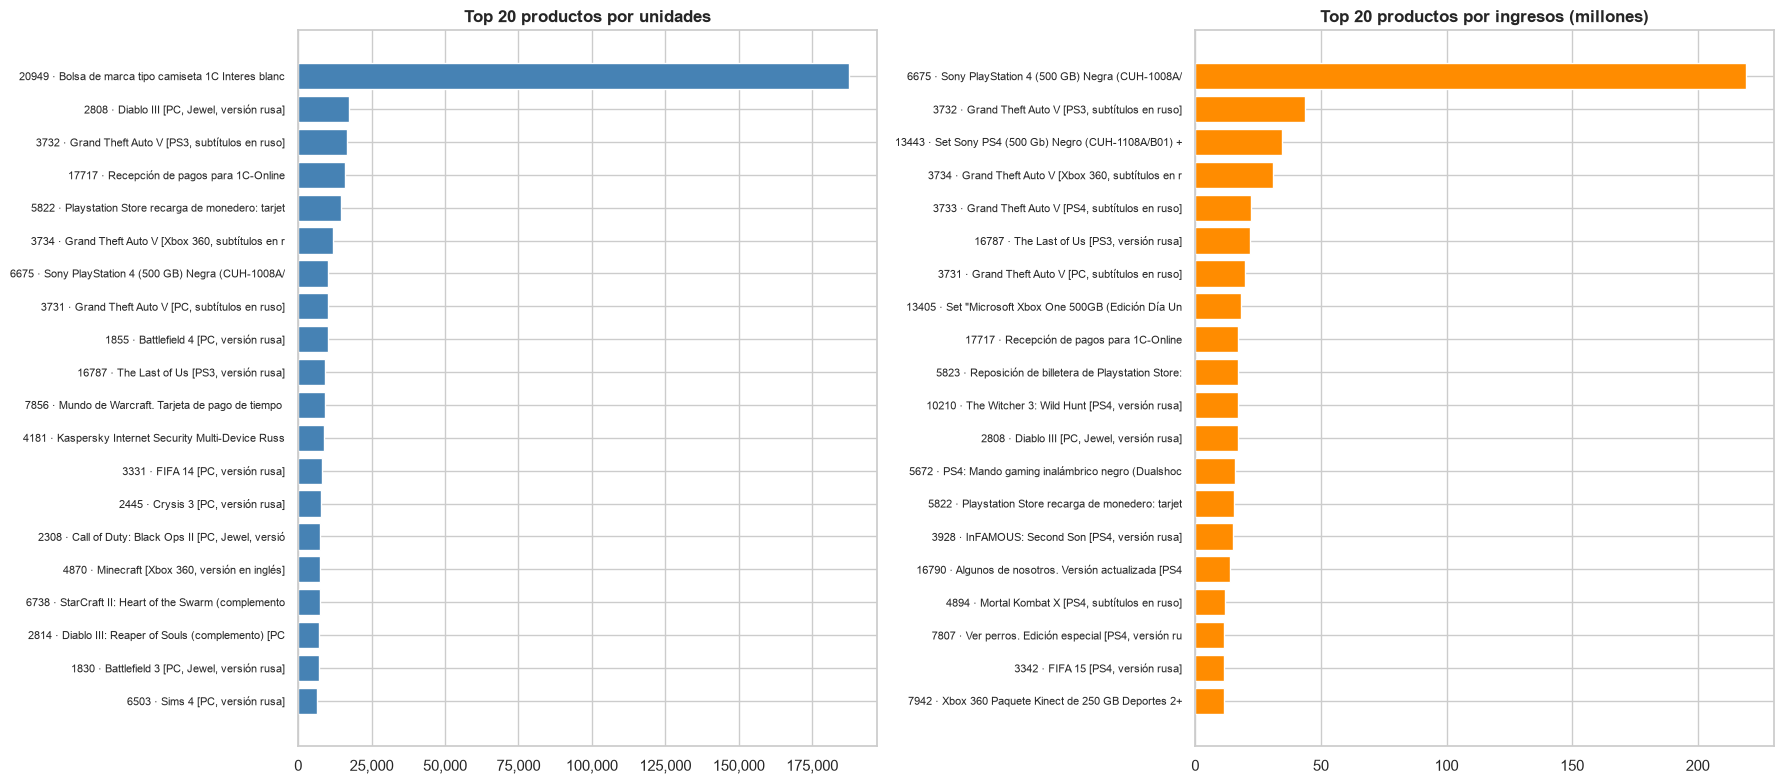

In [56]:
# ===== 8.c Gráfico de barras: top 20 productos =====
# Los 20 productos con más unidades vendidas y los 20 con más ingresos (nombres truncados a 45 caracteres).
por_producto = df.groupby(["item_id", "item_name"]).agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum")).reset_index()  # Totales por producto
por_producto["etiqueta"] = por_producto["item_id"].astype(str) + " · " + por_producto["item_name"].str.slice(0, 45)  # Etiqueta legible

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
top_u = por_producto.nlargest(20, "unidades").sort_values("unidades")  # Top 20 por unidades
axes[0].barh(top_u["etiqueta"], top_u["unidades"], color="steelblue")
axes[0].set_title("Top 20 productos por unidades")
top_i = por_producto.nlargest(20, "ingresos").sort_values("ingresos")  # Top 20 por ingresos
axes[1].barh(top_i["etiqueta"], top_i["ingresos"] / 1e6, color="darkorange")
axes[1].set_title("Top 20 productos por ingresos (millones)")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

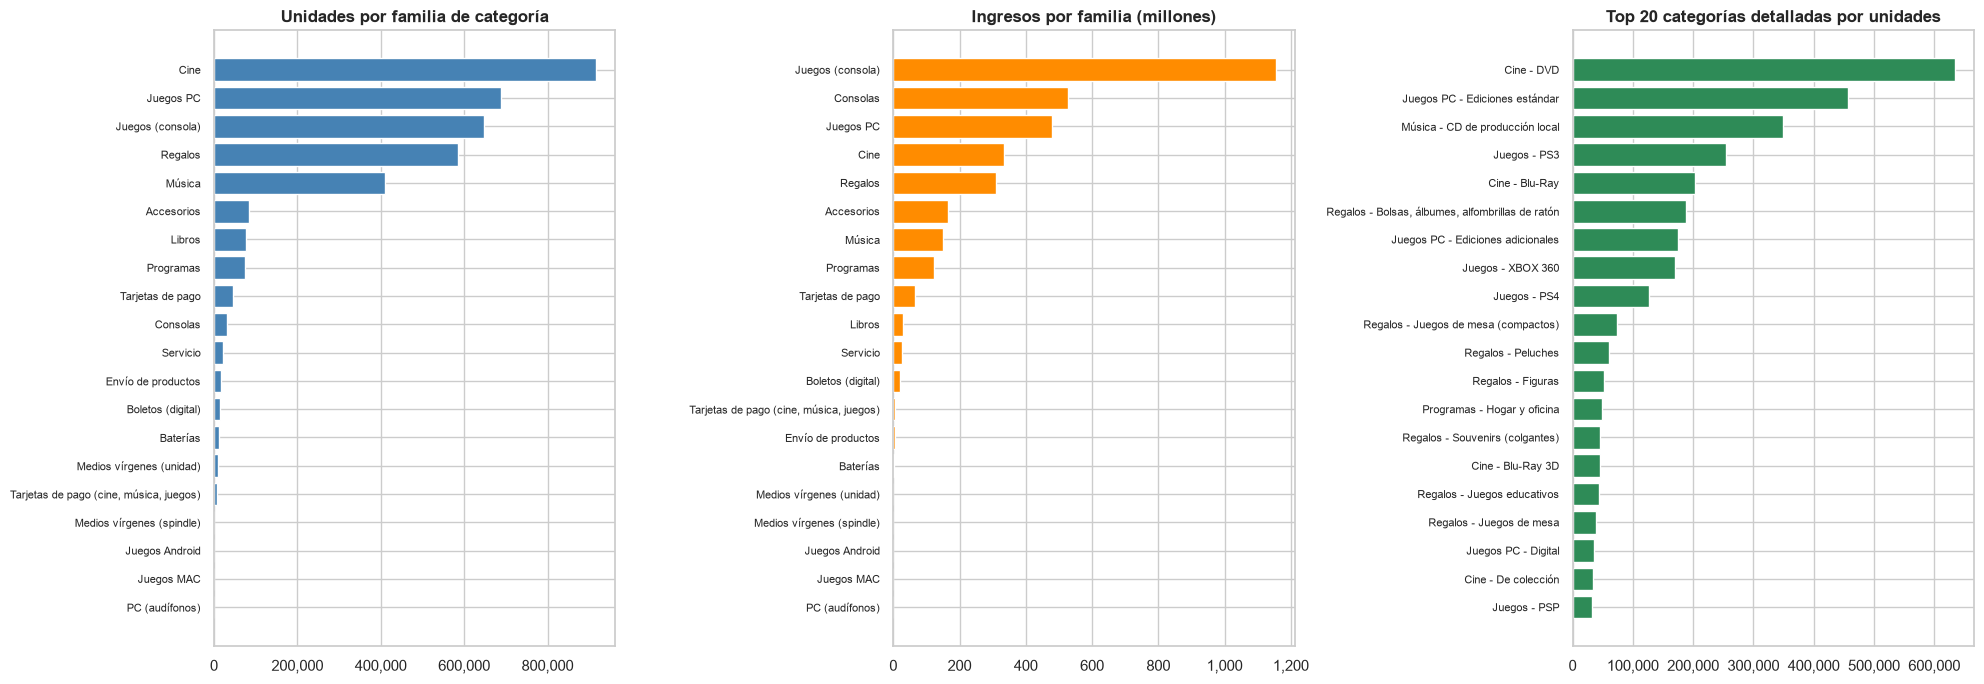

In [57]:
# ===== 8.c Gráfico de barras: ventas por categoría =====
# Unidades e ingresos por familia de categoría (20 familias) y top 20 de las categorías detalladas.
por_familia = df.groupby("familia").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))  # Totales por familia
por_cat = df.groupby("item_category_name")["item_cnt_day"].sum().nlargest(20).sort_values()  # Top 20 categorías detalladas

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
d = por_familia.sort_values("unidades")
axes[0].barh(d.index, d["unidades"], color="steelblue")  # Unidades por familia
axes[0].set_title("Unidades por familia de categoría")
d = por_familia.sort_values("ingresos")
axes[1].barh(d.index, d["ingresos"] / 1e6, color="darkorange")  # Ingresos por familia
axes[1].set_title("Ingresos por familia (millones)")
axes[2].barh(por_cat.index, por_cat.values, color="seagreen")  # Top 20 categorías detalladas
axes[2].set_title("Top 20 categorías detalladas por unidades")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.tight_layout()
plt.show()

### 8.d Heatmaps: ventas en el tiempo por sucursal y por categoría

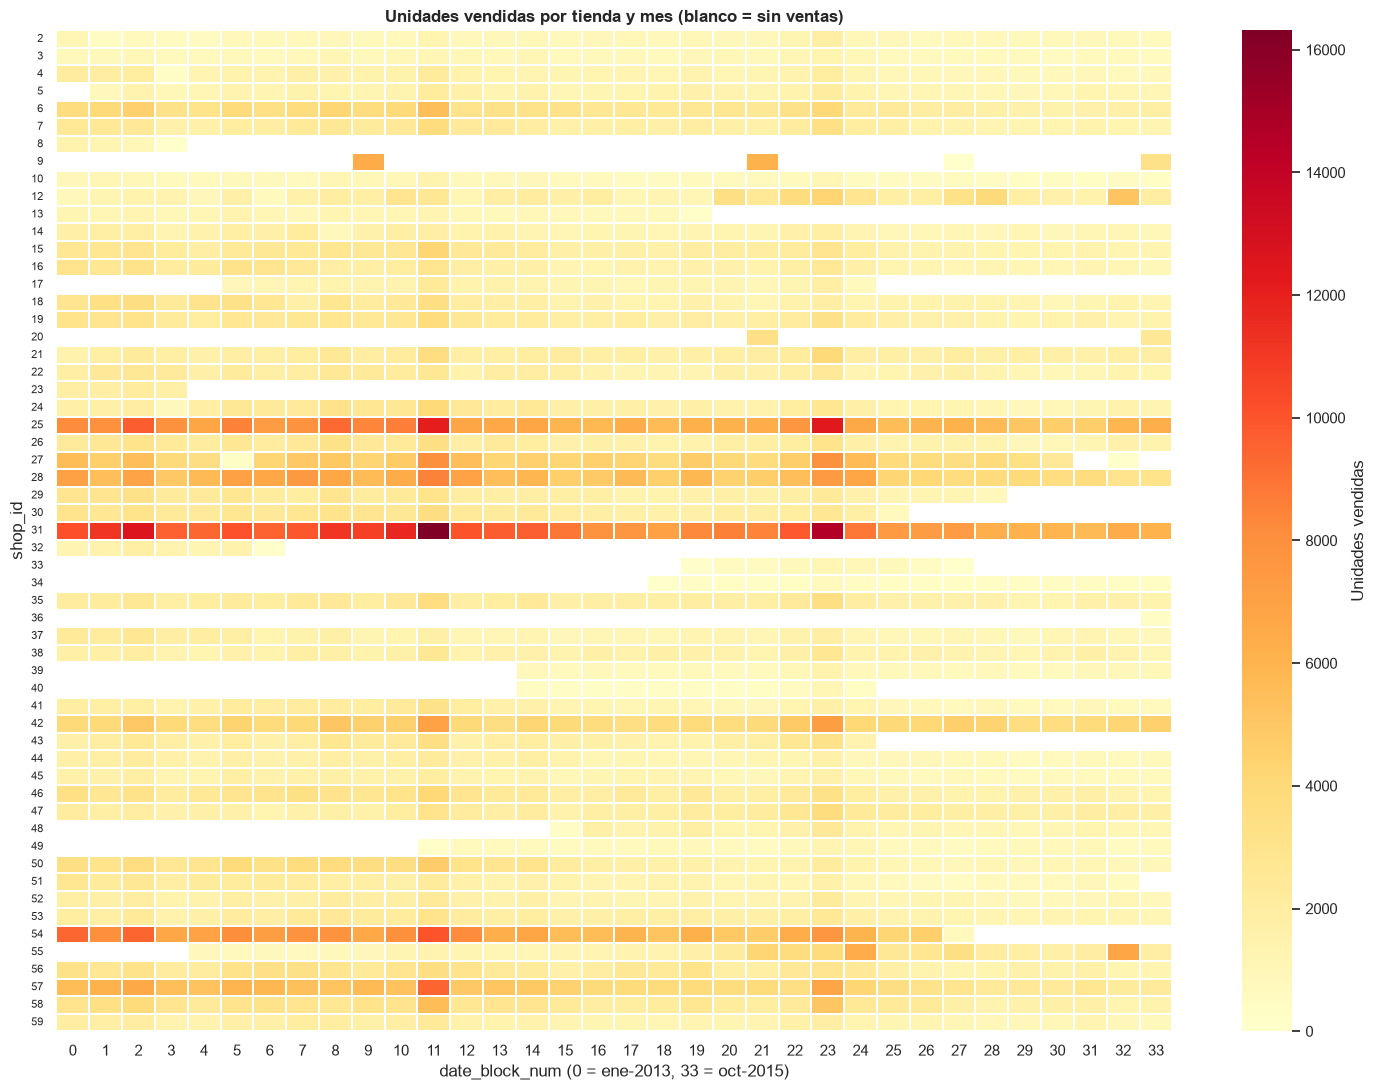

In [58]:
# ===== 8.d Heatmap: unidades por tienda y mes =====
# Matriz tienda x mes (date_block_num). Las celdas vacías (blancas) indican meses sin ventas en esa tienda.
matriz_tienda = df.pivot_table(index="shop_id", columns="date_block_num", values="item_cnt_day", aggfunc="sum")  # Tienda x mes
fig, ax = plt.subplots(figsize=(18, 13))
sns.heatmap(matriz_tienda, cmap="YlOrRd", linewidths=0.2, yticklabels=True, cbar_kws={"label": "Unidades vendidas"}, ax=ax)  # Mapa de calor (todas las tiendas etiquetadas)
ax.grid(False)  # Quitamos la cuadrícula del estilo para que las celdas vacías se vean limpias
ax.tick_params(axis="y", labelsize=8, rotation=0)  # Etiquetas de tienda legibles
ax.set_title("Unidades vendidas por tienda y mes (blanco = sin ventas)")
ax.set_xlabel("date_block_num (0 = ene-2013, 33 = oct-2015)")
ax.set_ylabel("shop_id")
plt.show()

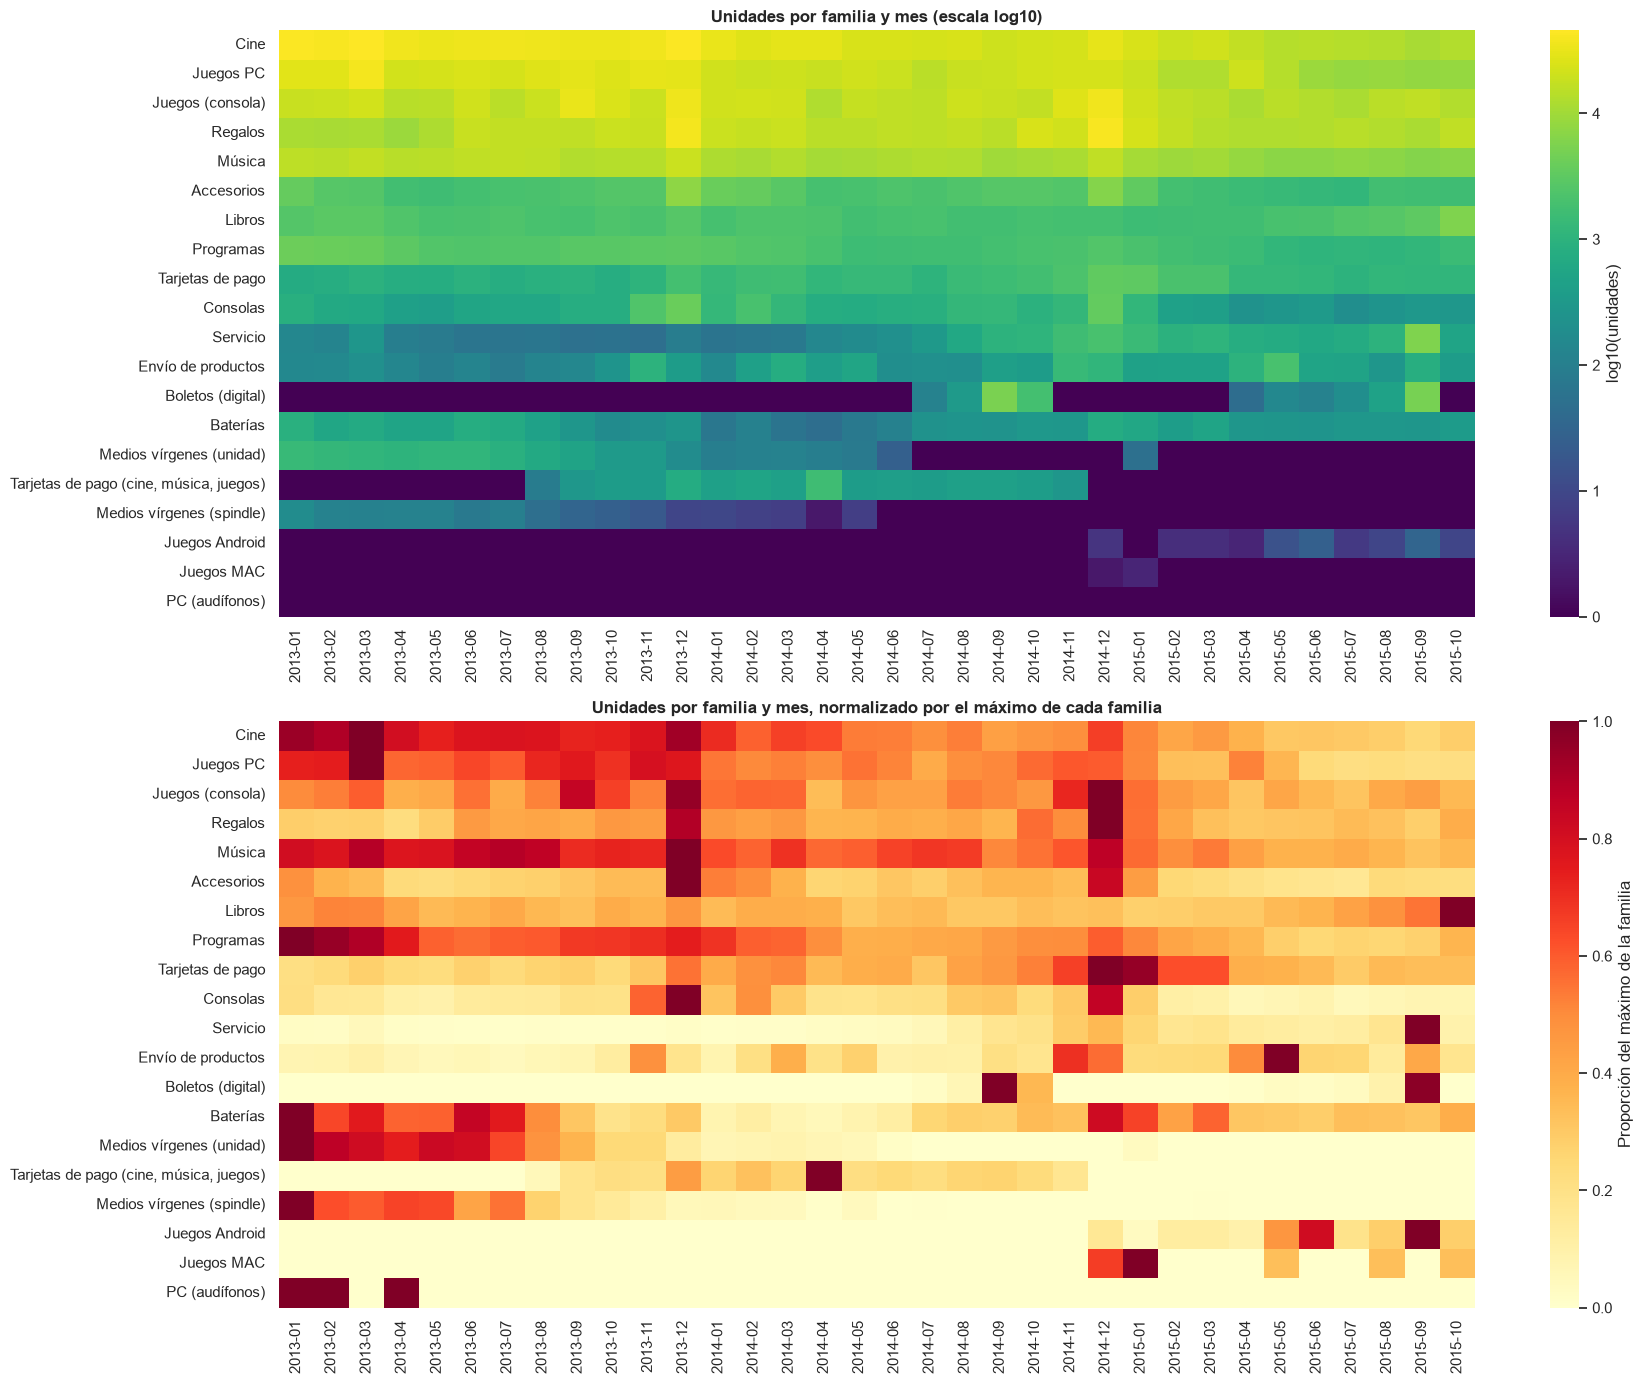

In [59]:
# ===== 8.d Heatmap: unidades por familia de categoría y mes =====
# Matriz familia x mes. Normalizamos cada fila por su máximo (0-1) para comparar la FORMA temporal de cada familia,
# sin que las familias grandes opaquen a las pequeñas.
matriz_familia = df.pivot_table(index="familia", columns="year_month", values="item_cnt_day", aggfunc="sum").fillna(0)  # Familia x mes
matriz_familia = matriz_familia.loc[matriz_familia.sum(axis=1).sort_values(ascending=False).index]  # Orden por volumen
matriz_familia.columns = matriz_familia.columns.strftime("%Y-%m")  # Etiquetas de mes legibles
normalizada = matriz_familia.div(matriz_familia.max(axis=1).where(lambda s: s > 0), axis=0)  # Cada fila / su máximo

fig, axes = plt.subplots(2, 1, figsize=(18, 14))
sns.heatmap(np.log10(matriz_familia.clip(lower=1)), cmap="viridis", ax=axes[0], cbar_kws={"label": "log10(unidades)"})  # Volumen absoluto (escala log)
axes[0].set_title("Unidades por familia y mes (escala log10)")
sns.heatmap(normalizada, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "Proporción del máximo de la familia"})  # Forma temporal
axes[1].set_title("Unidades por familia y mes, normalizado por el máximo de cada familia")
for ax in axes:
    ax.grid(False)  # Sin cuadrícula sobre el mapa de calor
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretación de la sección 8:**
- **8.a Serie total:** las tres vistas (unidades mensuales, ingresos mensuales y unidades semanales) muestran la tendencia
  decreciente en unidades y los picos de diciembre. Los ingresos se mantienen más estables, con picos aún más pronunciados en
  diciembre por la venta de consolas y juegos.
- **8.b Sucursales:** el desempeño está muy concentrado en pocas tiendas grandes (31, 25, 54, 28, 57, 42, 27).
  - Varias tiendas en gris (no están en test) tienen volúmenes relevantes (54, 27) porque cerraron antes de noviembre 2015;
    su historial sirve para aprender patrones pero no se predicen.
  - La tienda online 12 tiene el precio promedio por unidad más alto de la cadena (~1,590 rublos), por lo que su peso en
    ingresos es mayor que en unidades.
- **8.c Productos y categorías:**
  - La bolsa 20949 domina el ranking por unidades, mientras que el ranking por ingresos lo dominan consolas y videojuegos de
    lanzamiento.
  - Por familia, Cine es el líder en unidades pero Juegos de consola y Consolas lideran en ingresos.
- **8.d Heatmaps:**
  - *Tienda × mes:* muestra con claridad las **aperturas y cierres de tiendas** (celdas en blanco: p. ej. 8, 23 y 32 cierran
    temprano, y 54 deja de vender en el mes 27) y la columna más intensa en los meses 11 y 23 (**diciembres**) en casi todas
    las tiendas.
  - *Familia × mes (normalizado):* **Cine, Música, Programas y Juegos PC pierden peso** en el tiempo (pasan de colores oscuros
    a claros).
  - **Juegos de consola, Regalos, Accesorios y Consolas tienen su máximo en diciembre**.
  - Hay familias que **desaparecen**: *Medios vírgenes* desde mediados de 2014 y *Tarjetas de pago (cine, música, juegos)*
    después de noviembre 2014.
  - Otras **aparecen**: *Juegos Android* desde diciembre 2014.
  - *Boletos (digital)* tiene picos en septiembre de 2014 y 2015, y *Servicio* en septiembre de 2015, lo que coincide con
    las ventas de boletos de *IgroMir* vistas en 7.c.2.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)

Series analizadas (selección representativa por volumen de unidades vendidas):

- **Ventas totales**: mensual (34 observaciones) y diaria (1,034 observaciones).
- **Ventas por sucursal**: las 3 tiendas con más unidades vendidas (mensual).
- **Ventas por producto**: los 3 productos con más unidades vendidas (mensual).
- **Ventas por sucursal-producto**: los 3 pares tienda-producto con más unidades vendidas (mensual).

En las series mensuales los meses sin ventas se completan con 0 (no vender es una observación real de venta cero).
Con 34 observaciones se usan hasta 15 rezagos (el PACF requiere menos de la mitad de las observaciones).
La banda sombreada es el intervalo de confianza del 95%: las barras que salen de ella son significativas.

In [60]:
# ===== 9. Función auxiliar para ACF / PACF =====
# Grafica ACF y PACF lado a lado y devuelve los rezagos significativos (al 95%) para interpretarlos con números.
def rezagos_significativos(valores, nlags, funcion):
    """Devuelve los rezagos cuyo coeficiente sale de la banda de confianza del 95% (aprox. ±1.96/sqrt(n))."""
    coef = funcion(valores, nlags=nlags)  # Coeficientes ACF o PACF (posición 0 = rezago 0)
    banda = 1.96 / np.sqrt(len(valores))  # Banda de significancia aproximada
    return [(k, round(float(coef[k]), 2)) for k in range(1, nlags + 1) if abs(coef[k]) > banda]  # Rezagos fuera de la banda

resultados_acf = []  # Tabla resumen de todas las series analizadas

def analizar_acf_pacf(serie, titulo, nlags):
    """Grafica ACF y PACF de una serie y guarda sus rezagos significativos."""
    valores = serie.astype(float).values  # Serie como arreglo numérico
    fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
    plot_acf(valores, lags=nlags, ax=axes[0])  # Gráfico de autocorrelación
    plot_pacf(valores, lags=nlags, ax=axes[1], method="ywm")  # Gráfico de autocorrelación parcial
    axes[0].set_title(f"ACF — {titulo}")
    axes[1].set_title(f"PACF — {titulo}")
    plt.tight_layout()
    plt.show()
    sig_acf = rezagos_significativos(valores, nlags, acf)  # Rezagos significativos en ACF
    sig_pacf = rezagos_significativos(valores, nlags, lambda x, nlags: pacf(x, nlags=nlags, method="ywm"))  # Rezagos significativos en PACF
    print("Rezagos significativos ACF (rezago, coef):", sig_acf)
    print("Rezagos significativos PACF (rezago, coef):", sig_pacf)
    resultados_acf.append({"serie": titulo, "n_obs": len(valores), "ACF_significativos": [k for k, _ in sig_acf], "PACF_significativos": [k for k, _ in sig_pacf]})

meses = range(df["date_block_num"].min(), df["date_block_num"].max() + 1)  # Índice completo de meses 0..33

### 9.1 Ventas totales

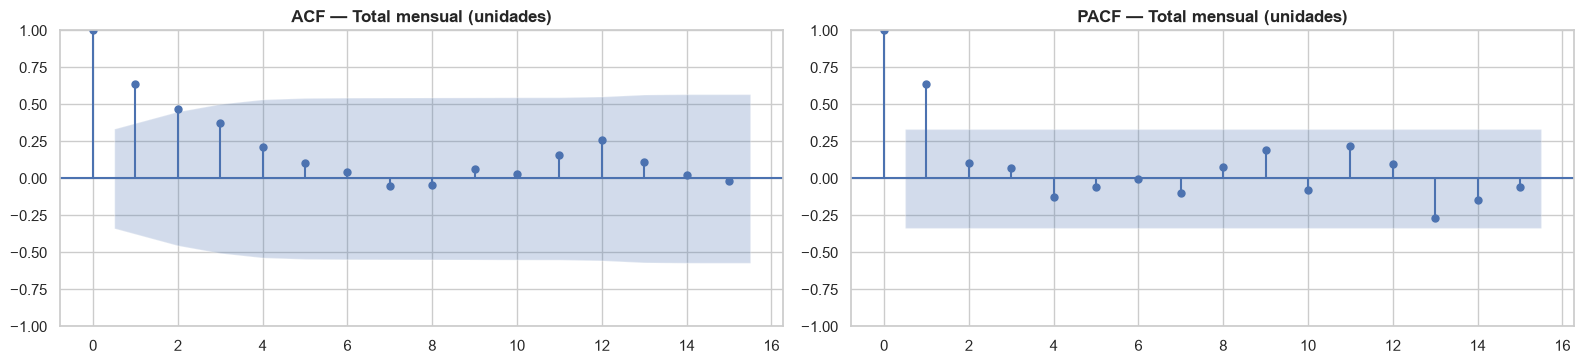

Rezagos significativos ACF (rezago, coef): [(1, 0.64), (2, 0.47), (3, 0.37)]
Rezagos significativos PACF (rezago, coef): [(1, 0.64)]


In [61]:
# ===== 9.1.a Ventas totales mensuales =====
# ACF/PACF de las unidades totales por mes (34 observaciones, 15 rezagos).
total_mensual = df.groupby("date_block_num")["item_cnt_day"].sum().reindex(meses, fill_value=0)  # Serie mensual completa
analizar_acf_pacf(total_mensual, "Total mensual (unidades)", nlags=15)

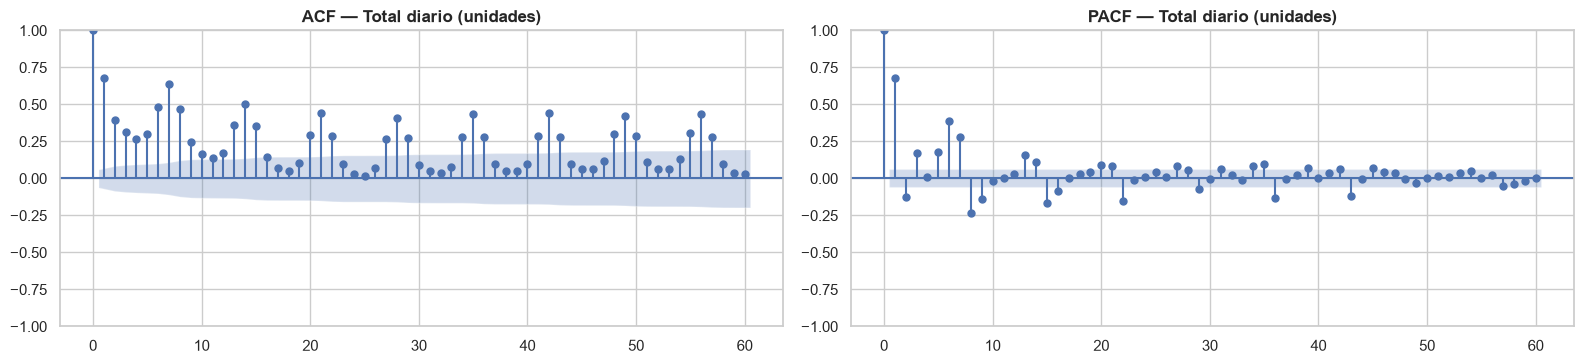

Rezagos significativos ACF (rezago, coef): [(1, 0.68), (2, 0.4), (3, 0.31), (4, 0.27), (5, 0.3), (6, 0.48), (7, 0.64), (8, 0.47), (9, 0.25), (10, 0.17), (11, 0.14), (12, 0.17), (13, 0.36), (14, 0.51), (15, 0.35), (16, 0.14), (17, 0.07), (19, 0.1), (20, 0.29), (21, 0.44), (22, 0.29), (23, 0.1), (26, 0.07), (27, 0.26), (28, 0.41), (29, 0.27), (30, 0.09), (33, 0.08), (34, 0.28), (35, 0.44), (36, 0.28), (37, 0.1), (40, 0.1), (41, 0.29), (42, 0.44), (43, 0.28), (44, 0.1), (45, 0.07), (46, 0.06), (47, 0.12), (48, 0.3), (49, 0.42), (50, 0.28), (51, 0.11), (52, 0.07), (53, 0.06), (54, 0.13), (55, 0.31), (56, 0.43), (57, 0.28), (58, 0.09)]
Rezagos significativos PACF (rezago, coef): [(1, 0.68), (2, -0.12), (3, 0.17), (5, 0.18), (6, 0.39), (7, 0.28), (8, -0.23), (9, -0.14), (13, 0.16), (14, 0.11), (15, -0.16), (16, -0.08), (20, 0.09), (21, 0.08), (22, -0.15), (27, 0.09), (29, -0.07), (31, 0.06), (34, 0.08), (35, 0.1), (36, -0.13), (39, 0.07), (42, 0.07), (43, -0.12), (45, 0.07)]


In [62]:
# ===== 9.1.b Ventas totales diarias =====
# ACF/PACF de las unidades totales por día (1,034 observaciones). Usamos 60 rezagos para ver los ciclos semanales.
total_diario = df.groupby("date")["item_cnt_day"].sum().asfreq("D", fill_value=0)  # Serie diaria completa
analizar_acf_pacf(total_diario, "Total diario (unidades)", nlags=60)

### 9.2 Ventas por sucursal (top 3 tiendas)

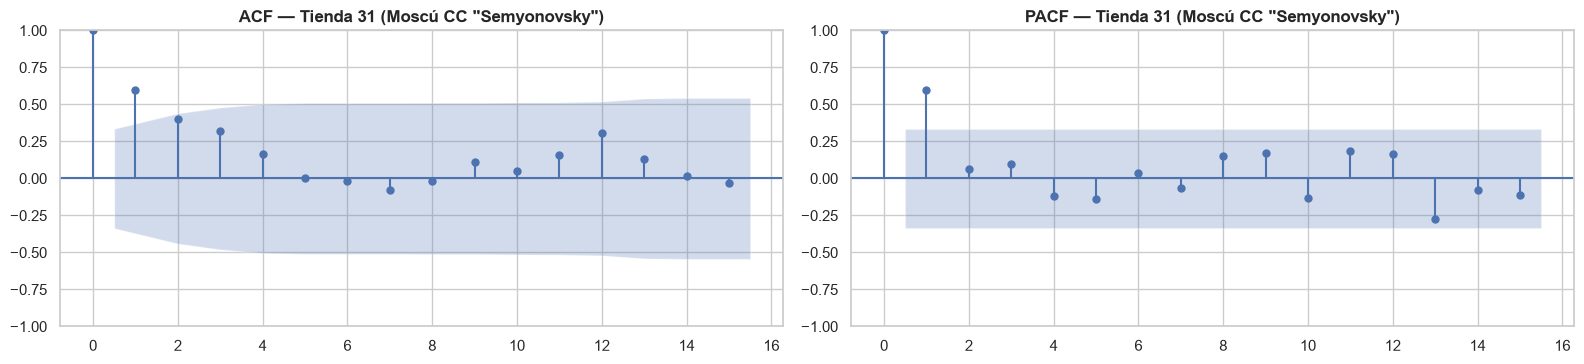

Rezagos significativos ACF (rezago, coef): [(1, 0.6), (2, 0.4)]
Rezagos significativos PACF (rezago, coef): [(1, 0.6)]


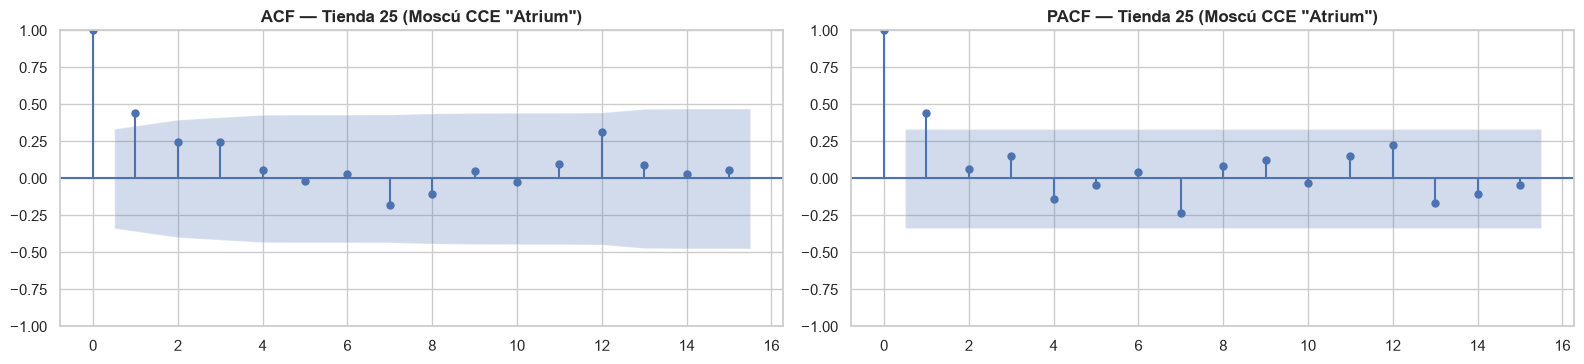

Rezagos significativos ACF (rezago, coef): [(1, 0.44)]
Rezagos significativos PACF (rezago, coef): [(1, 0.44)]


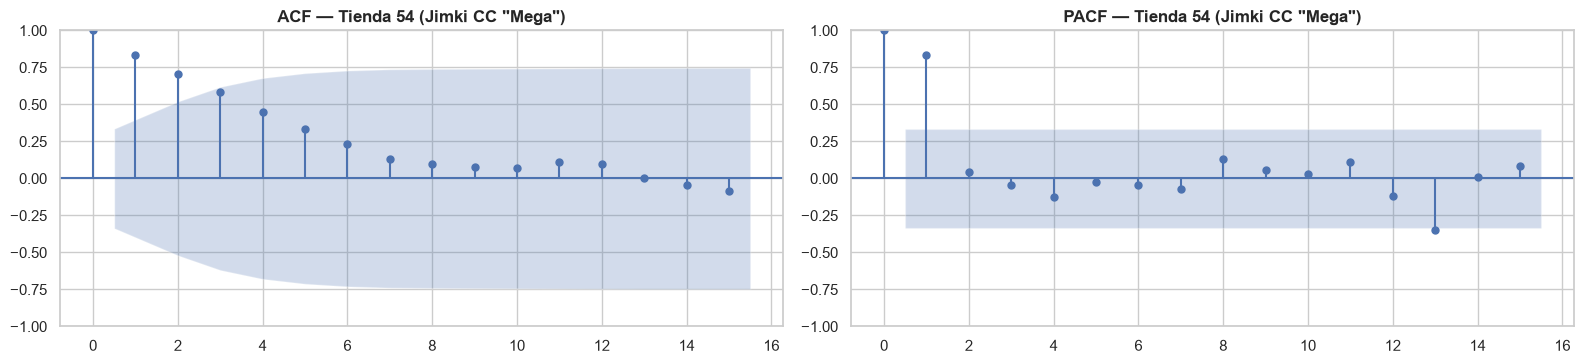

Rezagos significativos ACF (rezago, coef): [(1, 0.83), (2, 0.71), (3, 0.59), (4, 0.45), (5, 0.34)]
Rezagos significativos PACF (rezago, coef): [(1, 0.83), (13, -0.35)]


In [63]:
# ===== 9.2 Ventas mensuales de las 3 tiendas con más unidades =====
# Seleccionamos las 3 tiendas de mayor volumen y analizamos su serie mensual.
top_tiendas = df.groupby("shop_id")["item_cnt_day"].sum().nlargest(3).index  # IDs de las 3 tiendas top
for s in top_tiendas:  # Una serie por tienda
    serie = df[df["shop_id"] == s].groupby("date_block_num")["item_cnt_day"].sum().reindex(meses, fill_value=0)  # Serie mensual de la tienda
    nombre = shops.set_index("shop_id").loc[s, "shop_name"]  # Nombre de la tienda
    analizar_acf_pacf(serie, f"Tienda {s} ({nombre})", nlags=15)

### 9.3 Ventas por producto (top 3 productos)

Producto 20949: meses con venta = 31 de 34


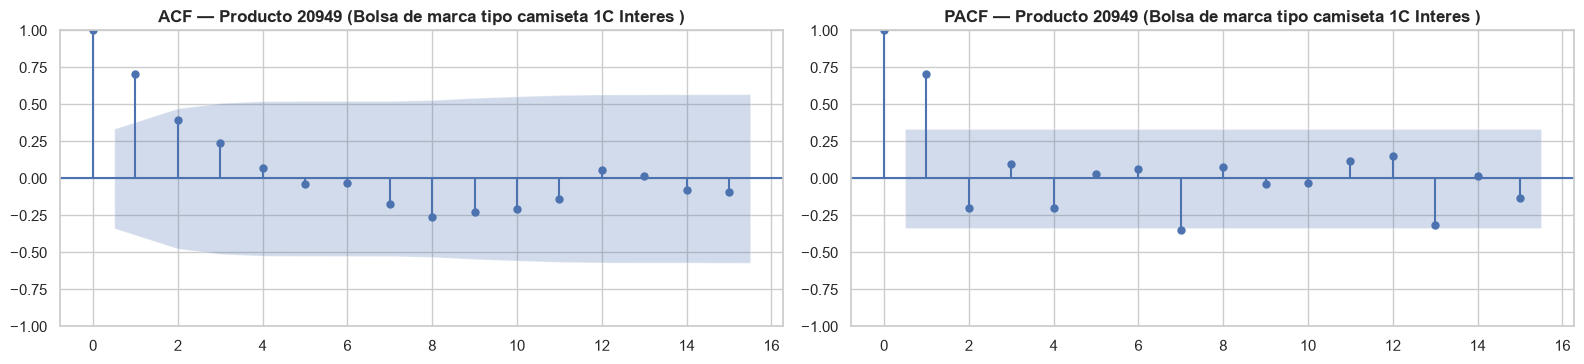

Rezagos significativos ACF (rezago, coef): [(1, 0.7), (2, 0.39)]
Rezagos significativos PACF (rezago, coef): [(1, 0.7), (7, -0.35)]
Producto 2808: meses con venta = 34 de 34


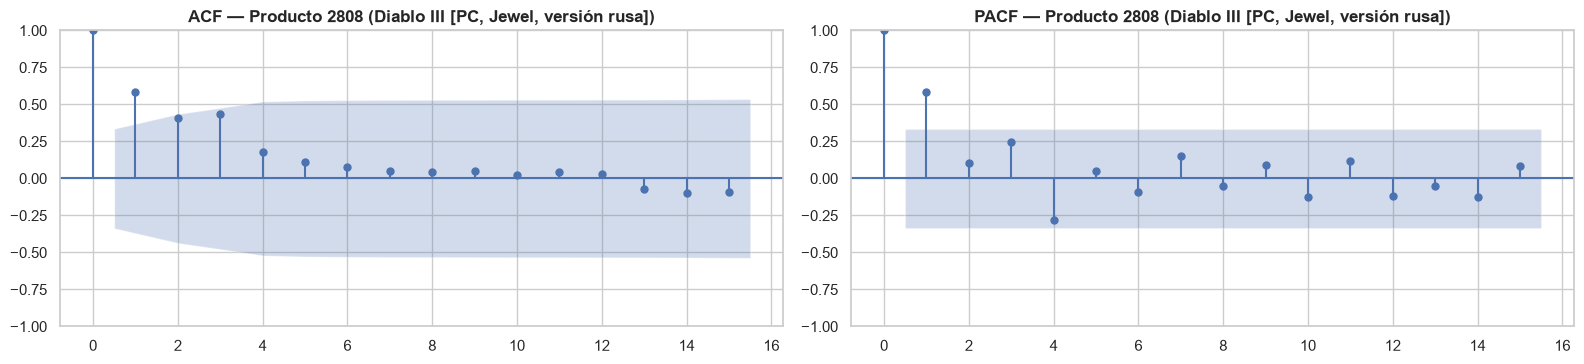

Rezagos significativos ACF (rezago, coef): [(1, 0.58), (2, 0.41), (3, 0.44)]
Rezagos significativos PACF (rezago, coef): [(1, 0.58)]
Producto 3732: meses con venta = 26 de 34


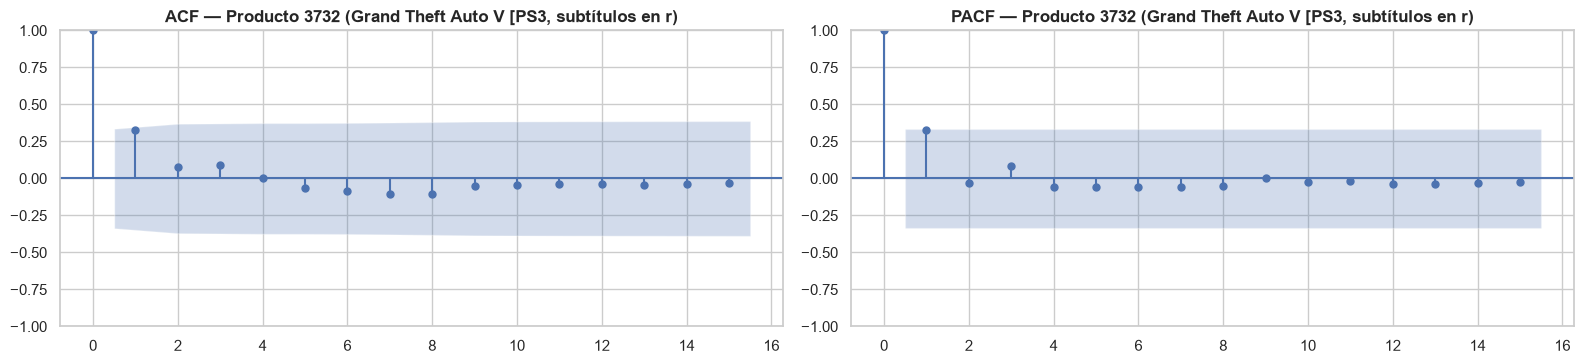

Rezagos significativos ACF (rezago, coef): []
Rezagos significativos PACF (rezago, coef): []


In [64]:
# ===== 9.3 Ventas mensuales de los 3 productos con más unidades =====
# Seleccionamos los 3 productos de mayor volumen (en todas las tiendas) y analizamos su serie mensual.
top_productos = df.groupby("item_id")["item_cnt_day"].sum().nlargest(3).index  # IDs de los 3 productos top
for i in top_productos:  # Una serie por producto
    serie = df[df["item_id"] == i].groupby("date_block_num")["item_cnt_day"].sum().reindex(meses, fill_value=0)  # Serie mensual del producto
    nombre = items.set_index("item_id").loc[i, "item_name"][:40]  # Nombre truncado
    print(f"Producto {i}: meses con venta = {(serie != 0).sum()} de {len(serie)}")
    analizar_acf_pacf(serie, f"Producto {i} ({nombre})", nlags=15)

### 9.4 Ventas por sucursal-producto (top 3 pares)

Par tienda 31 - producto 20949: meses con venta = 30 de 34


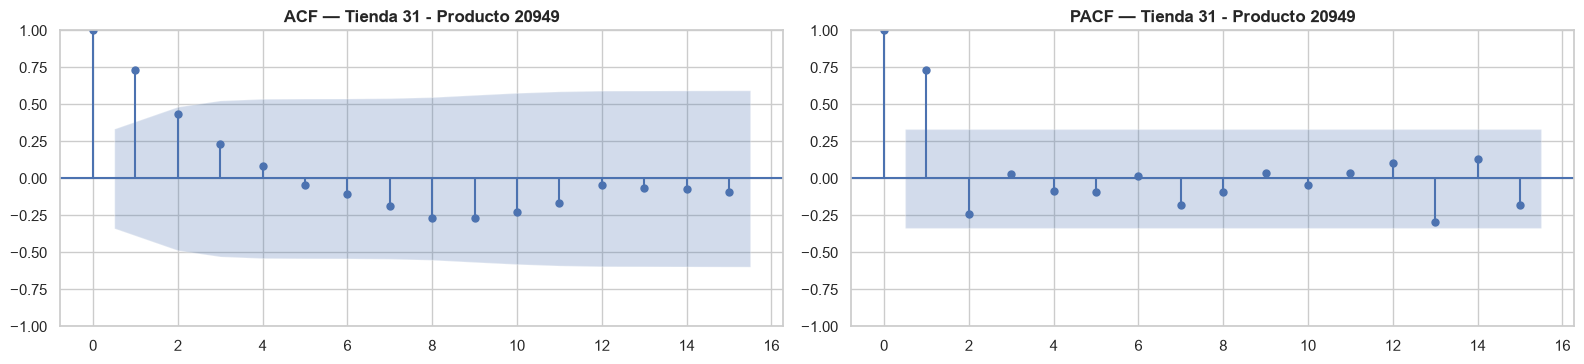

Rezagos significativos ACF (rezago, coef): [(1, 0.74), (2, 0.43)]
Rezagos significativos PACF (rezago, coef): [(1, 0.74)]
Par tienda 25 - producto 20949: meses con venta = 29 de 34


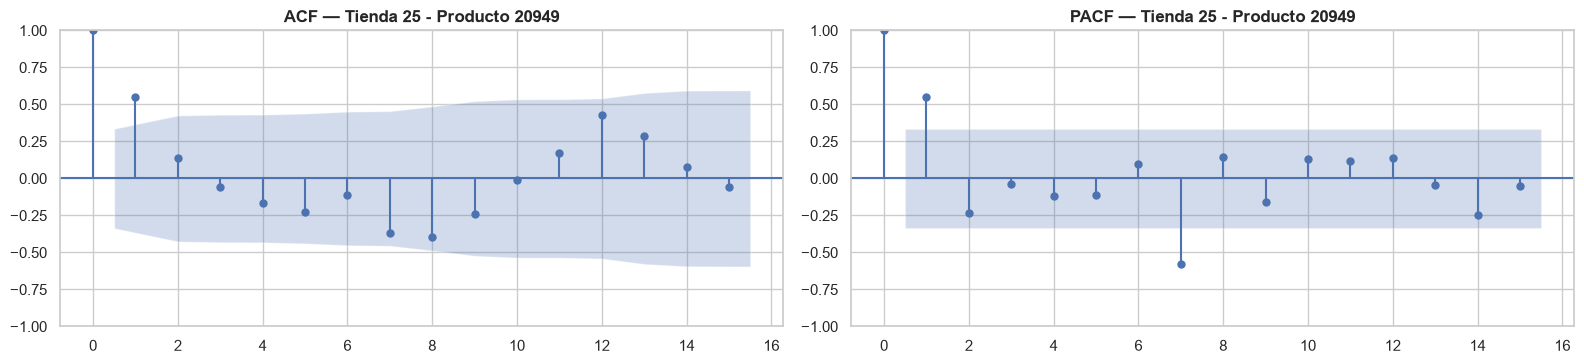

Rezagos significativos ACF (rezago, coef): [(1, 0.55), (7, -0.37), (8, -0.4), (12, 0.43)]
Rezagos significativos PACF (rezago, coef): [(1, 0.55), (7, -0.58)]
Par tienda 28 - producto 20949: meses con venta = 31 de 34


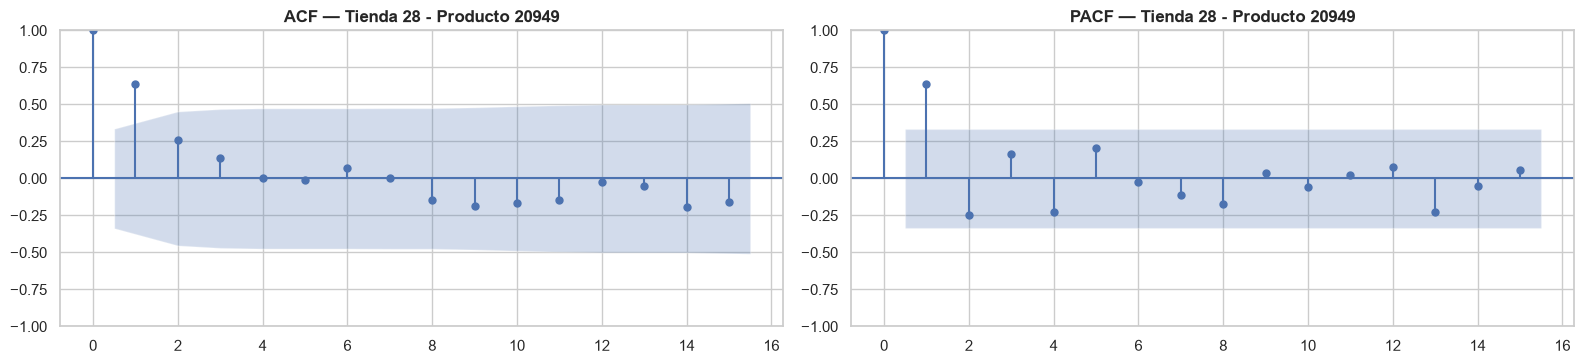

Rezagos significativos ACF (rezago, coef): [(1, 0.64)]
Rezagos significativos PACF (rezago, coef): [(1, 0.64)]


In [65]:
# ===== 9.4 Ventas mensuales de los 3 pares tienda-producto con más unidades =====
# Seleccionamos los 3 pares de mayor volumen y analizamos su serie mensual.
top_pares = df.groupby(["shop_id", "item_id"])["item_cnt_day"].sum().nlargest(3).index  # Pares (tienda, producto) top
for s, i in top_pares:  # Una serie por par
    serie = df[(df["shop_id"] == s) & (df["item_id"] == i)].groupby("date_block_num")["item_cnt_day"].sum().reindex(meses, fill_value=0)  # Serie del par
    print(f"Par tienda {s} - producto {i}: meses con venta = {(serie != 0).sum()} de {len(serie)}")
    analizar_acf_pacf(serie, f"Tienda {s} - Producto {i}", nlags=15)

In [66]:
# ===== 9.5 Resumen de rezagos significativos =====
# Tabla con los rezagos significativos de ACF y PACF de todas las series analizadas.
pd.set_option("display.max_colwidth", 120)  # Mostrar listas completas
pd.DataFrame(resultados_acf)

,serie,n_obs,ACF_significativos,PACF_significativos
0,Total mensual (unidades),34,"[1, 2, 3]",[1]
1,Total diario (unidades),1034,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 33, 34, 35, 36, ...","[1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 21, 22, 27, 29, 31, 34, 35, 36, 39, 42, 43, 45]"
2,"Tienda 31 (Moscú CC ""Semyonovsky"")",34,"[1, 2]",[1]
3,"Tienda 25 (Moscú CCE ""Atrium"")",34,[1],[1]
4,"Tienda 54 (Jimki CC ""Mega"")",34,"[1, 2, 3, 4, 5]","[1, 13]"
5,Producto 20949 (Bolsa de marca tipo camiseta 1C Interes ),34,"[1, 2]","[1, 7]"
6,"Producto 2808 (Diablo III [PC, Jewel, versión rusa])",34,"[1, 2, 3]",[1]
7,"Producto 3732 (Grand Theft Auto V [PS3, subtítulos en r)",34,[],[]
8,Tienda 31 - Producto 20949,34,"[1, 2]",[1]
9,Tienda 25 - Producto 20949,34,"[1, 7, 8, 12]","[1, 7]"


**Interpretación de la sección 9:**

**i. ¿Existen correlaciones significativas a diferentes rezagos?**

| Serie | ACF significativa | PACF significativa | Lectura |
|---|---|---|---|
| Total mensual | rezagos 1–3 (0.64, 0.47, 0.37) | rezago 1 (0.64) | Decaimiento gradual del ACF y corte del PACF en 1 → comportamiento tipo **AR(1)**, con persistencia por la tendencia decreciente. |
| Total diario | casi todos los rezagos; máximos en **7, 14, 21, 28, … 56** (0.64, 0.51, 0.44, 0.41, …) | 1, 6, 7 y otros | Fuerte dependencia de corto plazo (rezago 1 = 0.68) y **estacionalidad semanal muy marcada**. |
| Tienda 31 | 1–2 | 1 | AR(1). |
| Tienda 25 | 1 | 1 | AR(1) más débil (0.44). |
| Tienda 54 | 1–5 (decaimiento lento) | 1, 13 | Serie **no estacionaria**: la tienda cierra en el mes 27 (ventas en 0 después); la tendencia domina. |
| Producto 20949 (bolsa) | 1–2 | 1, 7 | AR(1). |
| Producto 2808 (Diablo III PC) | 1–3 | 1 | AR(1) con persistencia. |
| Producto 3732 (GTA V PS3) | ninguno | ninguno | La serie está dominada por **un pico de lanzamiento** (6,972 unidades en sep-2013, ceros antes) seguido de un decaimiento; ese patrón no lo capta bien la autocorrelación lineal. |
| Tienda 31 – Producto 20949 | 1–2 | 1 | AR(1). |
| Tienda 25 – Producto 20949 | 1, 7 y 8 (negativos), **12 (+0.43)** | 1, 7 | AR(1) con indicio de **estacionalidad anual** (rezago 12). |
| Tienda 28 – Producto 20949 | 1 | 1 | AR(1). |

**Conclusión:** en prácticamente todas las series mensuales el **rezago 1 es el más importante**: el PACF se corta en el rezago
1, lo que sugiere **1 término autorregresivo (AR(1))**. Con frecuencia el ACF también es significativo en los rezagos 2–3.

**ii. ¿Se observa estacionalidad reflejada en patrones repetitivos?**
- **Diaria:** sí, muy clara. El ACF tiene picos que se repiten **cada 7 días** (7, 14, 21, … 56), lo que confirma el ciclo
  semanal visto en 6.b.iv (sábados altos, lunes bajos).
- **Mensual:** la estacionalidad anual (diciembre) es evidente en las gráficas de la sección 6, pero en el ACF mensual el
  rezago 12 **no alcanza significancia** en la serie total. Esto se debe a que solo hay 34 observaciones (menos de 3 ciclos),
  a que la banda de confianza es amplia y a que la tendencia decreciente domina la autocorrelación. Solo el par tienda 25 –
  producto 20949 muestra un rezago 12 significativo.
- Para el modelo conviene incluir explícitamente **rezagos de 1–3 meses y de 12 meses**, además de variables de calendario
  (mes, en particular diciembre).

## 10. Insights y conclusiones del EDA

### 10.a Variables que afectan directamente las ventas

In [67]:
# ===== 10.a.1 Relación precio - cantidad a nivel producto-mes =====
# Correlación de Spearman (robusta a extremos y relaciones no lineales) entre el precio promedio y las unidades vendidas.
prod_mes = df.groupby(["item_id", "date_block_num"]).agg(unidades=("item_cnt_day", "sum"), precio=("item_price", "mean")).reset_index()  # Producto-mes
rho = prod_mes[["precio", "unidades"]].corr(method="spearman").iloc[0, 1]  # Correlación de rangos
print(f"Correlación de Spearman precio vs. unidades (producto-mes): {rho:.3f}")
prod_mes["rango_precio"] = pd.qcut(prod_mes["precio"], 5, labels=["Q1 (más barato)", "Q2", "Q3", "Q4", "Q5 (más caro)"])  # Quintiles de precio
prod_mes.groupby("rango_precio", observed=True)["unidades"].agg(["mean", "median"]).rename(columns={"mean": "unidades_promedio", "median": "unidades_mediana"})

Correlación de Spearman precio vs. unidades (producto-mes): 0.111


,unidades_promedio,unidades_mediana
rango_precio,,
Q1 (más barato),10.94,3.00
Q2,9.49,4.00
Q3,16.67,5.00
Q4,17.97,4.00
Q5 (más caro),22.92,4.00


Unidades promedio por producto según su edad (0 = mes de lanzamiento):
edad_meses
0    36.20
1    42.90
2    25.50
3    20.80
4    17.30
5    17.30
6    14.70
7    13.70
8    14.30
9    13.30
10   12.90
11   12.60
12   12.30


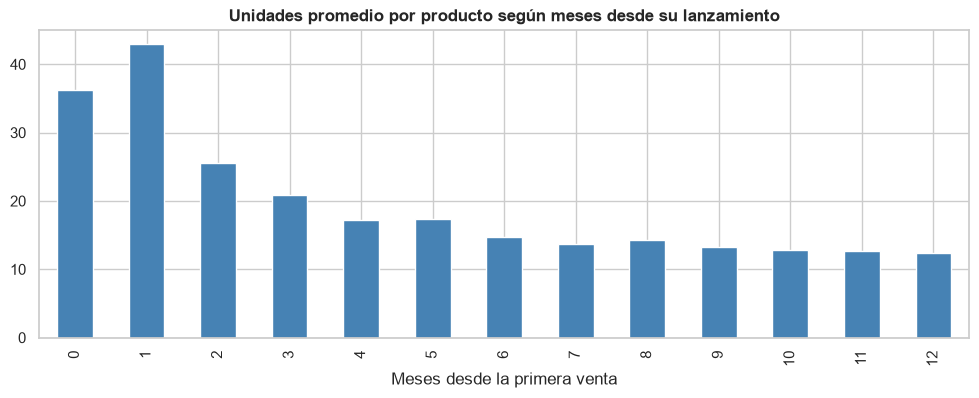

In [68]:
# ===== 10.a.2 Efecto de la "edad" del producto (meses desde su primera venta) =====
# Medimos las unidades promedio por producto según cuántos meses han pasado desde su lanzamiento en la cadena.
primer_mes_item = df.groupby("item_id")["date_block_num"].min()  # Mes de primera venta de cada producto
prod_mes["edad_meses"] = prod_mes["date_block_num"] - prod_mes["item_id"].map(primer_mes_item)  # Meses desde el lanzamiento
edad = prod_mes[prod_mes["item_id"].map(primer_mes_item) > 0]  # Excluimos productos ya existentes en el mes 0 (edad desconocida)
curva_edad = edad.groupby("edad_meses")["unidades"].mean().head(13)  # Promedio de unidades por edad (primer año)
print("Unidades promedio por producto según su edad (0 = mes de lanzamiento):")
print(curva_edad.round(1).to_string())
ax = curva_edad.plot(kind="bar", color="steelblue", figsize=(12, 4))  # Gráfica de la curva de vida
ax.set_title("Unidades promedio por producto según meses desde su lanzamiento")
ax.set_xlabel("Meses desde la primera venta")
plt.show()

In [69]:
# ===== 10.a.3 Peso de tienda, categoría y mes en la variabilidad de las ventas mensuales =====
# A nivel tienda-producto-mes, medimos qué tanto varía el promedio de unidades entre tiendas, familias y meses del año
# (razón entre el promedio máximo y mínimo de cada factor), como indicador simple de su influencia.
tpm = df.groupby(["shop_id", "item_id", "date_block_num"]).agg(unidades=("item_cnt_day", "sum")).reset_index()  # Tienda-producto-mes (target)
tpm = tpm.merge(items[["item_id", "item_category_id"]], on="item_id").merge(item_categories[["item_category_id", "familia"]], on="item_category_id")  # Agregamos familia
tpm["mes_anio"] = tpm["date_block_num"] % 12 + 1  # Mes del año (1-12)
print(f"Registros tienda-producto-mes con venta: {len(tpm):,}")
print(f"item_cnt_month: media={tpm['unidades'].mean():.2f}, mediana={tpm['unidades'].median():.0f}, "
      f"% de registros con 1 unidad={(tpm['unidades'] == 1).mean():.1%}, % > 20 unidades={(tpm['unidades'] > 20).mean():.2%}")
influencia = []  # Tabla de influencia por factor
for factor in ["shop_id", "familia", "mes_anio"]:  # Factores a evaluar
    prom = tpm.groupby(factor)["unidades"].mean()  # Promedio del target por nivel del factor
    influencia.append({"factor": factor, "niveles": len(prom), "prom_min": prom.min(), "prom_max": prom.max(), "razón_max_min": prom.max() / prom.min()})
pd.DataFrame(influencia)

Registros tienda-producto-mes con venta: 1,609,123
item_cnt_month: media=2.27, mediana=1, % de registros con 1 unidad=65.8%, % > 20 unidades=0.71%


,factor,niveles,prom_min,prom_max,razón_max_min
0,shop_id,57,1.28,9.97,7.80
1,familia,20,1.00,78.96,78.96
2,mes_anio,12,1.98,2.80,1.42


### 10.b Patrones útiles para el forecasting y cobertura de test.csv

In [70]:
# ===== 10.b.1 ¿Qué porcentaje de los pares tienda-producto de test tiene historial en train? =====
# Cruzamos los pares de test.csv con los pares que tuvieron alguna transacción en sales_train (tiendas ya unificadas).
pares_train = df[["shop_id", "item_id"]].drop_duplicates()  # Pares con historial
cobertura = test.merge(pares_train.assign(con_historial=True), on=["shop_id", "item_id"], how="left")  # Marcamos los pares con historial
cobertura["con_historial"] = cobertura["con_historial"].fillna(False).astype(bool)  # Sin coincidencia = sin historial
cobertura["item_conocido"] = cobertura["item_id"].isin(df["item_id"])  # ¿El producto se vendió en alguna tienda?
cobertura["tipo"] = np.select(  # Clasificación de cada par de test
    [cobertura["con_historial"], cobertura["item_conocido"]],
    ["Par con historial", "Producto conocido, nuevo en la tienda"],
    default="Producto nuevo (sin historial en ninguna tienda)",
)
print(f"Pares en test: {len(test):,} | tiendas: {test['shop_id'].nunique()} | productos: {test['item_id'].nunique():,}")
print(f"Tiendas de test sin historial en train: {set(test['shop_id']) - set(df['shop_id'])}")
resumen_cobertura = cobertura["tipo"].value_counts().to_frame("pares")  # Conteo por tipo
resumen_cobertura["porcentaje"] = resumen_cobertura["pares"] / len(cobertura) * 100  # Porcentaje sobre el total de test
resumen_cobertura

Pares en test: 214,200 | tiendas: 42 | productos: 5,100


Tiendas de test sin historial en train: set()


,pares,porcentaje
tipo,,
Par con historial,111471,52.04
"Producto conocido, nuevo en la tienda",87483,40.84
Producto nuevo (sin historial en ninguna tienda),15246,7.12


In [71]:
# ===== 10.b.2 Actividad reciente de los pares con historial =====
# Para los pares con historial, revisamos cuándo fue su última venta: los pares que dejaron de venderse hace tiempo
# probablemente tendrán venta cero en noviembre 2015.
ultimo_mes_par = df.groupby(["shop_id", "item_id"])["date_block_num"].max().rename("ultimo_mes").reset_index()  # Último mes con venta por par
hist = cobertura[cobertura["con_historial"]].merge(ultimo_mes_par, on=["shop_id", "item_id"])  # Pares de test con historial
print(f"Pares de test con venta en octubre 2015 (mes 33): {(hist['ultimo_mes'] == 33).sum():,} ({(hist['ultimo_mes'] == 33).sum() / len(test):.1%} del test)")
print(f"Pares con historial cuya última venta fue hace 6+ meses (mes <= 27): {(hist['ultimo_mes'] <= 27).sum():,}")
productos_nuevos = cobertura.loc[cobertura["tipo"].str.startswith("Producto nuevo"), "item_id"].unique()  # Productos sin ninguna venta
print(f"Productos nuevos en test: {len(productos_nuevos)}")
cat_nuevos = items[items["item_id"].isin(productos_nuevos)].merge(item_categories, on="item_category_id")["familia"].value_counts()  # Familias de los productos nuevos
print("Familias de los productos nuevos:")
print(cat_nuevos.to_string())

Pares de test con venta en octubre 2015 (mes 33): 28,680 (13.4% del test)
Pares con historial cuya última venta fue hace 6+ meses (mes <= 27): 36,978
Productos nuevos en test: 363
Familias de los productos nuevos:
familia
Cine                74
Regalos             67
Música              66
Juegos (consola)    45
Libros              44
Juegos PC           38
Programas           18
Consolas             6
Accesorios           2
PC (audífonos)       1
Juegos MAC           1
Tarjetas de pago     1


**10.a Variables que afectan directamente las ventas**
- **Categoría / familia del producto:** es el factor con mayor efecto. El promedio mensual por tienda-producto varía hasta
  **79 veces** entre familias (razón máx/mín), mucho más que entre tiendas (7.8 veces) o meses del año (1.4 veces). Cine, Juegos
  y Regalos concentran el volumen; Consolas y Juegos de consola concentran los ingresos.
- **Tienda:** el nivel de ventas depende mucho de la sucursal (grandes tiendas de Moscú vs. tiendas pequeñas, online y
  esporádicas). Además, la apertura o cierre de tiendas cambia la serie de forma estructural.
- **Antigüedad del producto (ciclo de vida):** un producto vende en promedio **36 unidades en su mes de lanzamiento y 43 en el
  siguiente**, y luego cae a ~17 al cuarto mes y ~12 al año. Lo nuevo vende mucho más.
- **Calendario:** diciembre (+61% en el promedio diario) y noviembre (+17%) en el año; sábado (+41%) y domingo (+17%) en la
  semana.
- **Precio:** su correlación con las unidades es débil (Spearman = 0.11 a nivel producto-mes). Los quintiles de precio más
  altos tienen promedios mayores (23 vs. 11 unidades) por los lanzamientos de videojuegos caros, pero medianas similares (3–5).
  El precio por sí solo no explica la demanda; está mezclado con la categoría y la novedad del producto.
- **Rezagos de la propia venta:** la venta del mes anterior es el mejor predictor individual (ACF/PACF en el rezago 1).

**10.b Patrones útiles para el forecasting**
- **Cobertura de `test.csv` (214,200 pares, 42 tiendas, 5,100 productos):**
  - **52.0% de los pares (111,471) tiene historial** de ventas en train para esa misma tienda-producto.
  - 40.8% (87,483) son productos ya vendidos en otras tiendas pero **nunca en esa tienda**.
  - **7.1% (15,246 pares) corresponden a 363 productos nuevos**, sin ninguna venta histórica (principalmente Cine, Regalos,
    Música, Juegos y Libros).
  - Las 42 tiendas de test tienen historial.
- **El test es una malla completa:** 42 tiendas × 5,100 productos = 214,200 combinaciones. Solo **13.4% de los pares (28,680)
  vendió algo en octubre 2015**, y 36,978 pares con historial no venden desde hace 6 meses o más. Se espera que **la mayoría de
  los pares tenga venta 0 en noviembre**, por lo que el conjunto de entrenamiento debe incluir explícitamente los pares
  tienda-producto con venta cero (no solo los que aparecen en `sales_train`).
- **La variable objetivo mensual está muy concentrada en valores bajos:** de 1,609,123 registros tienda-producto-mes con venta,
  el 65.8% es de 1 unidad (mediana = 1, media = 2.27) y solo el 0.71% supera las 20 unidades. Conviene **acotar (clip) los
  valores extremos** del objetivo para que unos pocos registros no dominen el entrenamiento.
- **Variables recomendadas para el modelo:**
  - Rezagos de 1, 2, 3 y 12 meses a nivel tienda-producto, producto, tienda y categoría.
  - Mes del año e indicador de diciembre.
  - Meses desde el lanzamiento del producto y meses desde su última venta.
  - Promedios por categoría (útiles para los productos nuevos).
  - Precio relativo del producto.
- **Tendencia y estructura:** la caída sostenida de unidades (−31% en la tendencia) y el desplazamiento entre categorías indican
  que los **meses recientes son más representativos**. Las tiendas cerradas y las familias que desaparecieron aportan poco al
  pronóstico de noviembre 2015.

**10.c Calidad y preparación del dataset**
- **Calidad general alta:**
  - Sin valores nulos y sin días faltantes a nivel cadena.
  - Fechas válidas y `date_block_num` 100% consistente.
  - Integridad referencial completa entre ventas y catálogos.
- **Problemas detectados y tratados en este EDA:**
  - 6 duplicados exactos eliminados.
  - 1 precio negativo imputado con la mediana del mismo producto, tienda y mes.
  - 3 pares de tiendas duplicadas unificados (0→57, 1→58, 11→10).
  - 2 outliers extremos eliminados (precio 307,980 y cantidad 2,169).
  - Las devoluciones (0.21% de las unidades) se conservan como parte de la venta neta.
- **Aspectos a considerar en la siguiente etapa:**
  - Productos con precios simbólicos (p. ej. 0.10 rublos).
  - Ítems que no son productos de venta regular (bolsas, servicios, entregas).
  - Tiendas especiales (online, almacén digital, itinerante, liquidación).
  - Los nombres originales están en ruso. Aquí se tradujeron al español: tiendas y categorías de forma manual, y productos con
    traducción automática, que puede traducir de forma literal algunos títulos propios.
- **Preparación:** el dataset está listo para construir la **matriz mensual tienda-producto** (incluyendo ceros) con las
  variables de rezago, calendario y ciclo de vida descritas arriba, que será la base de la etapa de *forecasting* de
  noviembre 2015.